# Exploratory Data Analysis — Non-Graphical

Installs/loads skimr, psych, DataExplorer, janitor, caret

In [ ]:
required_pkgs <- c("skimr", "psych", "DataExplorer", "janitor", "caret","VIM","mice")
new_pkgs <- required_pkgs[!(required_pkgs %in% installed.packages()[, "Package"])]
if (length(new_pkgs)) install.packages(new_pkgs)

library(skimr)
library(psych)
library(DataExplorer)
library(janitor)
library(caret)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘matrixStats’, ‘ucminf’, ‘nanonext’, ‘PRROC’, ‘moocore’, ‘ordinal’, ‘DEoptimR’, ‘checkmate’, ‘lgr’, ‘mirai’, ‘mlbench’, ‘mlr3measures’, ‘mlr3misc’, ‘palmerpenguins’, ‘bbotk’, ‘pan’, ‘jomo’, ‘robustbase’, ‘sp’, ‘vcd’, ‘laeken’, ‘ranger’, ‘xgboost’, ‘mlr3’, ‘mlr3pipelines’, ‘paradox’, ‘mlr3tuning’, ‘mlr3learners’, ‘glmnet’, ‘mitml’


Warning message in install.packages(new_pkgs):
“installation of package ‘xgboost’ had non-zero exit status”
Warning message in install.packages(new_pkgs):
“installation of package ‘glmnet’ had non-zero exit status”
Warning message in install.packages(new_pkgs):
“installation of package ‘mice’ had non-zero exit status”
Warning message in install.packages(new_pkgs):
“installation of package ‘VIM’ had non-zero exit status”


Loads alz_clean.csv, converts categorical columns to factors

In [ ]:
df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)
cat_cols <- c("gender", "ethnicity", "education_level", "smoking",
              "family_history_alzheimers", "cardiovascular_disease",
              "diabetes", "depression", "head_injury", "hypertension",
              "memory_complaints", "behavioral_problems", "confusion",
              "disorientation", "personality_changes",
              "difficulty_completing_tasks", "forgetfulness", "diagnosis")

df[cat_cols] <- lapply(df[cat_cols], factor)


str(df) — structure/data types


In [ ]:
str(df)

'data.frame':	2149 obs. of  34 variables:
 $ patient_id                 : int  4751 4752 4753 4754 4755 4756 4757 4758 4759 4760 ...
 $ age                        : int  73 89 73 74 89 86 68 75 72 87 ...
 $ gender                     : Factor w/ 2 levels "0","1": 1 1 1 2 1 2 1 1 2 1 ...
 $ ethnicity                  : Factor w/ 4 levels "0","1","2","3": 1 1 4 1 1 2 4 1 2 1 ...
 $ education_level            : Factor w/ 4 levels "0","1","2","3": 3 1 2 2 1 2 3 2 1 1 ...
 $ bmi                        : num  22.9 26.8 17.8 33.8 20.7 ...
 $ smoking                    : Factor w/ 2 levels "0","1": 1 1 1 2 1 1 2 1 1 2 ...
 $ alcohol_consumption        : num  13.3 4.54 19.56 12.21 18.45 ...
 $ physical_activity          : num  6.33 7.62 7.84 8.43 6.31 ...
 $ diet_quality               : num  1.347 0.519 1.826 7.436 0.795 ...
 $ sleep_quality              : num  9.03 7.15 9.67 8.39 5.6 ...
 $ family_history_alzheimers  : Factor w/ 2 levels "0","1": 1 1 2 1 1 1 1 1 1 1 ...
 $ cardiovascular_disea

summary stats per column

In [ ]:
summary(df)

   patient_id        age        gender   ethnicity education_level
 Min.   :4751   Min.   :60.00   0:1061   0:1278    0:446          
 1st Qu.:5288   1st Qu.:67.00   1:1088   1: 454    1:854          
 Median :5825   Median :75.00            2: 206    2:636          
 Mean   :5825   Mean   :74.91            3: 211    3:213          
 3rd Qu.:6362   3rd Qu.:83.00                                     
 Max.   :6899   Max.   :90.00                                     
      bmi        smoking  alcohol_consumption physical_activity 
 Min.   :15.01   0:1529   Min.   : 0.002003   Min.   :0.003616  
 1st Qu.:21.61   1: 620   1st Qu.: 5.139810   1st Qu.:2.570626  
 Median :27.82            Median : 9.934412   Median :4.766424  
 Mean   :27.66            Mean   :10.039442   Mean   :4.920202  
 3rd Qu.:33.87            3rd Qu.:15.157931   3rd Qu.:7.427899  
 Max.   :39.99            Max.   :19.989293   Max.   :9.987429  
  diet_quality      sleep_quality    family_history_alzheimers
 Min.   :0.00

dataset shape

In [ ]:
dim(df)
nrow(df)
ncol(df)

[1] 2149   34

[1] 2149

[1] 34

first/last 5 rows

In [ ]:
head(df, 5)
tail(df, 5)


,patient_id,age,gender,ethnicity,education_level,bmi,smoking,alcohol_consumption,physical_activity,diet_quality,⋯,functional_assessment,memory_complaints,behavioral_problems,adl,confusion,disorientation,personality_changes,difficulty_completing_tasks,forgetfulness,diagnosis
,<int>,<int>,<fct>,<fct>,<fct>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
1,4751,73,0,0,2,22.92775,0,13.297218,6.327112,1.3472143,⋯,6.518877,0,0,1.72588346,0,0,0,1,0,0
2,4752,89,0,0,0,26.82768,0,4.542524,7.619885,0.5187671,⋯,7.118696,0,0,2.59242413,0,0,0,0,1,0
3,4753,73,0,3,1,17.79588,0,19.555085,7.844988,1.8263347,⋯,5.895077,0,0,7.11954774,0,1,0,1,0,0
4,4754,74,1,0,1,33.80082,1,12.209266,8.428001,7.4356041,⋯,8.965106,0,1,6.48122586,0,0,0,0,0,0
5,4755,89,0,0,0,20.71697,0,18.454356,6.310461,0.7954975,⋯,6.045039,0,0,0.01469122,0,0,1,1,0,0


,patient_id,age,gender,ethnicity,education_level,bmi,smoking,alcohol_consumption,physical_activity,diet_quality,⋯,functional_assessment,memory_complaints,behavioral_problems,adl,confusion,disorientation,personality_changes,difficulty_completing_tasks,forgetfulness,diagnosis
,<int>,<int>,<fct>,<fct>,<fct>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
2145,6895,61,0,0,1,39.12176,0,1.561126,4.049964,6.555306,⋯,0.238667,0,0,4.492838,1,0,0,0,0,1
2146,6896,75,0,0,2,17.85790,0,18.767261,1.360667,2.904662,⋯,8.687480,0,1,9.204952,0,0,0,0,0,1
2147,6897,77,0,0,1,15.47648,0,4.594670,9.886002,8.120025,⋯,1.972137,0,0,5.036334,0,0,0,0,0,1
2148,6898,78,1,3,1,15.29991,0,8.674505,6.354282,1.263427,⋯,5.173891,0,0,3.785399,0,0,0,0,1,1
2149,6899,72,0,0,2,33.28974,0,7.890703,6.570993,7.941404,⋯,6.307543,0,1,8.327563,0,1,0,0,1,0


column types

In [ ]:
sapply(df, class)

patient_id                         age 
                  "integer"                   "integer" 
                     gender                   ethnicity 
                   "factor"                    "factor" 
            education_level                         bmi 
                   "factor"                   "numeric" 
                    smoking         alcohol_consumption 
                   "factor"                   "numeric" 
          physical_activity                diet_quality 
                  "numeric"                   "numeric" 
              sleep_quality   family_history_alzheimers 
                  "numeric"                    "factor" 
     cardiovascular_disease                    diabetes 
                   "factor"                    "factor" 
                 depression                 head_injury 
                   "factor"                    "factor" 
               hypertension                 systolic_bp 
                   "factor"                   "integer" 
               diastolic_bp           cholesterol_total 
                  "integer"                   "numeric" 
            cholesterol_ldl             cholesterol_hdl 
                  "numeric"                   "numeric" 
  cholesterol_triglycerides                        mmse 
                  "numeric"                   "numeric" 
      functional_assessment           memory_complaints 
                  "numeric"                    "factor" 
        behavioral_problems                         adl 
                   "factor"                   "numeric" 
                  confusion              disorientation 
                   "factor"                    "factor" 
        personality_changes difficulty_completing_tasks 
                   "factor"                    "factor" 
              forgetfulness                   diagnosis 
                   "factor"                    "factor"

Missing value counts and percentages per column

In [ ]:
colSums(is.na(df))
round(colMeans(is.na(df)) * 100, 2)


patient_id                         age 
                          0                           0 
                     gender                   ethnicity 
                          0                           0 
            education_level                         bmi 
                          0                           0 
                    smoking         alcohol_consumption 
                          0                           0 
          physical_activity                diet_quality 
                          0                           0 
              sleep_quality   family_history_alzheimers 
                          0                           0 
     cardiovascular_disease                    diabetes 
                          0                           0 
                 depression                 head_injury 
                          0                           0 
               hypertension                 systolic_bp 
                          0                           0 
               diastolic_bp           cholesterol_total 
                          0                           0 
            cholesterol_ldl             cholesterol_hdl 
                          0                           0 
  cholesterol_triglycerides                        mmse 
                          0                           0 
      functional_assessment           memory_complaints 
                          0                           0 
        behavioral_problems                         adl 
                          0                           0 
                  confusion              disorientation 
                          0                           0 
        personality_changes difficulty_completing_tasks 
                          0                           0 
              forgetfulness                   diagnosis 
                          0                           0

patient_id                         age 
                          0                           0 
                     gender                   ethnicity 
                          0                           0 
            education_level                         bmi 
                          0                           0 
                    smoking         alcohol_consumption 
                          0                           0 
          physical_activity                diet_quality 
                          0                           0 
              sleep_quality   family_history_alzheimers 
                          0                           0 
     cardiovascular_disease                    diabetes 
                          0                           0 
                 depression                 head_injury 
                          0                           0 
               hypertension                 systolic_bp 
                          0                           0 
               diastolic_bp           cholesterol_total 
                          0                           0 
            cholesterol_ldl             cholesterol_hdl 
                          0                           0 
  cholesterol_triglycerides                        mmse 
                          0                           0 
      functional_assessment           memory_complaints 
                          0                           0 
        behavioral_problems                         adl 
                          0                           0 
                  confusion              disorientation 
                          0                           0 
        personality_changes difficulty_completing_tasks 
                          0                           0 
              forgetfulness                   diagnosis 
                          0                           0

Unique value counts per column (cardinality check)

In [ ]:
sapply(df, function(x) length(unique(x)))

patient_id                         age 
                       2149                          31 
                     gender                   ethnicity 
                          2                           4 
            education_level                         bmi 
                          4                        2149 
                    smoking         alcohol_consumption 
                          2                        2149 
          physical_activity                diet_quality 
                       2149                        2149 
              sleep_quality   family_history_alzheimers 
                       2149                           2 
     cardiovascular_disease                    diabetes 
                          2                           2 
                 depression                 head_injury 
                          2                           2 
               hypertension                 systolic_bp 
                          2                          90 
               diastolic_bp           cholesterol_total 
                         60                        2149 
            cholesterol_ldl             cholesterol_hdl 
                       2149                        2149 
  cholesterol_triglycerides                        mmse 
                       2149                        2149 
      functional_assessment           memory_complaints 
                       2149                           2 
        behavioral_problems                         adl 
                          2                        2149 
                  confusion              disorientation 
                          2                           2 
        personality_changes difficulty_completing_tasks 
                          2                           2 
              forgetfulness                   diagnosis 
                          2                           2

Frequency tables for diagnosis, gender, smoking

In [ ]:
table(df$diagnosis)
prop.table(table(df$diagnosis)) * 100   # percentages

table(df$gender)
table(df$smoking)


   0    1 
1389  760 


       0        1 
64.63471 35.36529 


   0    1 
1061 1088 


   0    1 
1529  620 

Cross-tabs of gender/smoking vs diagnosis, with margins and row percentages

In [ ]:
table(df$gender, df$diagnosis)
table(df$smoking, df$diagnosis)


addmargins(table(df$gender, df$diagnosis))
prop.table(table(df$gender, df$diagnosis), margin = 1) * 100

   
      0   1
  0 675 386
  1 714 374

   
      0   1
  0 986 543
  1 403 217

,0,1,Sum
0,675,386,1061
1,714,374,1088
Sum,1389,760,2149


   
           0        1
  0 63.61923 36.38077
  1 65.62500 34.37500

aggregate() of mmse/bmi/functional_assessment by group

In [ ]:
aggregate(mmse ~ diagnosis, data = df, FUN = mean)
aggregate(mmse ~ diagnosis, data = df, FUN = summary)

aggregate(bmi ~ gender, data = df, FUN = mean)

# tapply alternative
tapply(df$functional_assessment, df$diagnosis, summary)

diagnosis,mmse
<fct>,<dbl>
0,16.26554
1,11.99466


diagnosis,mmse
<fct>,"<dbl[,6]>"
0,"0.005312146, 8.545490, 17.14580, 16.26554, 24.59571, 29.99138"
1,"0.050623512, 6.040483, 11.56583, 11.99466, 18.15199, 29.95942"


gender,bmi
<fct>,<dbl>
0,27.61238
1,27.69794


$`0`
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0119  3.8506  6.2443  5.8607  8.1213  9.9965 

$`1`
     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
0.0004596 1.5768683 3.2990599 3.6533800 4.9207100 9.9279453 


rich summary via skimr

In [ ]:
skim(df)

,skim_type,skim_variable,n_missing,complete_rate,factor.ordered,factor.n_unique,factor.top_counts,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<lgl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,factor,gender,0,1,FALSE,2,"1: 1088, 0: 1061",NA,NA,NA,NA,NA,NA,NA,NA
2,factor,ethnicity,0,1,FALSE,4,"0: 1278, 1: 454, 3: 211, 2: 206",NA,NA,NA,NA,NA,NA,NA,NA
3,factor,education_level,0,1,FALSE,4,"1: 854, 2: 636, 0: 446, 3: 213",NA,NA,NA,NA,NA,NA,NA,NA
4,factor,smoking,0,1,FALSE,2,"0: 1529, 1: 620",NA,NA,NA,NA,NA,NA,NA,NA
5,factor,family_history_alzheimers,0,1,FALSE,2,"0: 1607, 1: 542",NA,NA,NA,NA,NA,NA,NA,NA
6,factor,cardiovascular_disease,0,1,FALSE,2,"0: 1839, 1: 310",NA,NA,NA,NA,NA,NA,NA,NA
7,factor,diabetes,0,1,FALSE,2,"0: 1825, 1: 324",NA,NA,NA,NA,NA,NA,NA,NA
8,factor,depression,0,1,FALSE,2,"0: 1718, 1: 431",NA,NA,NA,NA,NA,NA,NA,NA
9,factor,head_injury,0,1,FALSE,2,"0: 1950, 1: 199",NA,NA,NA,NA,NA,NA,NA,NA


psych package descriptive stats (numeric only)

In [ ]:
describe(df)
numeric_cols <- sapply(df, is.numeric)
describe(df[, numeric_cols])

,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
patient_id,1,2149,5825.000000,620.5071850,5825.000000,5825.000000,796.156200,4.751000e+03,6899.000000,2148.000000,0.000000000,-1.20167533,13.385315337
age,2,2149,74.908795,8.9902214,75.000000,74.876816,11.860800,6.000000e+01,90.000000,30.000000,0.045900194,-1.19092439,0.193933206
gender*,3,2149,1.506282,0.5000769,2.000000,1.507844,0.000000,1.000000e+00,2.000000,1.000000,-0.025112411,-2.00029952,0.010787445
ethnicity*,4,2149,1.697534,0.9961277,1.000000,1.499709,0.000000,1.000000e+00,4.000000,3.000000,1.228498408,0.22754855,0.021488041
education_level*,5,2149,2.286645,0.9045269,2.000000,2.234166,1.482600,1.000000e+00,4.000000,3.000000,0.208826653,-0.75585177,0.019512066
bmi,6,2149,27.655697,7.2174381,27.823924,27.689867,9.140315,1.500885e+01,39.992767,24.983916,-0.026677309,-1.18623371,0.155691484
smoking*,7,2149,1.288506,0.4531732,1.000000,1.235909,0.000000,1.000000e+00,2.000000,1.000000,0.932955841,-1.13011863,0.009775659
alcohol_consumption,8,2149,10.039442,5.7579103,9.934412,10.033322,7.431710,2.003099e-03,19.989293,19.987290,0.018388868,-1.20454163,0.124207176
physical_activity,9,2149,4.920202,2.8571911,4.766424,4.905985,3.577668,3.616017e-03,9.987429,9.983813,0.044909832,-1.18093951,0.061634104


,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
patient_id,1,2149,5825.000000,620.507185,5825.000000,5825.000000,796.156200,4.751000e+03,6899.000000,2148.000000,0.000000000,-1.201675,13.38531534
age,2,2149,74.908795,8.990221,75.000000,74.876816,11.860800,6.000000e+01,90.000000,30.000000,0.045900194,-1.190924,0.19393321
bmi,3,2149,27.655697,7.217438,27.823924,27.689867,9.140315,1.500885e+01,39.992767,24.983916,-0.026677309,-1.186234,0.15569148
alcohol_consumption,4,2149,10.039442,5.757910,9.934412,10.033322,7.431710,2.003099e-03,19.989293,19.987290,0.018388868,-1.204542,0.12420718
physical_activity,5,2149,4.920202,2.857191,4.766424,4.905985,3.577668,3.616017e-03,9.987429,9.983813,0.044909832,-1.180940,0.06163410
diet_quality,6,2149,4.993138,2.909055,5.076087,4.994679,3.768415,9.384720e-03,9.998346,9.988961,-0.012040923,-1.230543,0.06275289
sleep_quality,7,2149,7.051081,1.763573,7.115646,7.064023,2.284256,4.002629e+00,9.999840,5.997212,-0.069533080,-1.214088,0.03804304
systolic_bp,8,2149,134.264774,25.949352,134.000000,134.209181,34.099800,9.000000e+01,179.000000,89.000000,0.009957127,-1.199276,0.55976831
diastolic_bp,9,2149,89.847836,17.592496,91.000000,89.958164,22.239000,6.000000e+01,119.000000,59.000000,-0.054393925,-1.236602,0.37949780


Correlation matrix of numeric columns, sorted by correlation with mmse

In [ ]:
cor_matrix <- cor(df[, numeric_cols], use = "pairwise.complete.obs")
round(cor_matrix, 2)

# Optional: sorted correlations with mmse
sort(cor_matrix["mmse", ], decreasing = TRUE)

,patient_id,age,bmi,alcohol_consumption,physical_activity,diet_quality,sleep_quality,systolic_bp,diastolic_bp,cholesterol_total,cholesterol_ldl,cholesterol_hdl,cholesterol_triglycerides,mmse,functional_assessment,adl
patient_id,1.00,0.00,-0.03,-0.02,-0.01,-0.02,-0.03,-0.02,-0.01,0.00,-0.02,-0.01,0.01,-0.01,0.03,-0.02
age,0.00,1.00,-0.02,0.01,-0.01,-0.02,0.05,-0.01,0.00,0.00,0.00,0.01,0.00,0.00,0.01,-0.04
bmi,-0.03,-0.02,1.00,-0.01,0.00,0.02,-0.01,-0.02,0.00,0.00,0.02,0.04,-0.02,0.00,-0.03,-0.01
alcohol_consumption,-0.02,0.01,-0.01,1.00,0.02,0.02,0.00,-0.03,-0.01,-0.03,-0.02,0.00,0.02,-0.01,-0.02,-0.01
physical_activity,-0.01,-0.01,0.00,0.02,1.00,0.01,0.00,0.00,-0.01,0.01,0.02,0.00,0.03,-0.01,0.00,-0.01
diet_quality,-0.02,-0.02,0.02,0.02,0.01,1.00,0.05,0.01,0.01,-0.02,-0.02,-0.01,0.03,0.02,-0.01,-0.01
sleep_quality,-0.03,0.05,-0.01,0.00,0.00,0.05,1.00,-0.03,0.01,0.01,0.01,0.02,0.02,0.01,0.03,0.01
systolic_bp,-0.02,-0.01,-0.02,-0.03,0.00,0.01,-0.03,1.00,0.00,0.02,-0.01,0.00,-0.03,0.00,0.01,0.02
diastolic_bp,-0.01,0.00,0.00,-0.01,-0.01,0.01,0.01,0.00,1.00,0.02,-0.02,0.01,-0.01,-0.03,0.03,0.00
cholesterol_total,0.00,0.00,0.00,-0.03,0.01,-0.02,0.01,0.02,0.02,1.00,0.01,0.01,0.00,-0.01,-0.01,0.00


mmse           cholesterol_ldl     functional_assessment 
              1.000000000               0.025382647               0.024932154 
             diet_quality             sleep_quality                       adl 
              0.021636408               0.012506135               0.003358908 
                      bmi               systolic_bp                       age 
             -0.003476707              -0.003548332              -0.004234771 
          cholesterol_hdl                patient_id cholesterol_triglycerides 
             -0.005218421              -0.006777152              -0.007614641 
        physical_activity       alcohol_consumption         cholesterol_total 
             -0.008342257              -0.011423990              -0.013638030 
             diastolic_bp 
             -0.028585990

nearZeroVar() — flags near-constant (low-information) columns

In [ ]:
nzv <- nearZeroVar(df, saveMetrics = TRUE)
nzv
# Columns flagged as near-zero variance
rownames(nzv[nzv$nzv == TRUE, ])


,freqRatio,percentUnique,zeroVar,nzv
,<dbl>,<dbl>,<lgl>,<lgl>
patient_id,1.000000,100.00000000,FALSE,FALSE
age,1.000000,1.44253141,FALSE,FALSE
gender,1.025448,0.09306654,FALSE,FALSE
ethnicity,2.814978,0.18613309,FALSE,FALSE
education_level,1.342767,0.18613309,FALSE,FALSE
bmi,2.000000,99.95346673,FALSE,FALSE
smoking,2.466129,0.09306654,FALSE,FALSE
alcohol_consumption,1.000000,100.00000000,FALSE,FALSE
physical_activity,1.000000,100.00000000,FALSE,FALSE


character(0)

# Exploratory Data Analysis — Graphical



Installs/loads ggplot2, GGally, ggridges, naniar, reshape2, dplyr, scales

In [ ]:
required_pkgs <- c("ggplot2", "GGally", "ggridges", "naniar",
                    "reshape2", "dplyr", "scales")
new_pkgs <- required_pkgs[!(required_pkgs %in% installed.packages()[, "Package"])]
if (length(new_pkgs)) install.packages(new_pkgs)

library(ggplot2)
library(GGally)
library(ggridges)
library(naniar)
library(reshape2)
library(dplyr)
library(scales)


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘patchwork’, ‘ggstats’, ‘norm’, ‘visdat’, ‘viridis’, ‘UpSetR’



Attaching package: ‘naniar’


The following object is masked from ‘package:skimr’:

    n_complete



Attaching package: ‘reshape2’


The following objects are masked from ‘package:data.table’:

    dcast, melt



Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘scales’


The following objects are masked from ‘package:psych’:

    alpha, rescale




Creates readable factor labels (diagnosis_lbl, gender_lbl), sets ggplot theme

In [ ]:
df$diagnosis_lbl <- factor(df$diagnosis, labels = c("No Alzheimer's", "Alzheimer's"))
df$gender_lbl <- factor(df$gender, labels = c("Male", "Female"))

theme_set(theme_minimal(base_size = 12))


Histogram of MMSE scores

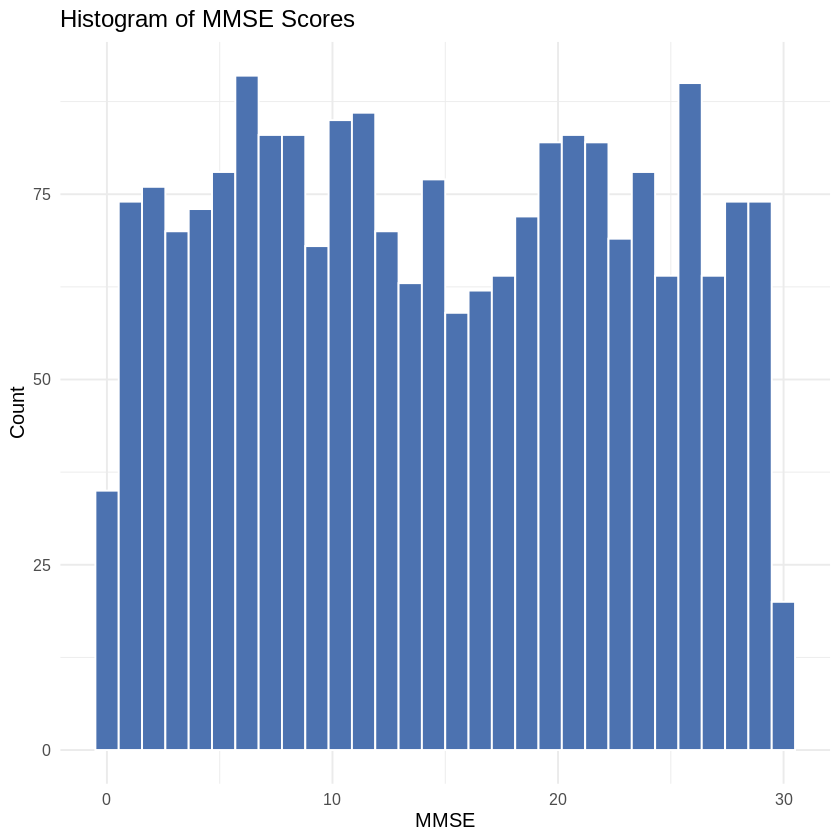

In [ ]:
ggplot(df, aes(x = mmse)) +
  geom_histogram(bins = 30, fill = "#4C72B0", color = "white") +
  labs(title = "Histogram of MMSE Scores", x = "MMSE", y = "Count")


Density plot of MMSE by diagnosis

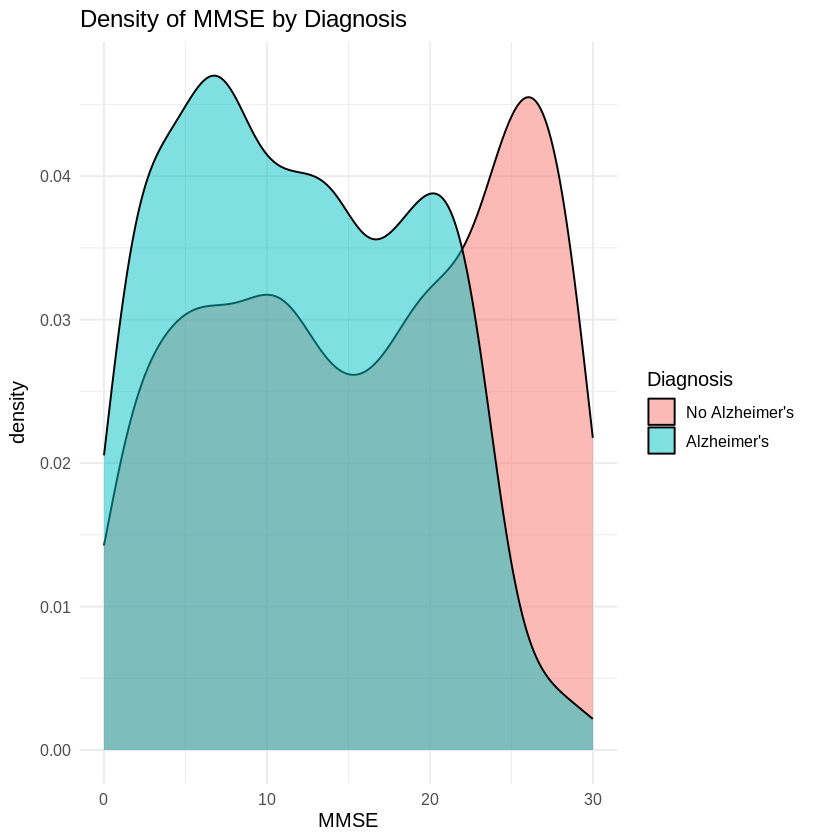

In [ ]:
ggplot(df, aes(x = mmse, fill = diagnosis_lbl)) +
  geom_density(alpha = 0.5) +
  labs(title = "Density of MMSE by Diagnosis", x = "MMSE", fill = "Diagnosis")


Boxplot of BMI by diagnosis

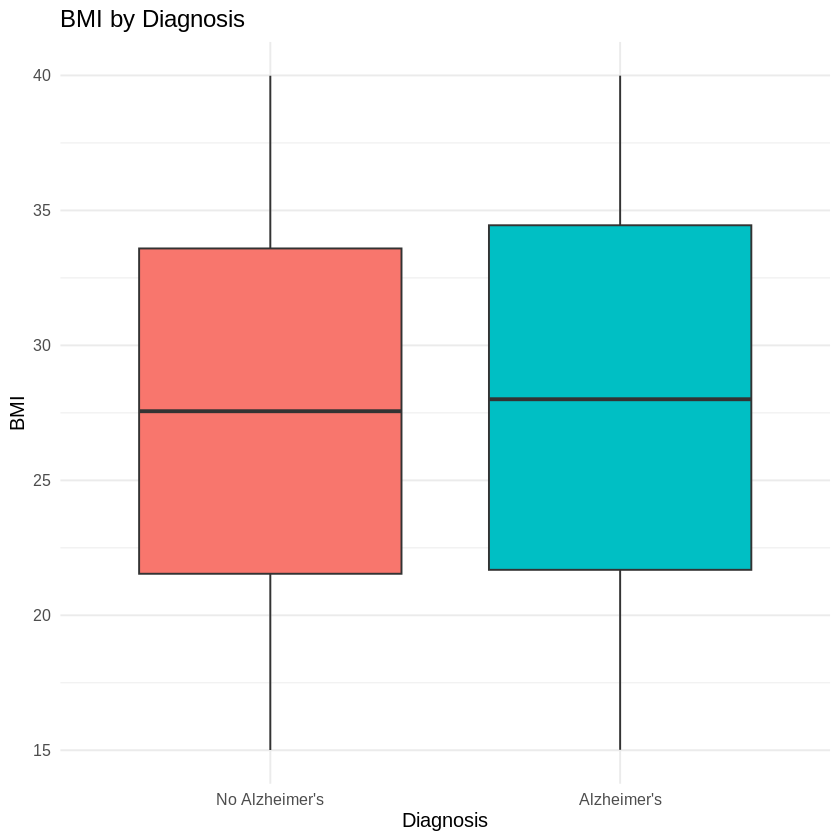

In [ ]:
ggplot(df, aes(x = diagnosis_lbl, y = bmi, fill = diagnosis_lbl)) +
  geom_boxplot() +
  labs(title = "BMI by Diagnosis", x = "Diagnosis", y = "BMI") +
  theme(legend.position = "none")


Violin+boxplot of functional assessment by diagnosis

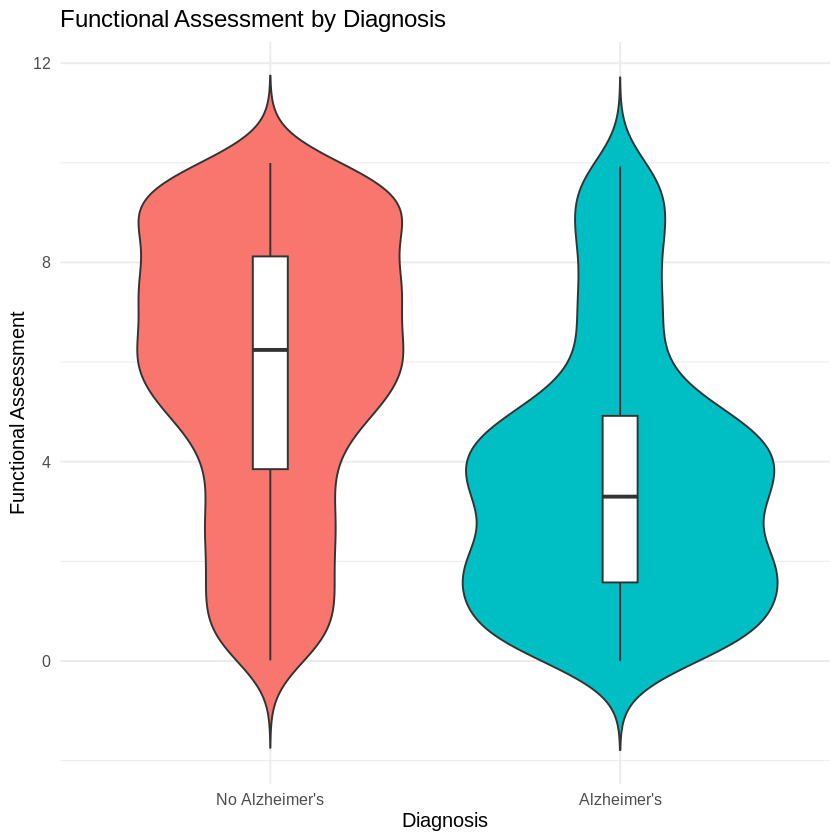

In [ ]:
ggplot(df, aes(x = diagnosis_lbl, y = functional_assessment, fill = diagnosis_lbl)) +
  geom_violin(trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white") +
  labs(title = "Functional Assessment by Diagnosis", x = "Diagnosis", y = "Functional Assessment") +
  theme(legend.position = "none")


Scatter + regression line: systolic vs diastolic BP

`geom_smooth()` using formula = 'y ~ x'


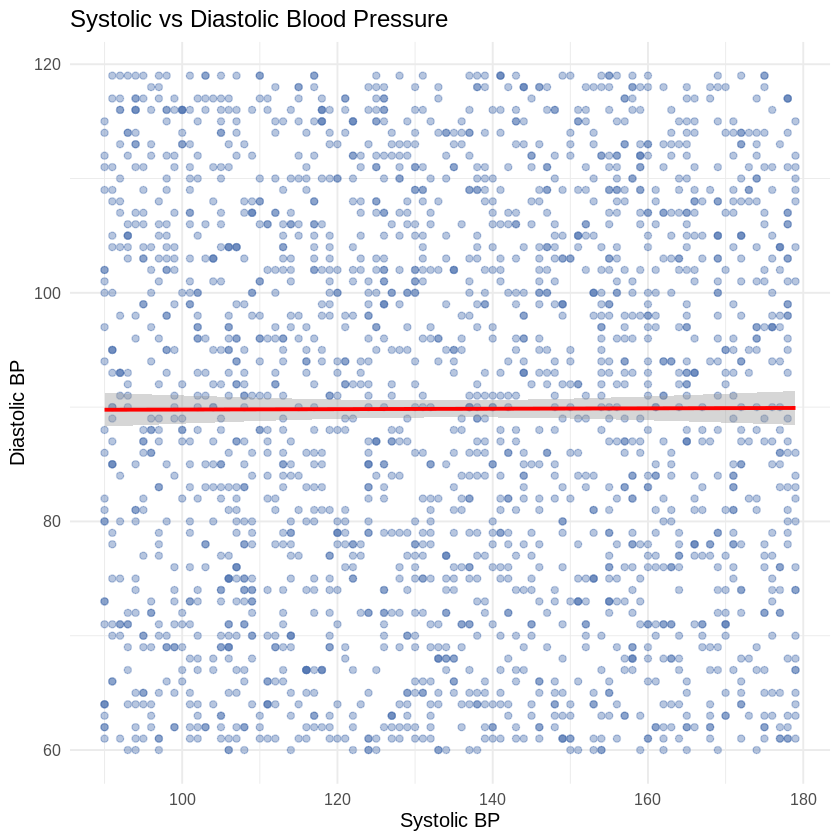

In [ ]:
ggplot(df, aes(x = systolic_bp, y = diastolic_bp)) +
  geom_point(alpha = 0.4, color = "#4C72B0") +
  geom_smooth(method = "lm", color = "red", se = TRUE) +
  labs(title = "Systolic vs Diastolic Blood Pressure", x = "Systolic BP", y = "Diastolic BP")

Bar chart of diagnosis frequency

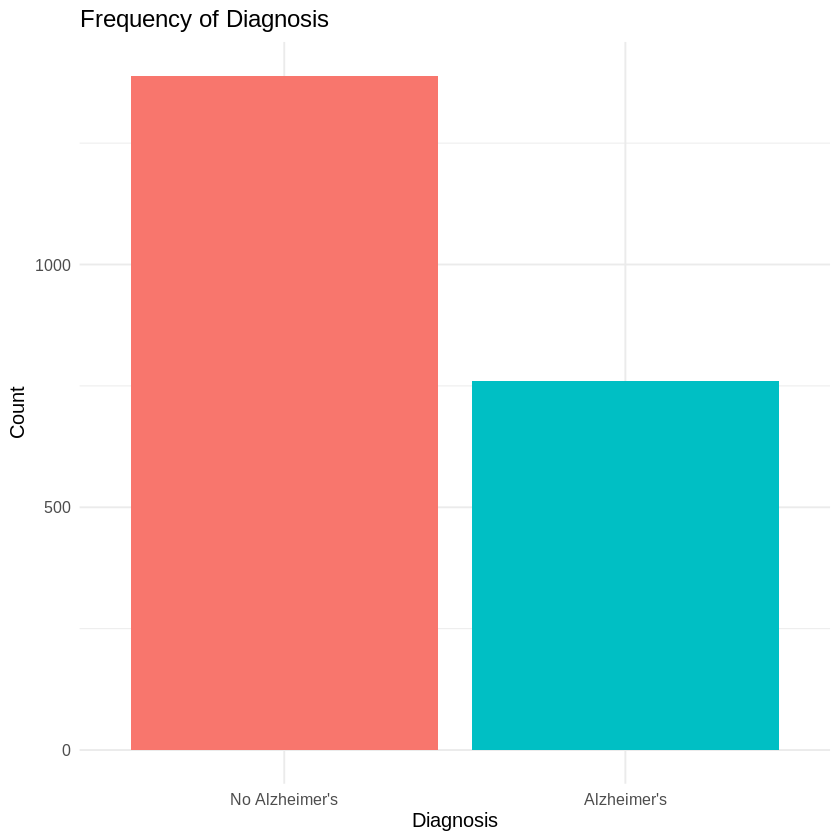

In [ ]:
ggplot(df, aes(x = diagnosis_lbl, fill = diagnosis_lbl)) +
  geom_bar() +
  labs(title = "Frequency of Diagnosis", x = "Diagnosis", y = "Count") +
  theme(legend.position = "none")

Pie chart of gender proportion

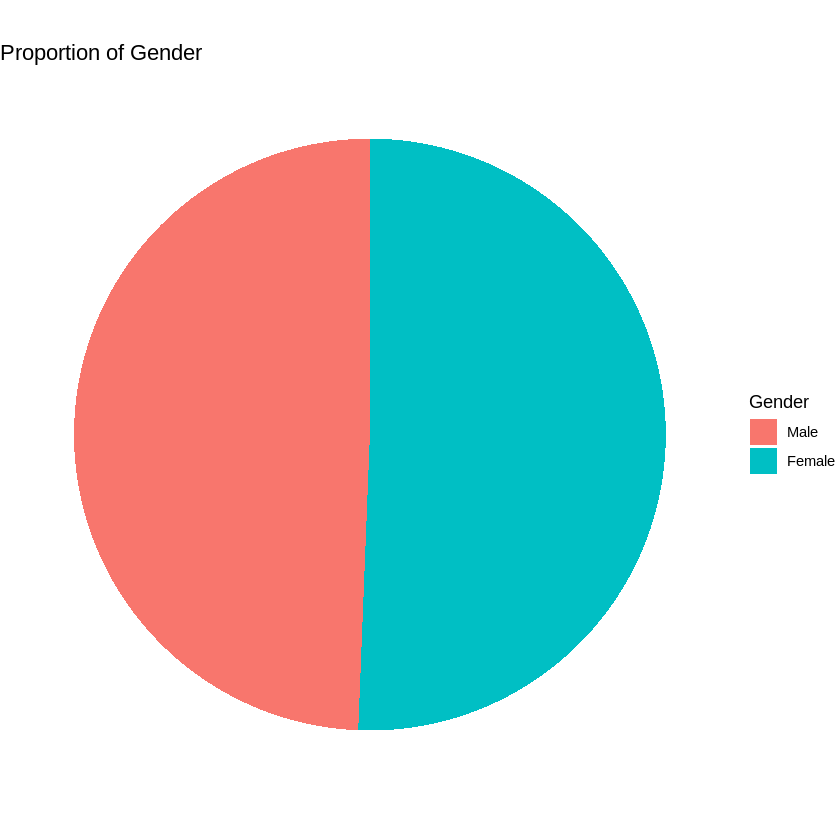

In [ ]:
gender_counts <- df %>% count(gender_lbl)
ggplot(gender_counts, aes(x = "", y = n, fill = gender_lbl)) +
  geom_col(width = 1) +
  coord_polar(theta = "y") +
  labs(title = "Proportion of Gender", fill = "Gender") +
  theme_void()


Correlation heatmap (melted matrix + tile plot)

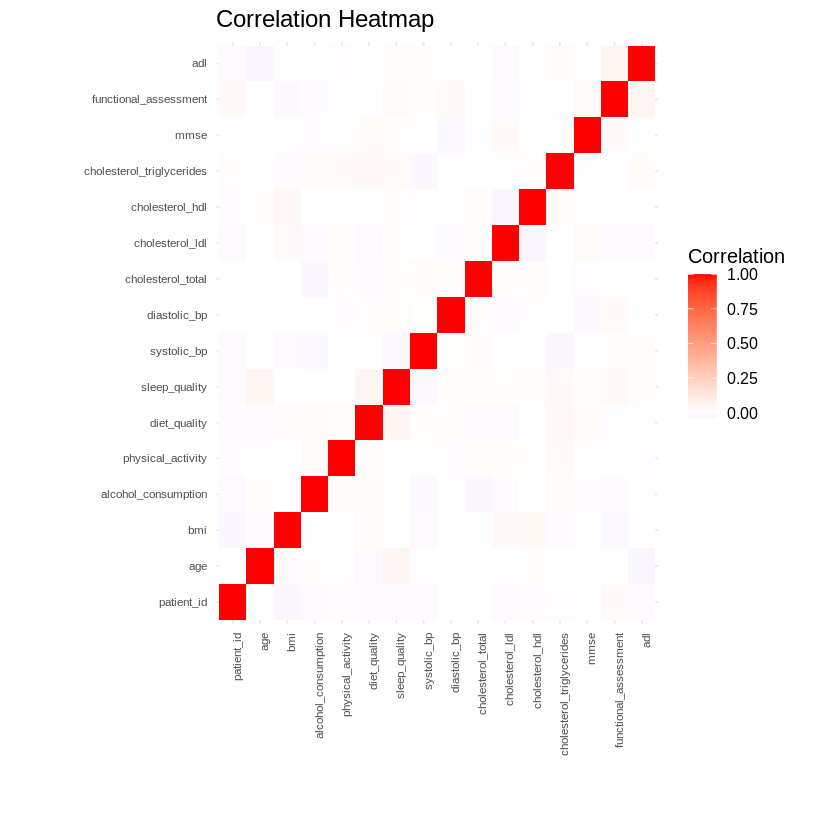

In [ ]:
numeric_cols <- sapply(df, is.numeric)
cor_matrix <- cor(df[, numeric_cols], use = "pairwise.complete.obs")
cor_melt <- melt(cor_matrix)

ggplot(cor_melt, aes(x = Var1, y = Var2, fill = value)) +
  geom_tile() +
  scale_fill_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  labs(title = "Correlation Heatmap", x = "", y = "", fill = "Correlation") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, size = 7),
        axis.text.y = element_text(size = 7))


ggpairs() pair plot of key clinical variables colored by diagnosis

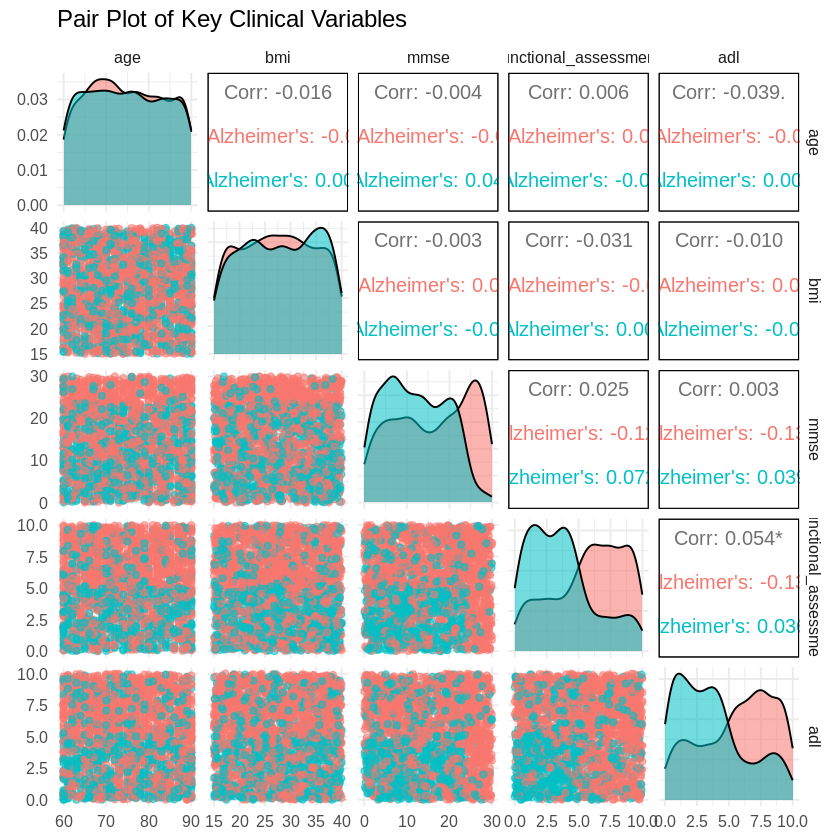

In [ ]:
key_vars <- c("age", "bmi", "mmse", "functional_assessment", "adl")
ggpairs(df, columns = key_vars, aes(color = diagnosis_lbl, alpha = 0.5)) +
  labs(title = "Pair Plot of Key Clinical Variables")


QQ-plot of total cholesterol

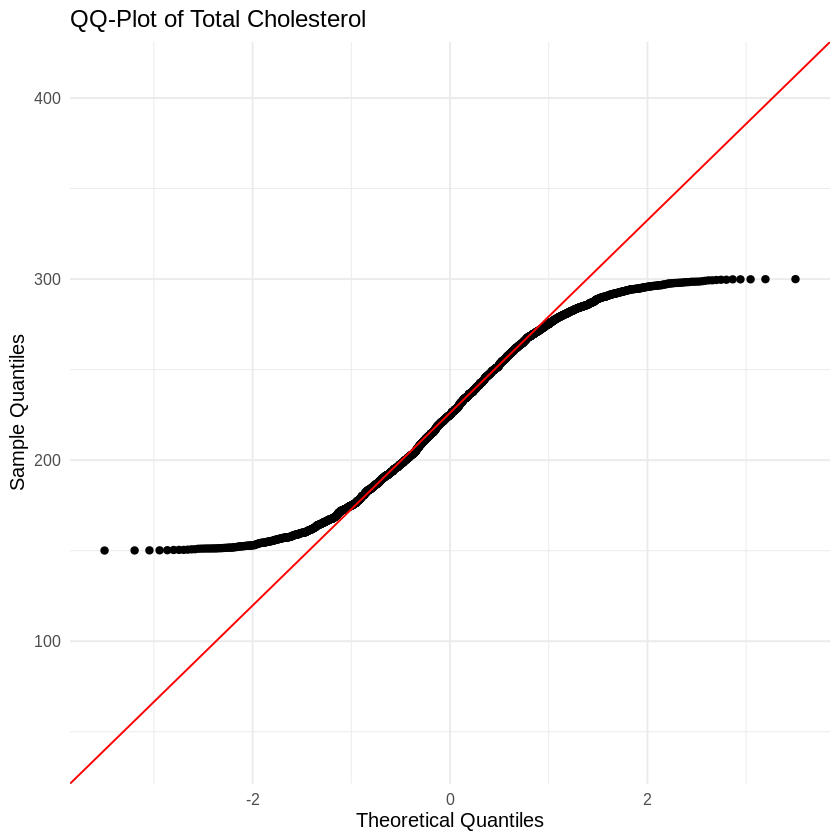

In [ ]:
ggplot(df, aes(sample = cholesterol_total)) +
  stat_qq() +
  stat_qq_line(color = "red") +
  labs(title = "QQ-Plot of Total Cholesterol", x = "Theoretical Quantiles", y = "Sample Quantiles")

Stacked proportion bar chart: smoking status by diagnosis

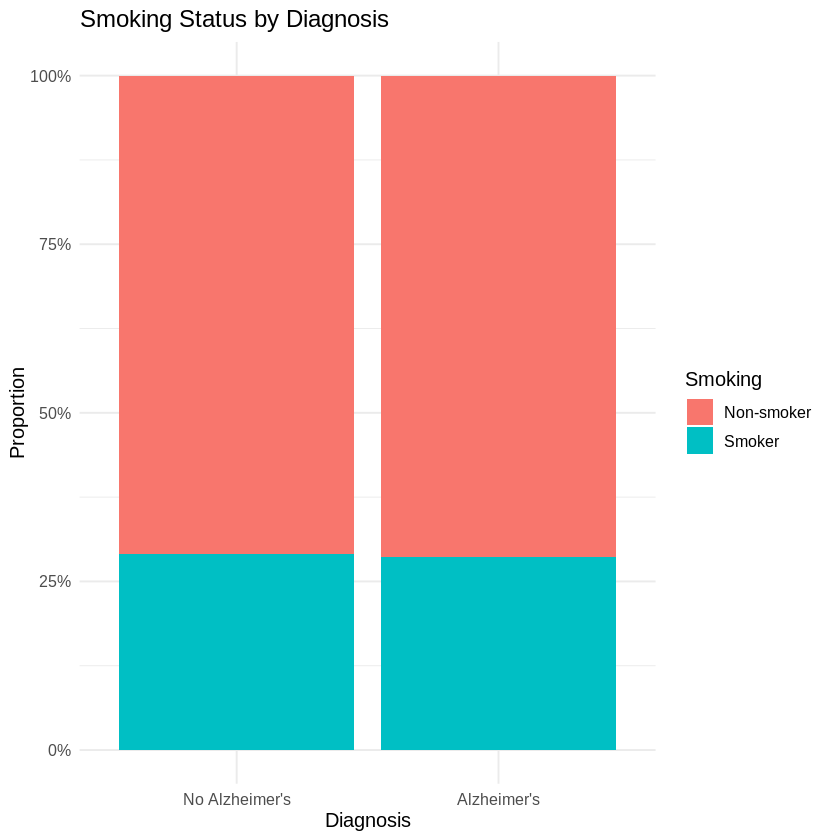

In [ ]:
smoking_lbl <- factor(df$smoking, labels = c("Non-smoker", "Smoker"))
ggplot(df, aes(x = diagnosis_lbl, fill = smoking_lbl)) +
  geom_bar(position = "fill") +
  scale_y_continuous(labels = percent) +
  labs(title = "Smoking Status by Diagnosis", x = "Diagnosis", y = "Proportion", fill = "Smoking")

Faceted histogram: MMSE by gender

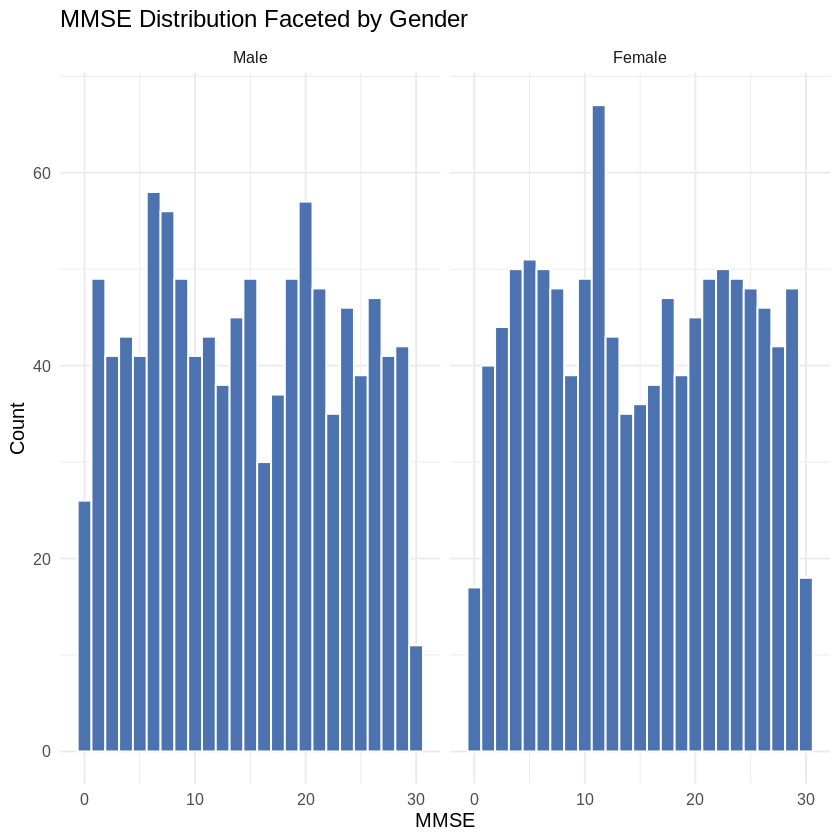

In [ ]:
ggplot(df, aes(x = mmse)) +
  geom_histogram(bins = 25, fill = "#4C72B0", color = "white") +
  facet_wrap(~ gender_lbl) +
  labs(title = "MMSE Distribution Faceted by Gender", x = "MMSE", y = "Count")


missingness visualization

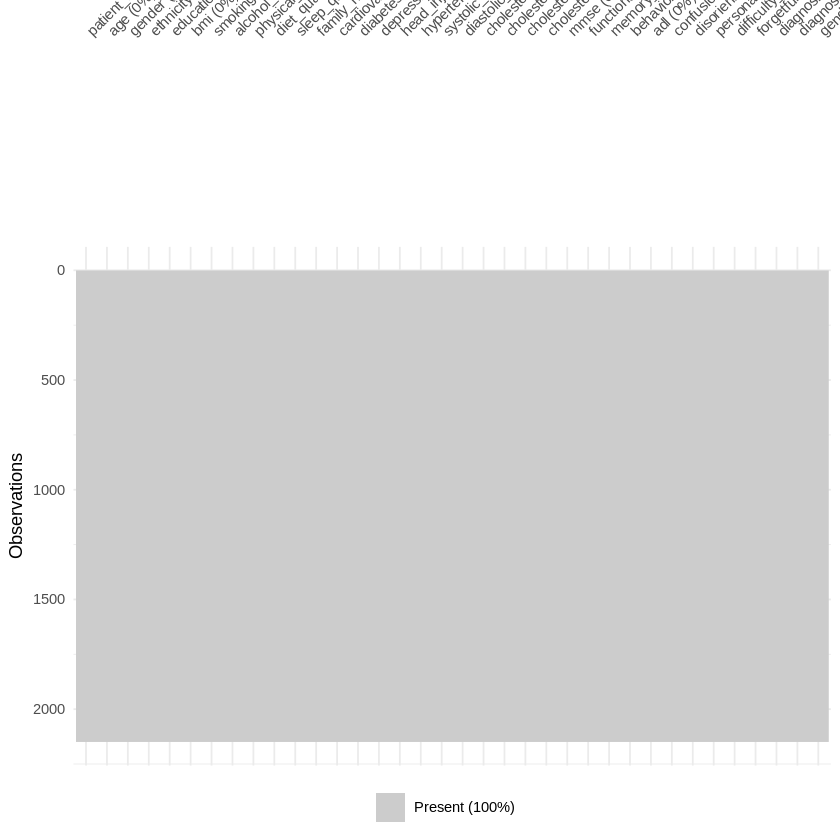

In [ ]:
vis_miss(df)


Line/loess plot: MMSE across patient sequence (pseudo-time trend)

`geom_smooth()` using formula = 'y ~ x'


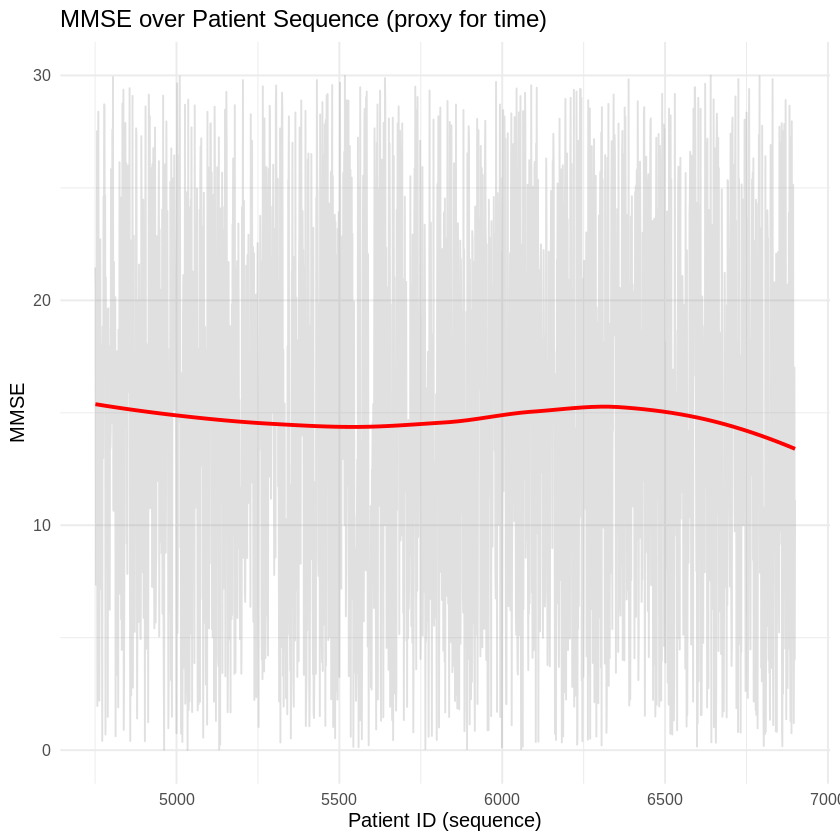

In [ ]:
ggplot(df, aes(x = patient_id, y = mmse)) +
  geom_line(alpha = 0.3, color = "grey60") +
  geom_smooth(method = "loess", color = "red", se = FALSE) +
  labs(title = "MMSE over Patient Sequence (proxy for time)", x = "Patient ID (sequence)", y = "MMSE")



# Descriptive Statistics — alz_clean.csv

Loads e1071 for skewness/kurtosis; reloads and relabels data

In [ ]:
if (!requireNamespace("e1071", quietly = TRUE)) install.packages("e1071")
library(e1071)   # skewness()/kurtosis() with selectable 'type'

df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)
df$diagnosis <- factor(df$diagnosis, labels = c("No Alzheimer's", "Alzheimer's"))

## Key numeric variables chosen for clinical relevance
key_vars <- c("age", "bmi", "mmse", "functional_assessment", "adl",
              "systolic_bp", "diastolic_bp", "cholesterol_total")

## Mode helper for continuous data (rounds to 1 decimal, takes most frequent value)
get_mode <- function(x) {
  x <- round(x, 1)
  ux <- na.omit(unique(x))
  ux[which.max(tabulate(match(x, ux)))]
}

## Core function: compute all requested statistics for one numeric vector
describe_var <- function(x) {
  x <- x[!is.na(x)]
  c(
    n                  = length(x),
    mean               = mean(x),
    median             = median(x),
    mode               = get_mode(x),
    variance           = var(x),
    sd                 = sd(x),
    range              = max(x) - min(x),
    min                = min(x),
    max                = max(x),
    IQR                = IQR(x),
    CV_pct             = (sd(x) / mean(x)) * 100,
    p10                = quantile(x, 0.10),
    Q1_p25             = quantile(x, 0.25),
    median_p50         = quantile(x, 0.50),
    Q3_p75             = quantile(x, 0.75),
    p90                = quantile(x, 0.90),
    p95                = quantile(x, 0.95),
    p99                = quantile(x, 0.99),
    skewness_type2     = skewness(x, type = 2),   # classic/SPSS-style formula
    kurtosis_excess_t2 = kurtosis(x, type = 2)    # excess kurtosis, SPSS-style
  )
}



Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element




Defines get_mode() helper and a comprehensive describe_var() function (n, mean, median, mode, variance, sd, range, IQR, CV%, percentiles, skewness, kurtosis)

In [ ]:
overall_stats <- t(sapply(key_vars, function(v) describe_var(df[[v]])))
overall_stats <- round(as.data.frame(overall_stats), 3)
overall_stats <- cbind(variable = key_vars, overall_stats)

cat("\n================ OVERALL DESCRIPTIVE STATISTICS ================\n")
print(overall_stats, row.names = FALSE)


================ OVERALL DESCRIPTIVE STATISTICS ================
              variable    n    mean  median  mode variance     sd   range
                   age 2149  74.909  75.000  68.0   80.824  8.990  30.000
                   bmi 2149  27.656  27.824  36.2   52.091  7.217  24.984
                  mmse 2149  14.755  14.442  25.4   74.186  8.613  29.986
 functional_assessment 2149   5.080   5.094   8.8    8.368  2.893   9.996
                   adl 2149   4.983   5.039   0.2    8.701  2.950   9.998
           systolic_bp 2149 134.265 134.000 155.0  673.369 25.949  89.000
          diastolic_bp 2149  89.848  91.000  61.0  309.496 17.592  59.000
     cholesterol_total 2149 225.198 225.086 234.3 1809.842 42.542 149.900
     min     max    IQR CV_pct p10.10% Q1_p25.25% median_p50.50% Q3_p75.75%
  60.000  90.000 16.000 12.002  63.000     67.000         75.000     83.000
  15.009  39.993 12.258 26.097  17.596     21.611         27.824     33.870
   0.005  29.991 14.993 58.374   3.116  

Applies it across key variables → overall stats table

In [ ]:
group_rows <- list()
for (v in key_vars) {
  for (g in levels(df$diagnosis)) {
    x <- df[df$diagnosis == g, v]
    row <- c(variable = v, diagnosis = g, describe_var(x))
    group_rows[[length(group_rows) + 1]] <- row
  }
}
group_stats <- as.data.frame(do.call(rbind, group_rows), stringsAsFactors = FALSE)

## convert numeric-looking columns back to numeric and round
num_cols <- setdiff(names(group_stats), c("variable", "diagnosis"))
group_stats[num_cols] <- lapply(group_stats[num_cols], function(x) round(as.numeric(x), 3))

cat("\n================ DESCRIPTIVE STATISTICS BY DIAGNOSIS ================\n")
print(group_stats, row.names = FALSE)



================ DESCRIPTIVE STATISTICS BY DIAGNOSIS ================
              variable      diagnosis    n    mean  median  mode variance
                   age No Alzheimer's 1389  74.945  75.000  72.0   79.294
                   age    Alzheimer's  760  74.842  75.000  61.0   83.722
                   bmi No Alzheimer's 1389  27.515  27.561  28.2   51.427
                   bmi    Alzheimer's  760  27.913  28.005  36.2   53.272
                  mmse No Alzheimer's 1389  16.266  17.146  25.4   79.803
                  mmse    Alzheimer's  760  11.995  11.566   6.7   52.208
 functional_assessment No Alzheimer's 1389   5.861   6.244   8.8    7.623
 functional_assessment    Alzheimer's  760   3.653   3.299   1.3    6.588
                   adl No Alzheimer's 1389   5.708   6.135   7.6    7.989
                   adl    Alzheimer's  760   3.658   3.236   0.4    7.295
           systolic_bp No Alzheimer's 1389 134.564 135.000 107.0  673.216
           systolic_bp    Alzheimer's  76

Saves both tables to CSV

In [ ]:
write.csv(overall_stats, "descriptive_stats_overall.csv", row.names = FALSE)
write.csv(group_stats,  "descriptive_stats_by_diagnosis.csv", row.names = FALSE)

cat("\nSaved: descriptive_stats_overall.csv, descriptive_stats_by_diagnosis.csv\n")


Saved: descriptive_stats_overall.csv, descriptive_stats_by_diagnosis.csv


Outlier Detection

Reloads data

In [ ]:
if (!requireNamespace("ggplot2", quietly = TRUE)) install.packages("ggplot2")
library(ggplot2)

df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)
df$diagnosis <- factor(df$diagnosis, labels = c("No Alzheimer's", "Alzheimer's"))

key_vars <- c("age", "bmi", "mmse", "functional_assessment", "adl",
              "systolic_bp", "diastolic_bp", "cholesterol_total")


IQR-rule outlier counts per variable

In [ ]:
iqr_outliers <- function(x) {
  q1 <- quantile(x, 0.25, na.rm = TRUE)
  q3 <- quantile(x, 0.75, na.rm = TRUE)
  iqr <- q3 - q1
  lower <- q1 - 1.5 * iqr
  upper <- q3 + 1.5 * iqr
  which(x < lower | x > upper)
}

cat("\n================ 1. IQR RULE ================\n")
for (v in key_vars) {
  idx <- iqr_outliers(df[[v]])
  cat(sprintf("%-25s : %d outliers (%.2f%%)\n", v, length(idx), 100 * length(idx) / nrow(df)))
}



================ 1. IQR RULE ================
age                       : 0 outliers (0.00%)
bmi                       : 0 outliers (0.00%)
mmse                      : 0 outliers (0.00%)
functional_assessment     : 0 outliers (0.00%)
adl                       : 0 outliers (0.00%)
systolic_bp               : 0 outliers (0.00%)
diastolic_bp              : 0 outliers (0.00%)
cholesterol_total         : 0 outliers (0.00%)


Range/plausibility check against real-world clinical bounds

In [ ]:
plausible_ranges <- list(
  age                    = c(0, 110),
  bmi                    = c(10, 60),
  mmse                   = c(0, 30),     # MMSE is scored 0-30 by definition
  functional_assessment  = c(0, 10),
  adl                    = c(0, 10),
  systolic_bp            = c(70, 200),
  diastolic_bp           = c(40, 130),
  cholesterol_total      = c(100, 400)
)

cat("\n================ 2. RANGE CHECK (plausible real-world limits) ================\n")
for (v in key_vars) {
  rng <- range(df[[v]], na.rm = TRUE)
  bounds <- plausible_ranges[[v]]
  out_of_range <- sum(df[[v]] < bounds[1] | df[[v]] > bounds[2], na.rm = TRUE)
  cat(sprintf("%-25s observed=[%.2f, %.2f]  plausible=[%.0f, %.0f]  violations=%d\n",
              v, rng[1], rng[2], bounds[1], bounds[2], out_of_range))
}



================ 2. RANGE CHECK (plausible real-world limits) ================
age                       observed=[60.00, 90.00]  plausible=[0, 110]  violations=0
bmi                       observed=[15.01, 39.99]  plausible=[10, 60]  violations=0
mmse                      observed=[0.01, 29.99]  plausible=[0, 30]  violations=0
functional_assessment     observed=[0.00, 10.00]  plausible=[0, 10]  violations=0
adl                       observed=[0.00, 10.00]  plausible=[0, 10]  violations=0
systolic_bp               observed=[90.00, 179.00]  plausible=[70, 200]  violations=0
diastolic_bp              observed=[60.00, 119.00]  plausible=[40, 130]  violations=0
cholesterol_total         observed=[150.09, 299.99]  plausible=[100, 400]  violations=0


Z-score method (|z|>3)

In [ ]:
z_outliers <- function(x) {
  z <- (x - mean(x, na.rm = TRUE)) / sd(x, na.rm = TRUE)
  which(abs(z) > 3)
}

cat("\n================ 3. Z-SCORE METHOD (|z| > 3) ================\n")
for (v in key_vars) {
  idx <- z_outliers(df[[v]])
  cat(sprintf("%-25s : %d outliers (%.2f%%)\n", v, length(idx), 100 * length(idx) / nrow(df)))
}



================ 3. Z-SCORE METHOD (|z| > 3) ================
age                       : 0 outliers (0.00%)
bmi                       : 0 outliers (0.00%)
mmse                      : 0 outliers (0.00%)
functional_assessment     : 0 outliers (0.00%)
adl                       : 0 outliers (0.00%)
systolic_bp               : 0 outliers (0.00%)
diastolic_bp              : 0 outliers (0.00%)
cholesterol_total         : 0 outliers (0.00%)


Modified Z-score/MAD method (|mz|>3.5)

In [ ]:
modified_z_outliers <- function(x) {
  med <- median(x, na.rm = TRUE)
  mad_val <- mad(x, na.rm = TRUE)   # constant = 1.4826 by default (consistent with SD under normality)
  mz <- 0.6745 * (x - med) / mad_val
  which(abs(mz) > 3.5)
}

cat("\n================ 4. MODIFIED Z-SCORE (MAD-based, |mz| > 3.5) ================\n")
for (v in key_vars) {
  idx <- modified_z_outliers(df[[v]])
  cat(sprintf("%-25s : %d outliers (%.2f%%)\n", v, length(idx), 100 * length(idx) / nrow(df)))
}



================ 4. MODIFIED Z-SCORE (MAD-based, |mz| > 3.5) ================
age                       : 0 outliers (0.00%)
bmi                       : 0 outliers (0.00%)
mmse                      : 0 outliers (0.00%)
functional_assessment     : 0 outliers (0.00%)
adl                       : 0 outliers (0.00%)
systolic_bp               : 0 outliers (0.00%)
diastolic_bp              : 0 outliers (0.00%)
cholesterol_total         : 0 outliers (0.00%)


Boxplots per variable to visualize outliers

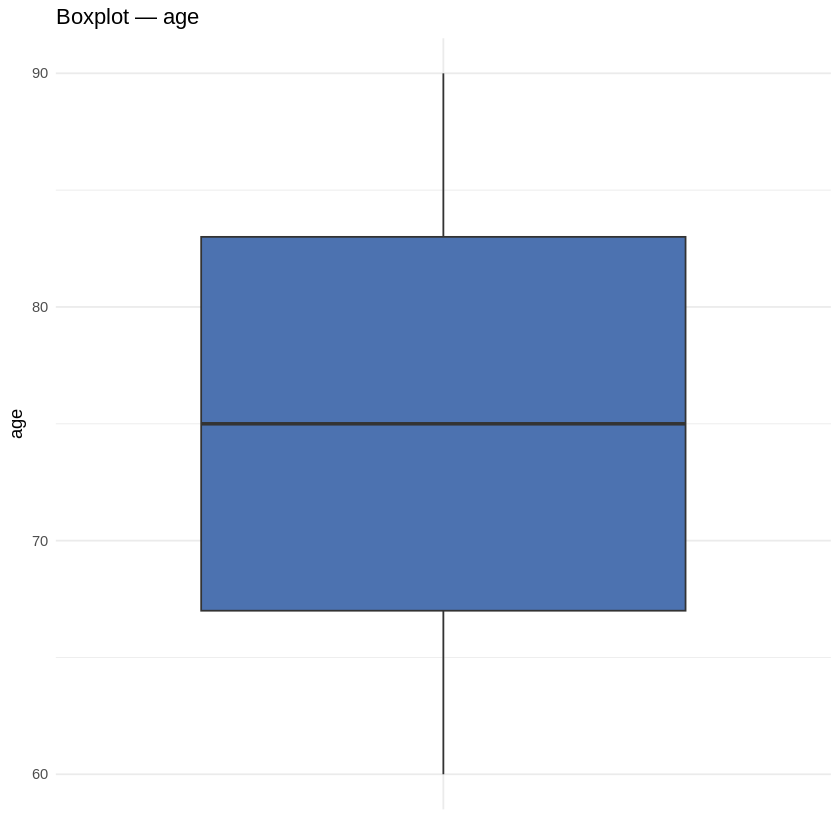

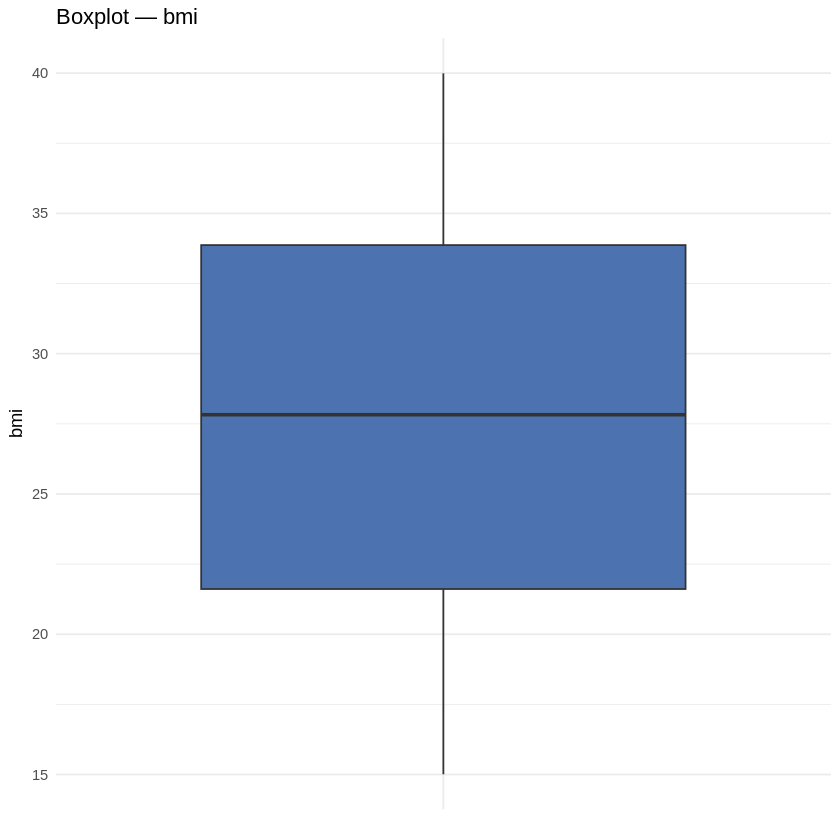

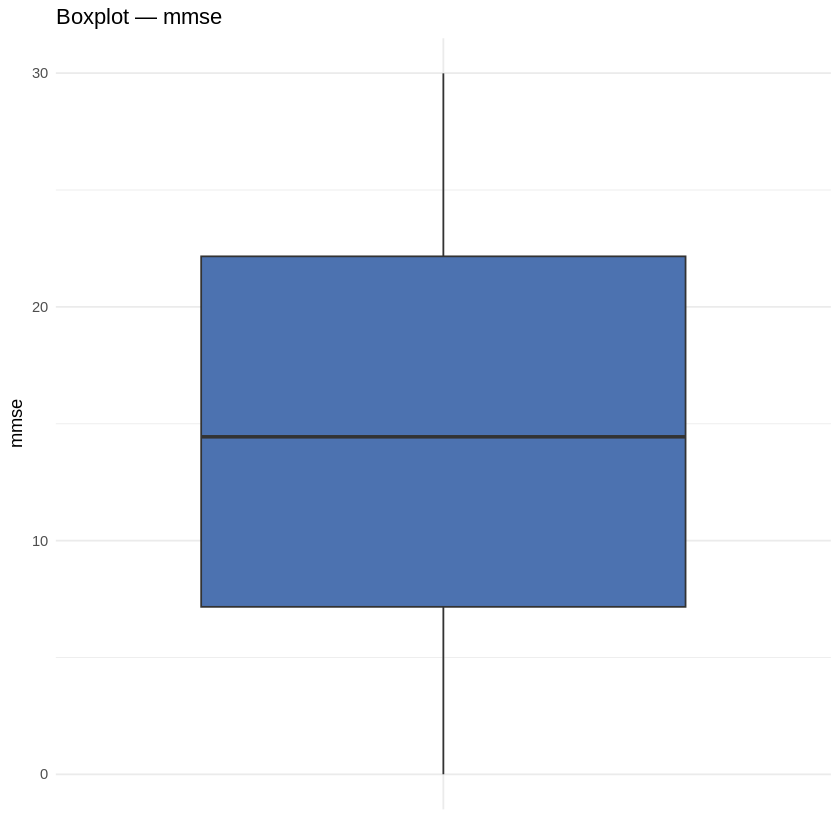

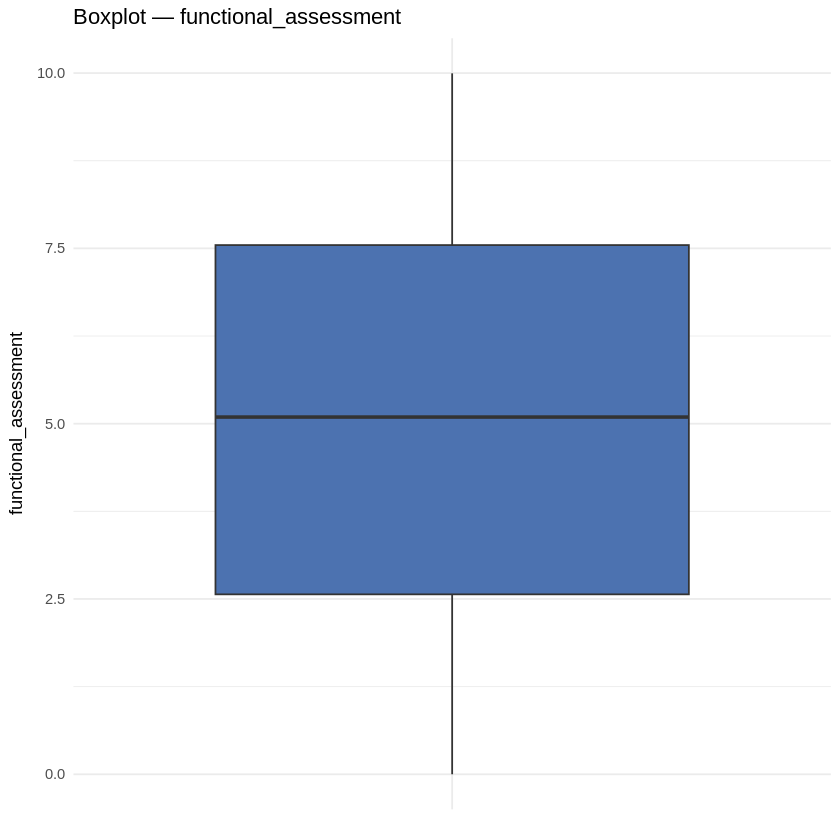

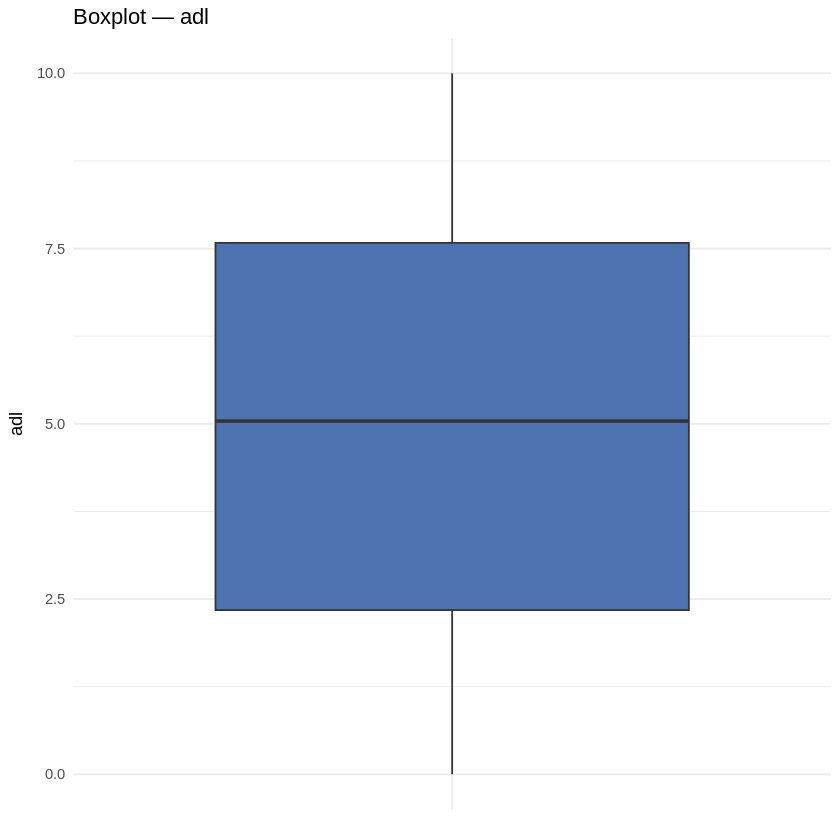

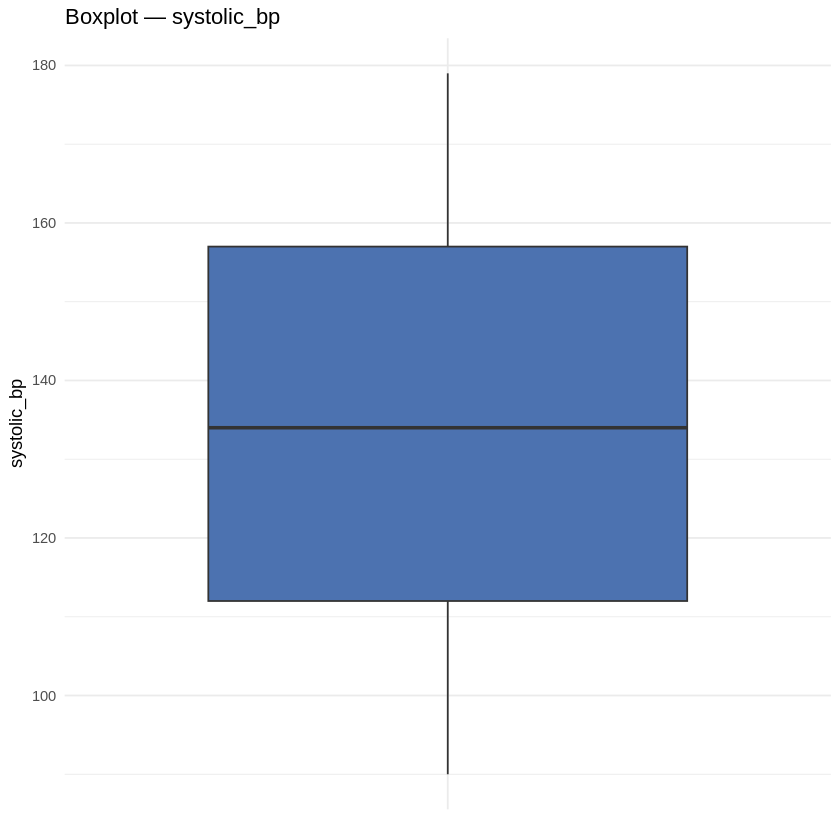

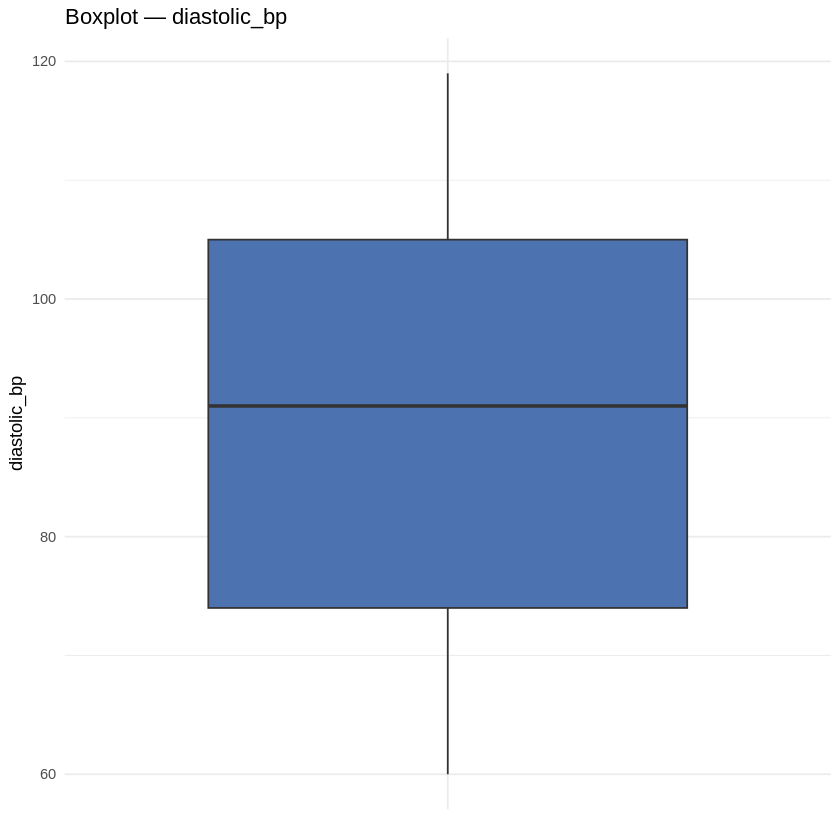

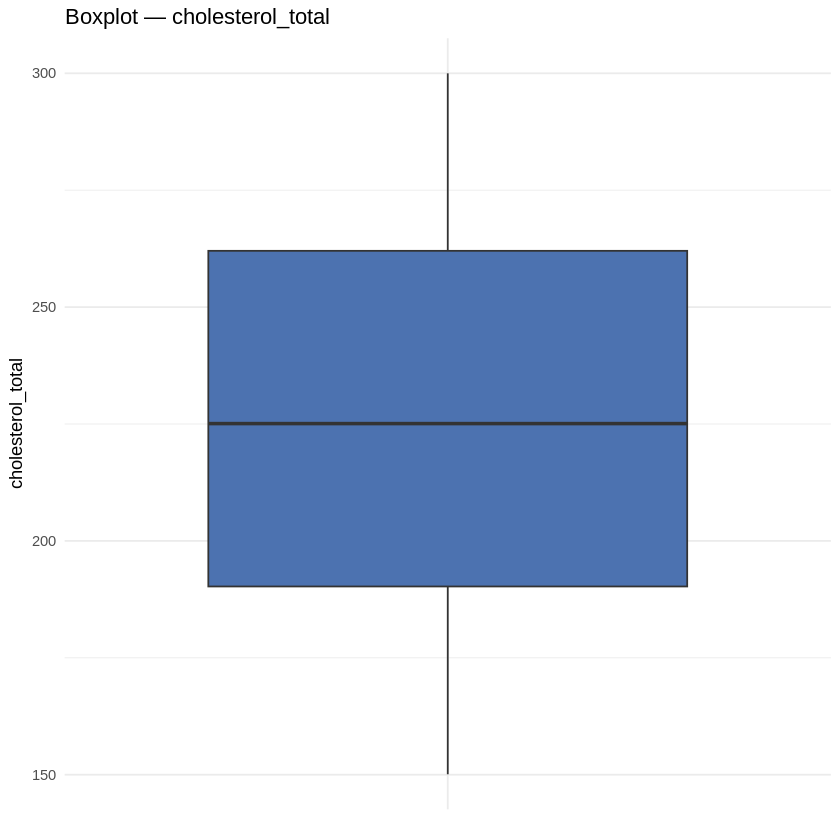

In [ ]:
for (v in key_vars) {
  p <- ggplot(df, aes(x = "", y = .data[[v]])) +
    geom_boxplot(fill = "#4C72B0", outlier.color = "red", outlier.shape = 16) +
    labs(title = paste("Boxplot —", v), x = NULL, y = v) +
    theme_minimal()
  print(p)   # in RStudio each will render in the Plots pane; ggsave() if batch-saving
  # ggsave(paste0("boxplot_", v, ".png"), p, width = 4, height = 5)
}


CHECKING THE DISTRIBUTION

Histograms per variable

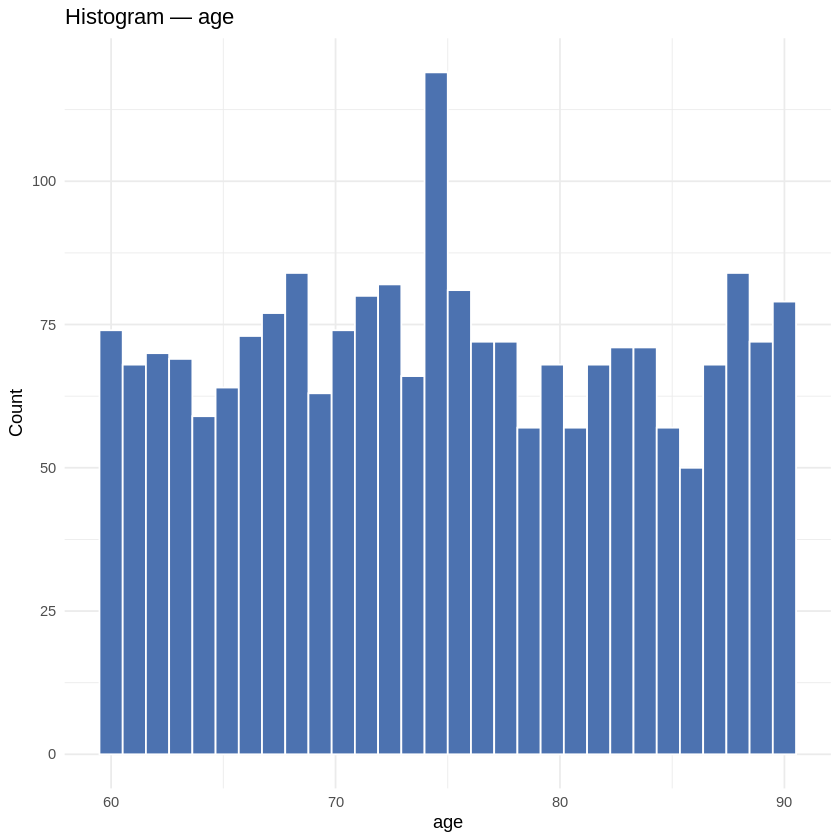

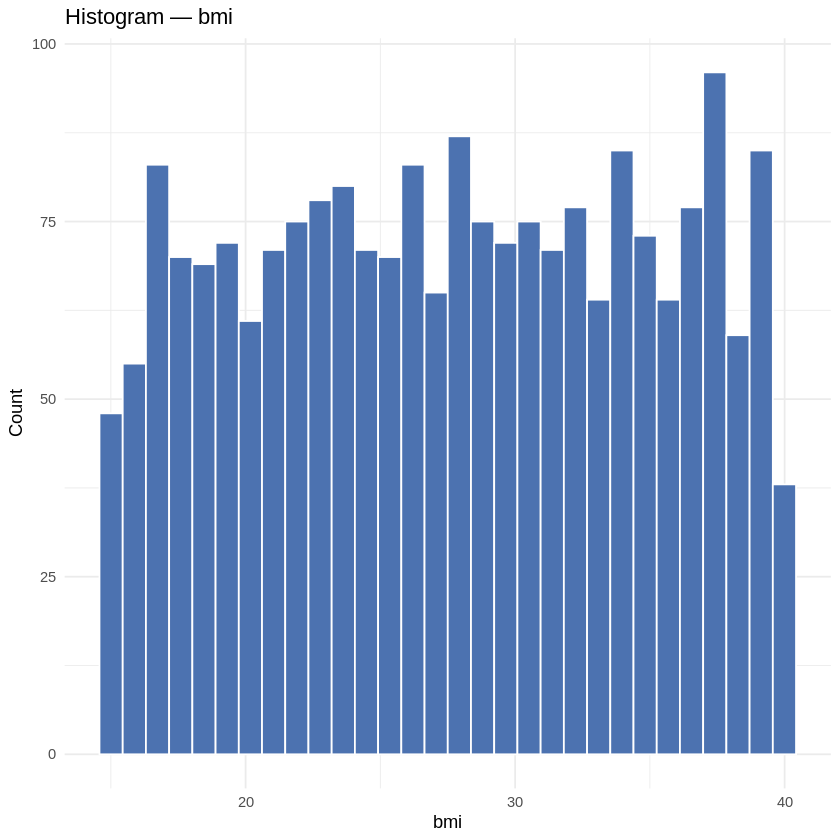

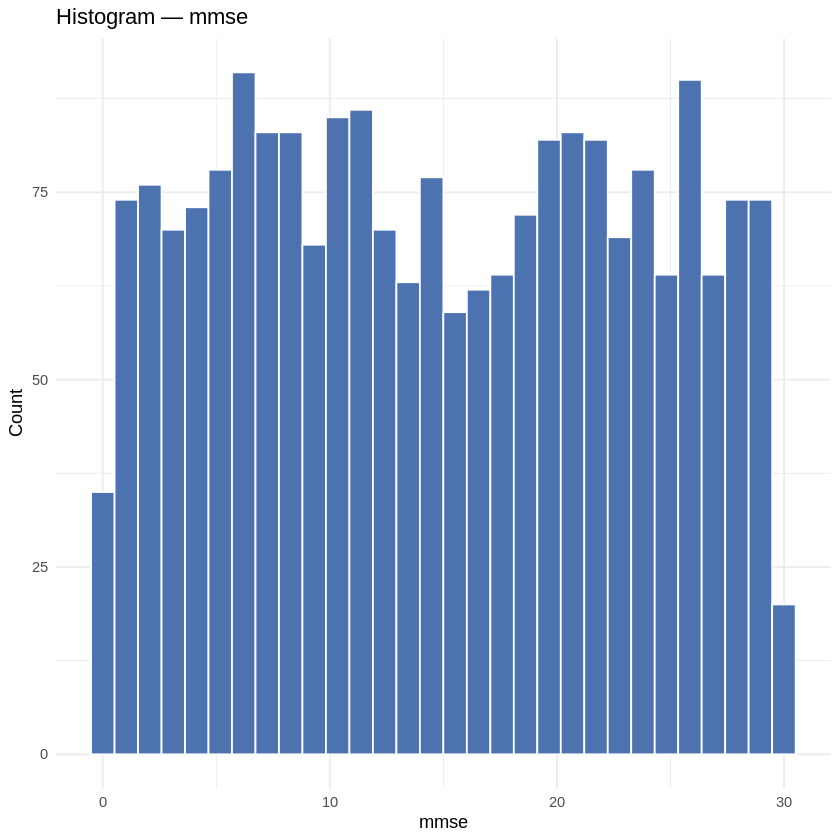

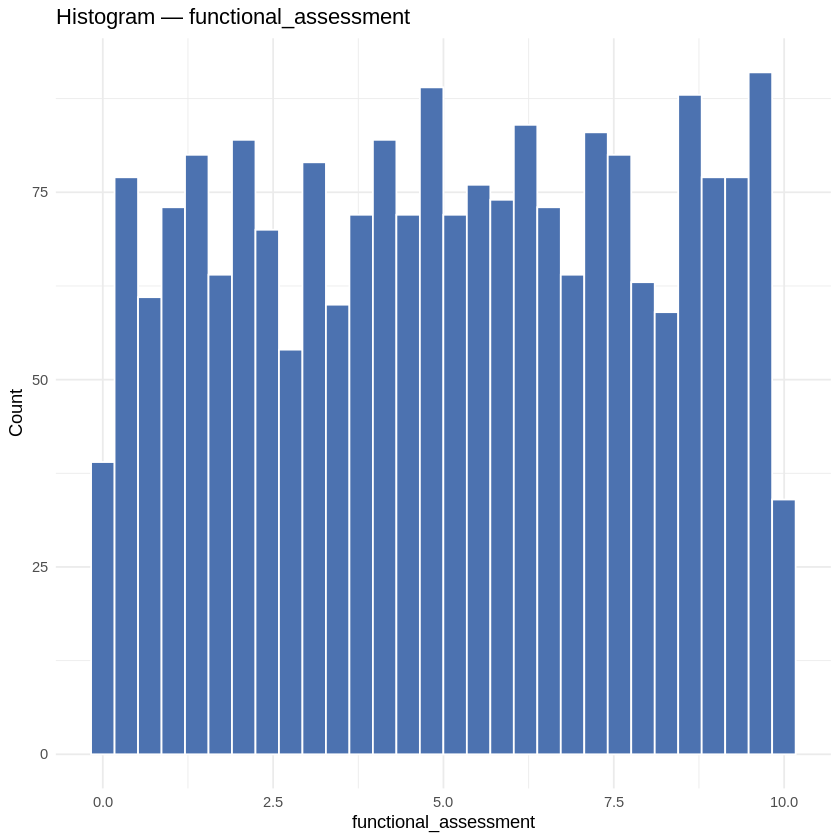

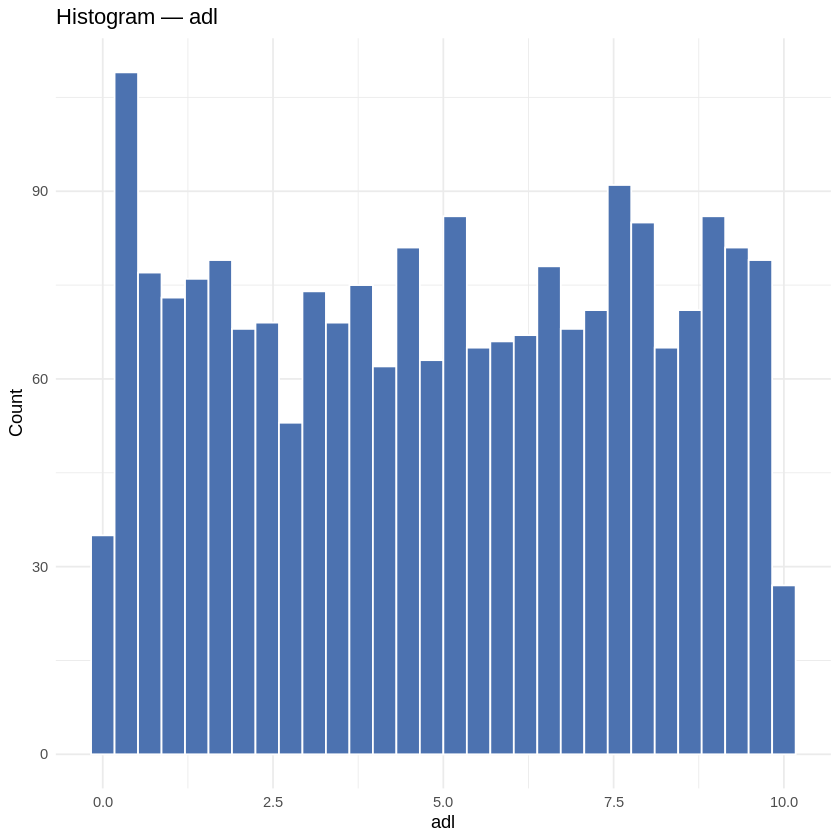

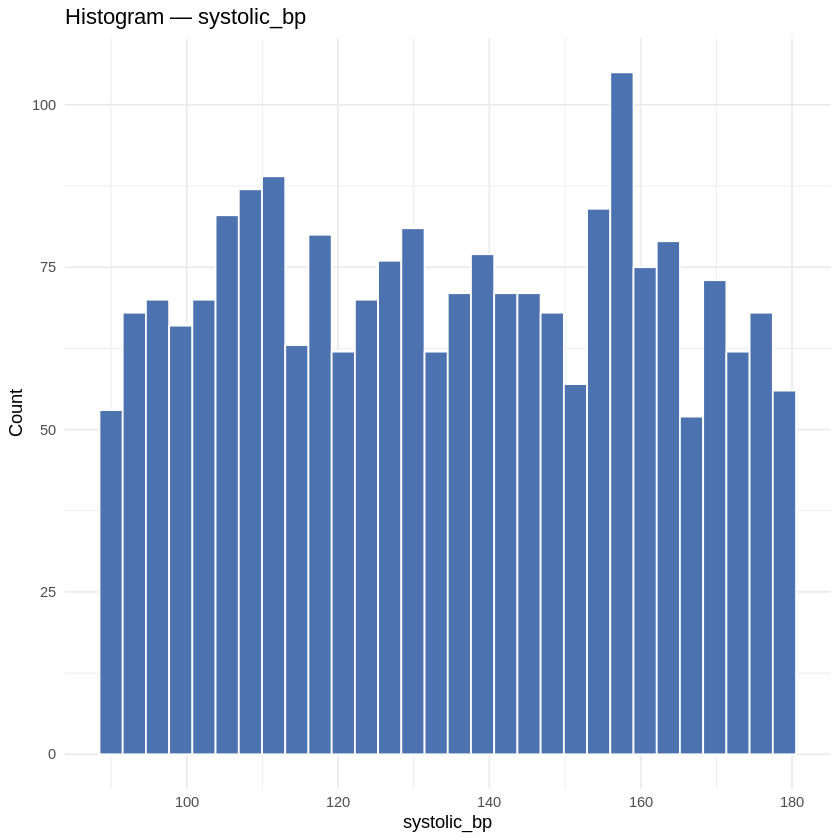

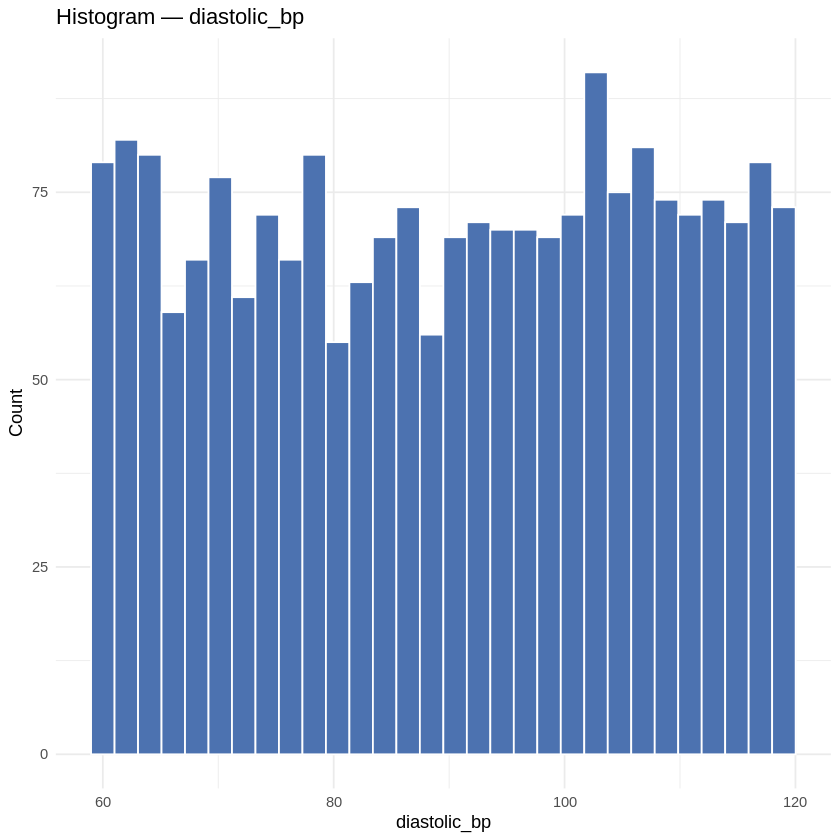

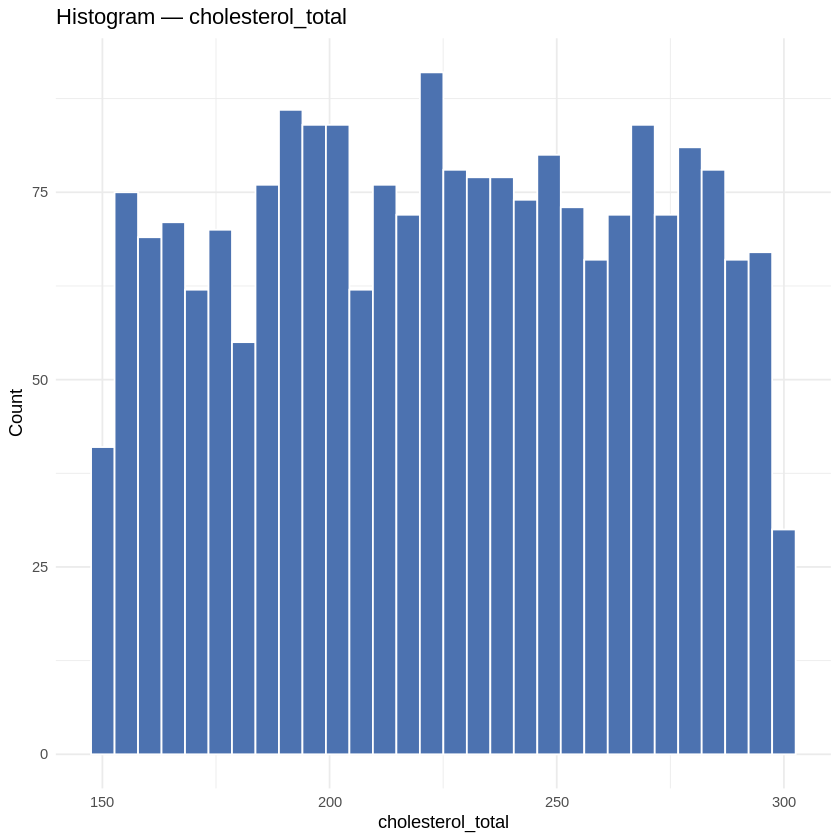

In [ ]:
for (v in key_vars) {
  p <- ggplot(df, aes(x = .data[[v]])) +
    geom_histogram(bins = 30, fill = "#4C72B0", color = "white") +
    labs(title = paste("Histogram —", v), x = v, y = "Count") +
    theme_minimal()
  print(p)
}



Density plots per variable by diagnosis

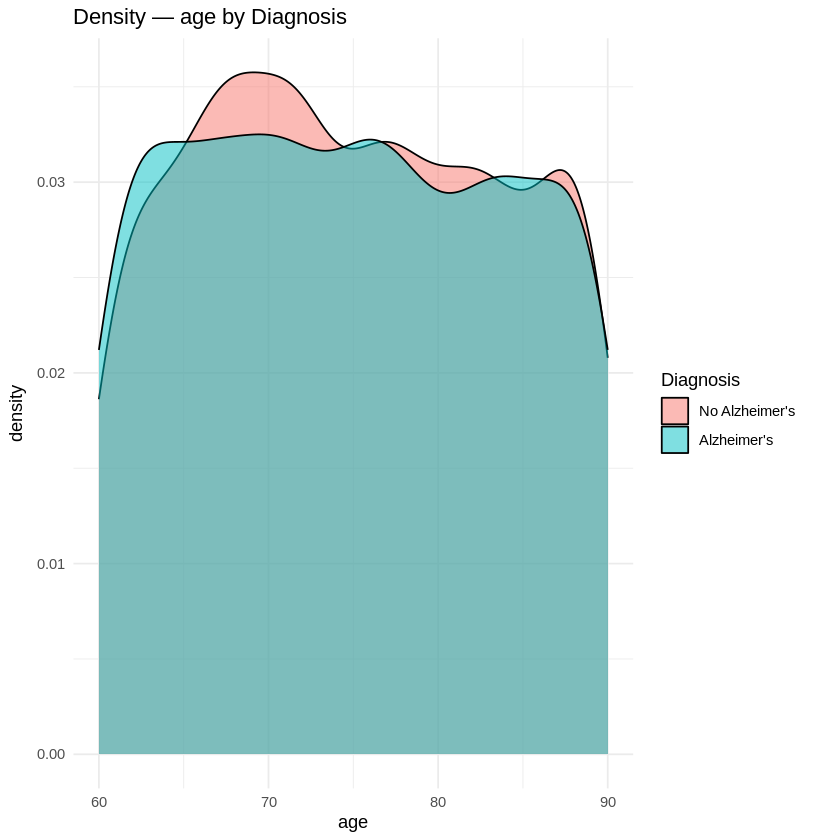

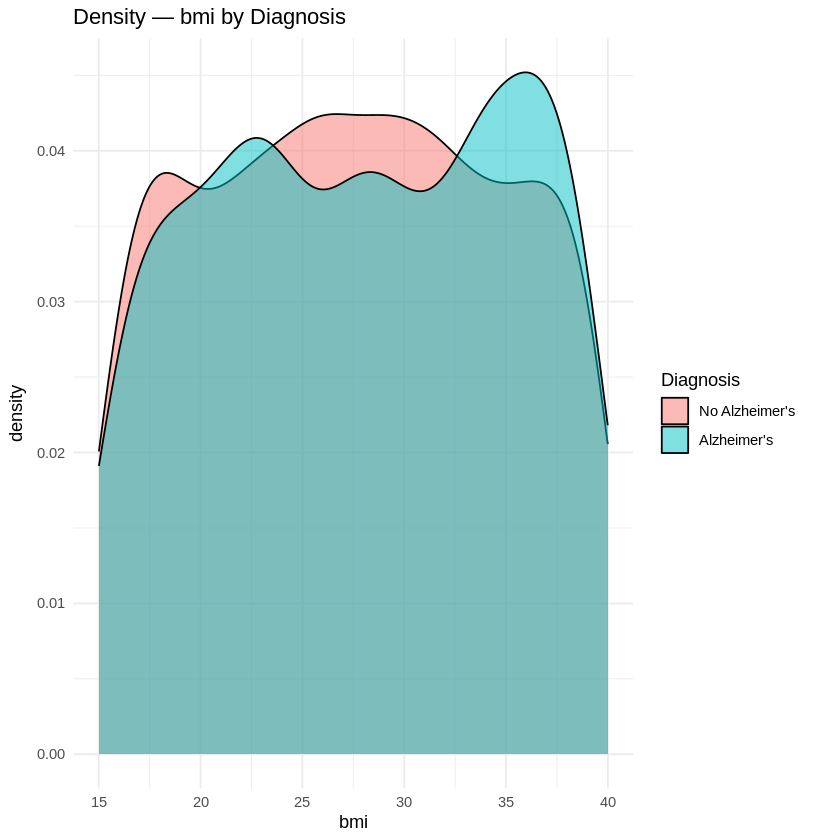

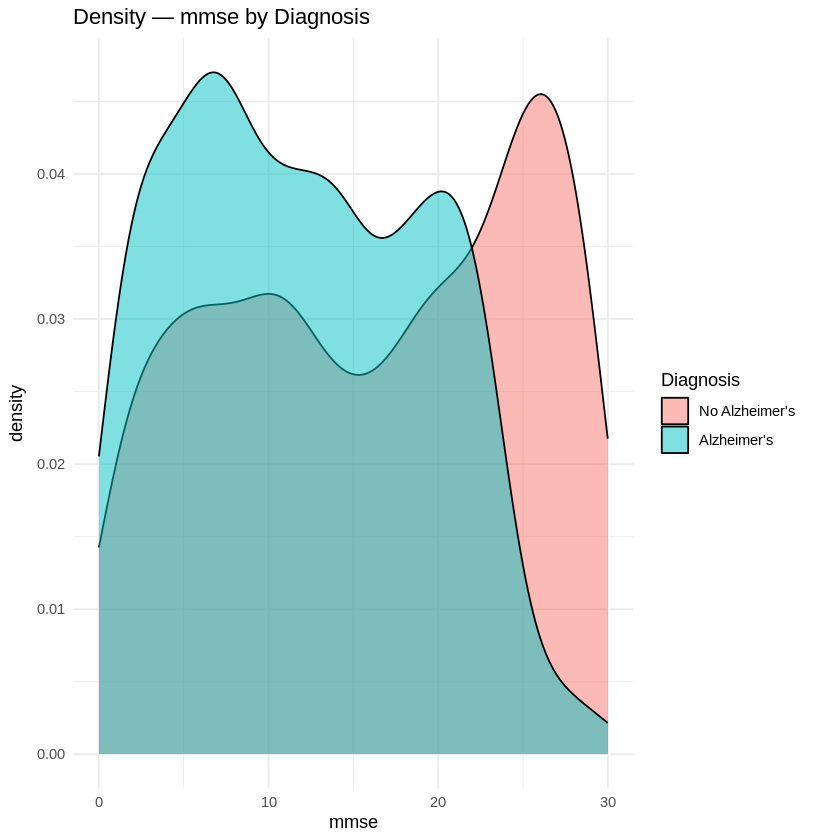

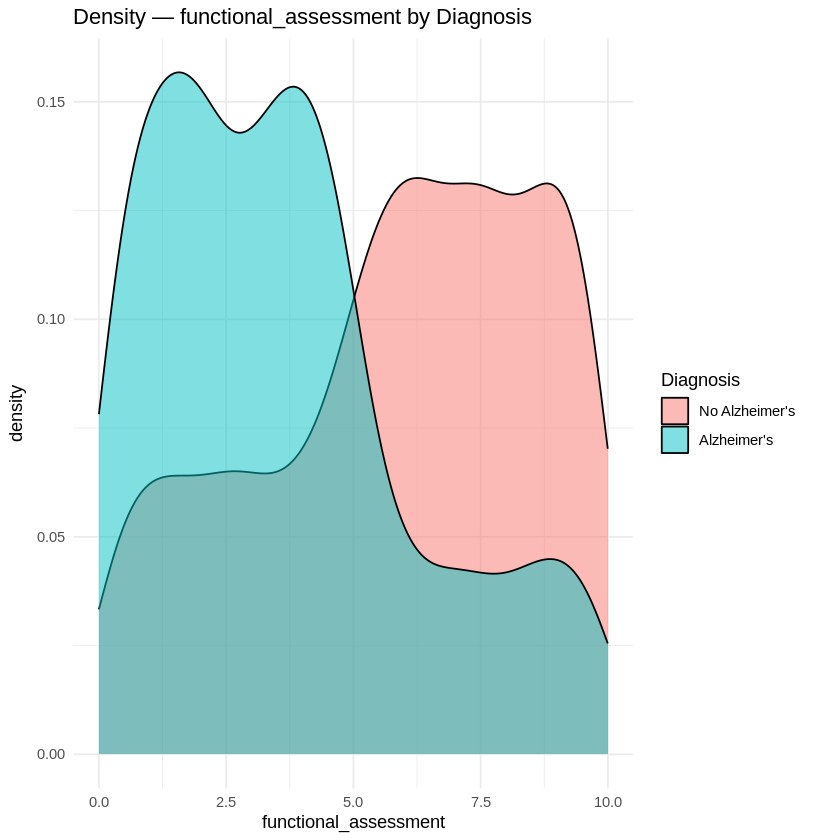

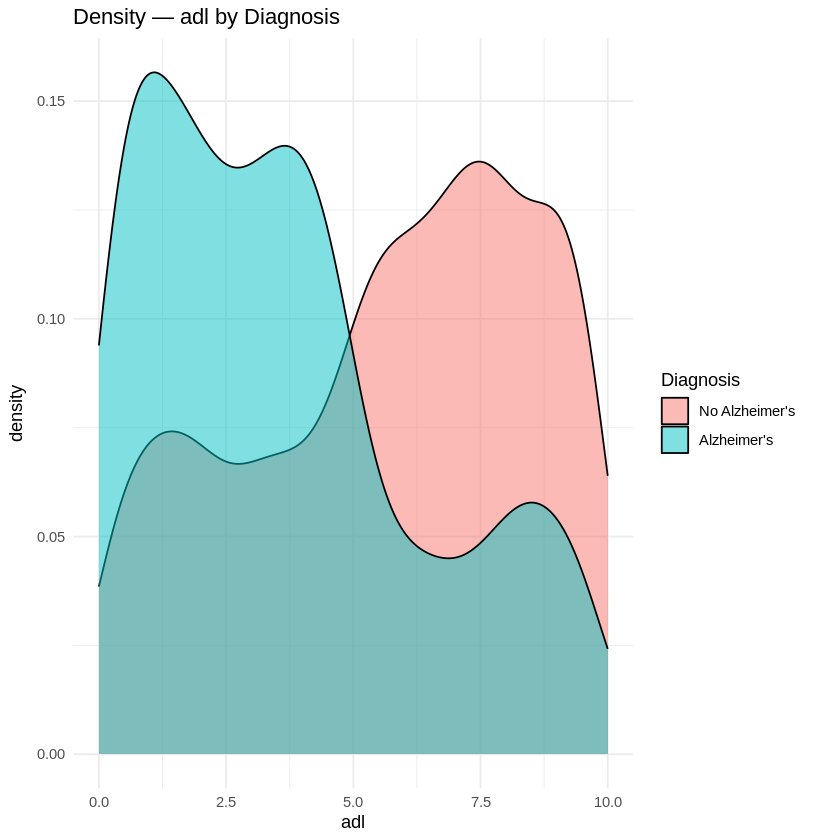

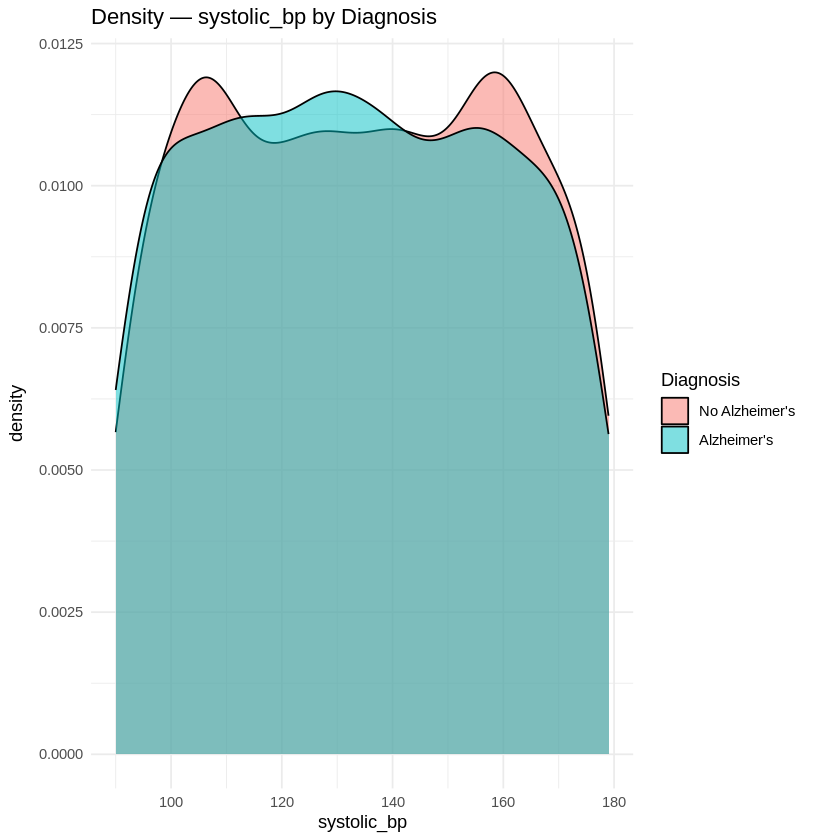

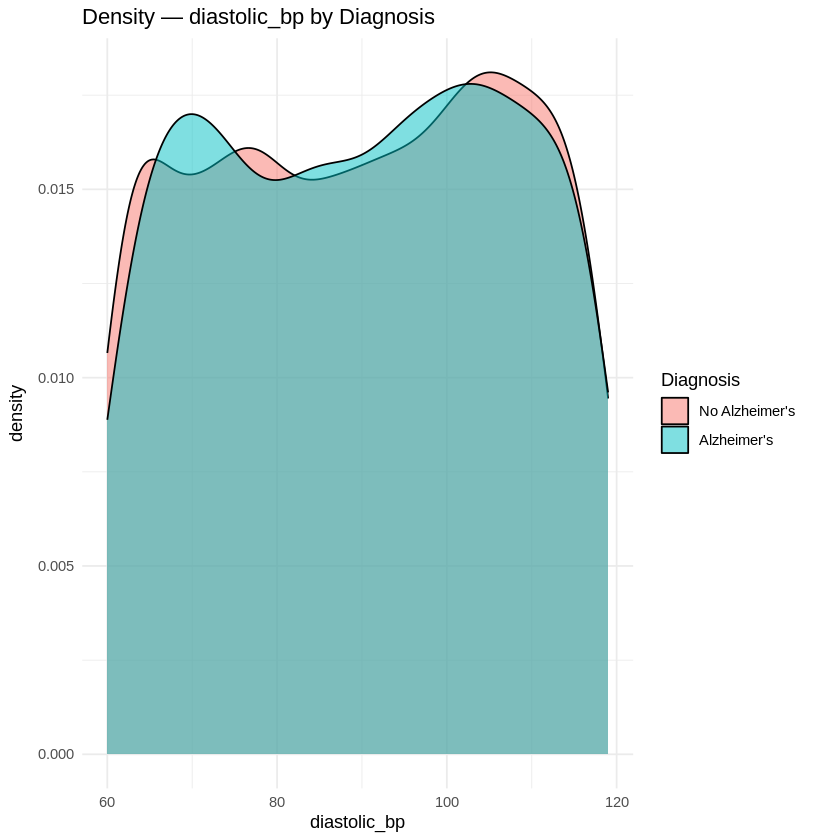

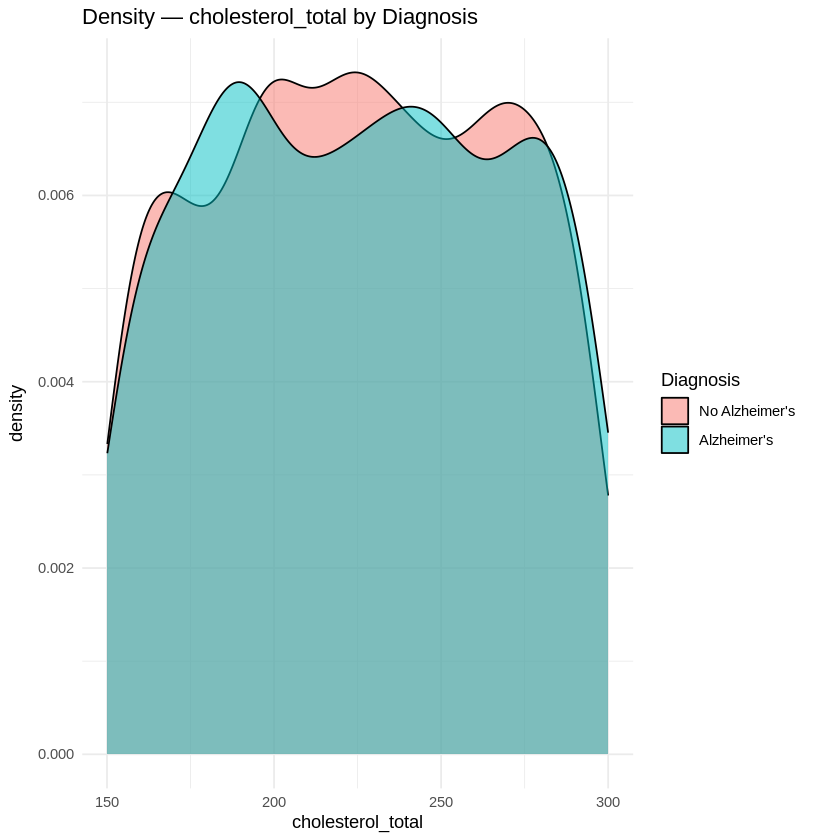

In [ ]:
for (v in key_vars) {
  p <- ggplot(df, aes(x = .data[[v]], fill = diagnosis)) +
    geom_density(alpha = 0.5) +
    labs(title = paste("Density —", v, "by Diagnosis"), x = v, fill = "Diagnosis") +
    theme_minimal()
  print(p)
}


QQ-plots per variable

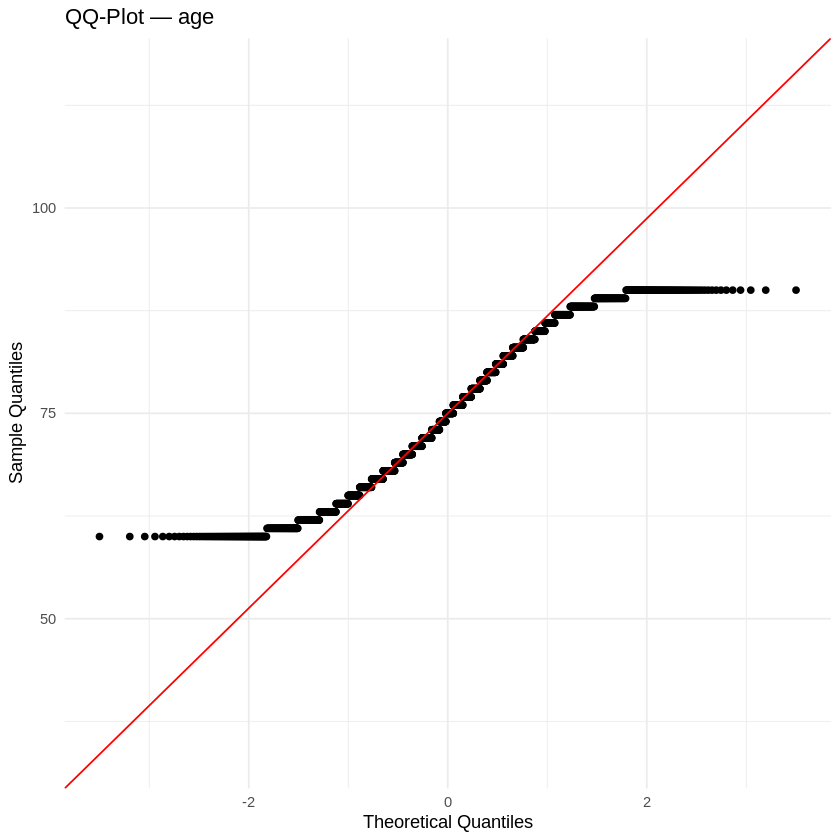

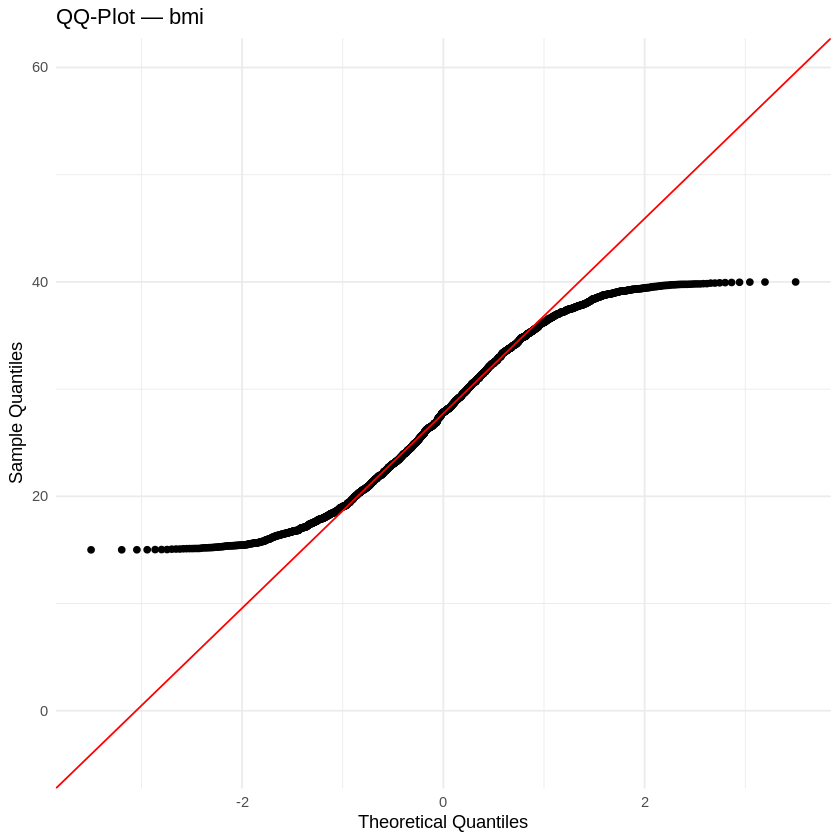

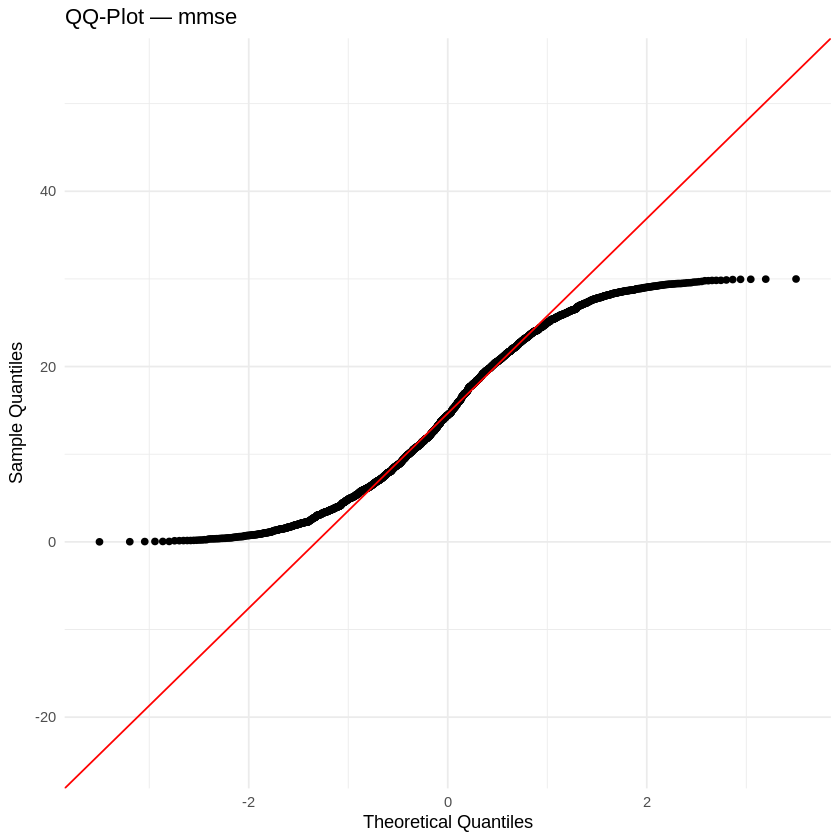

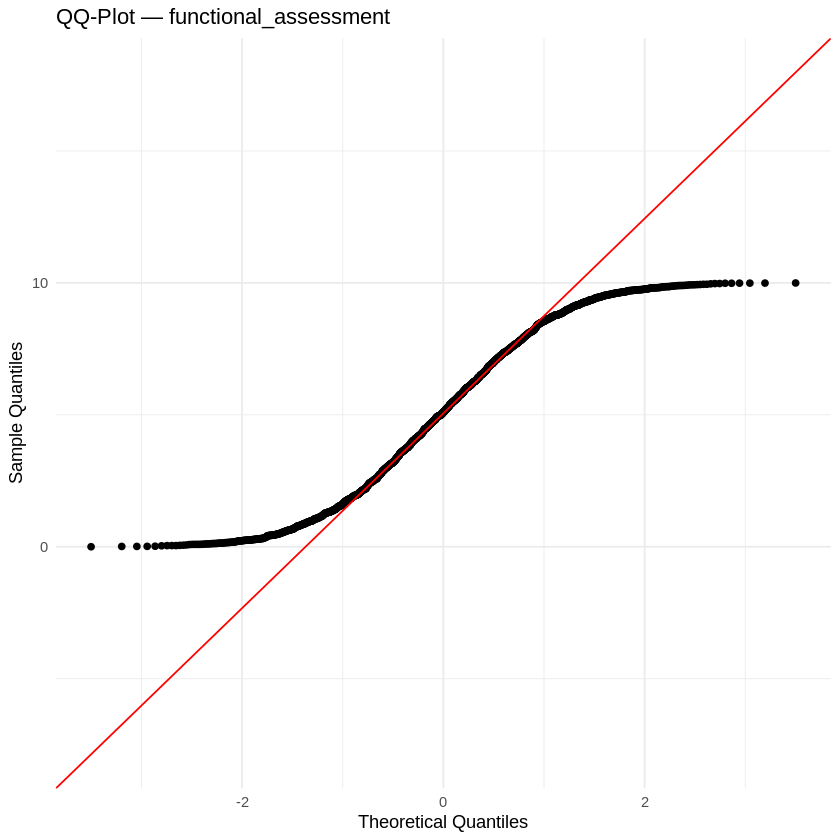

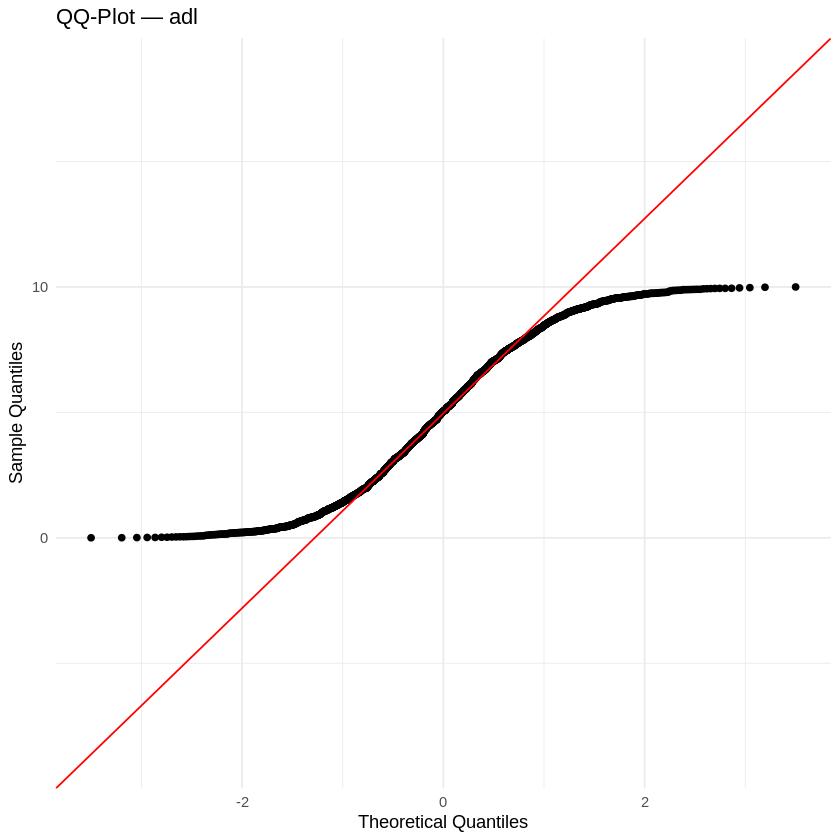

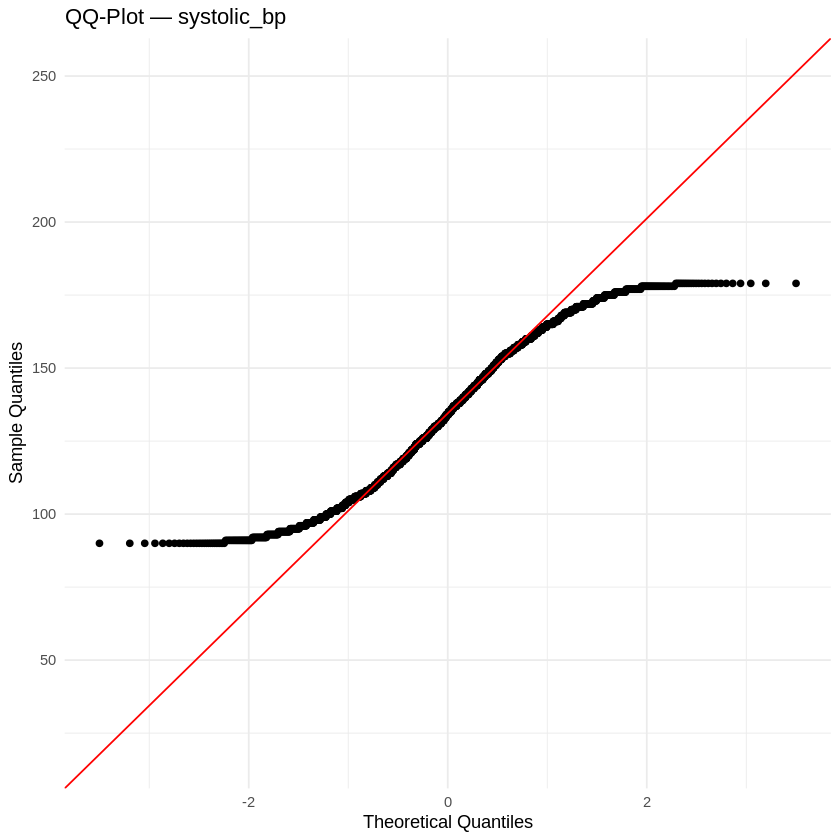

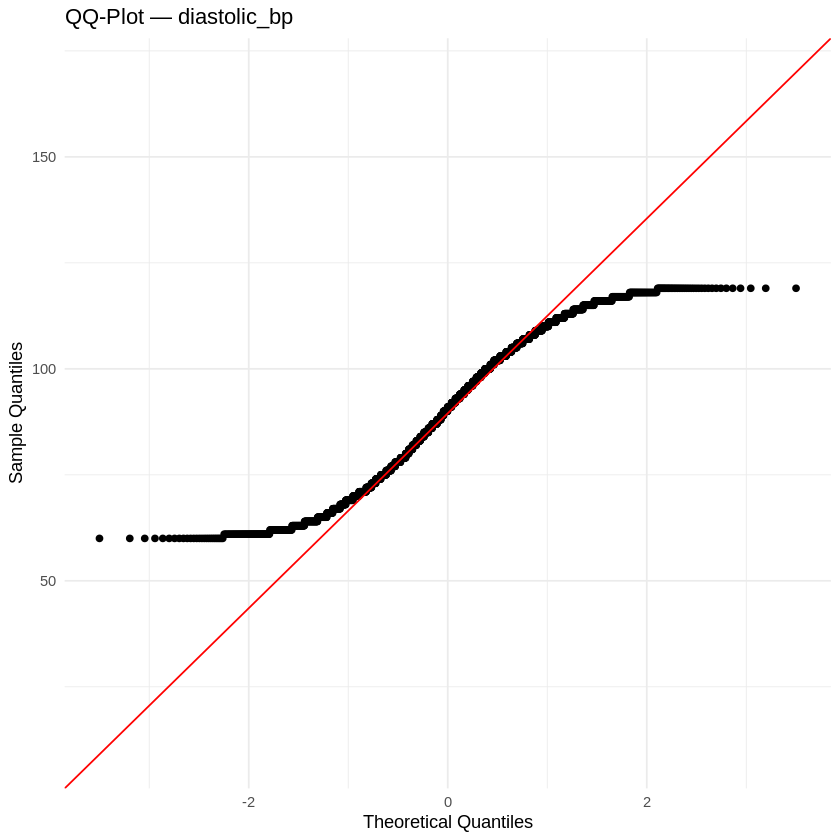

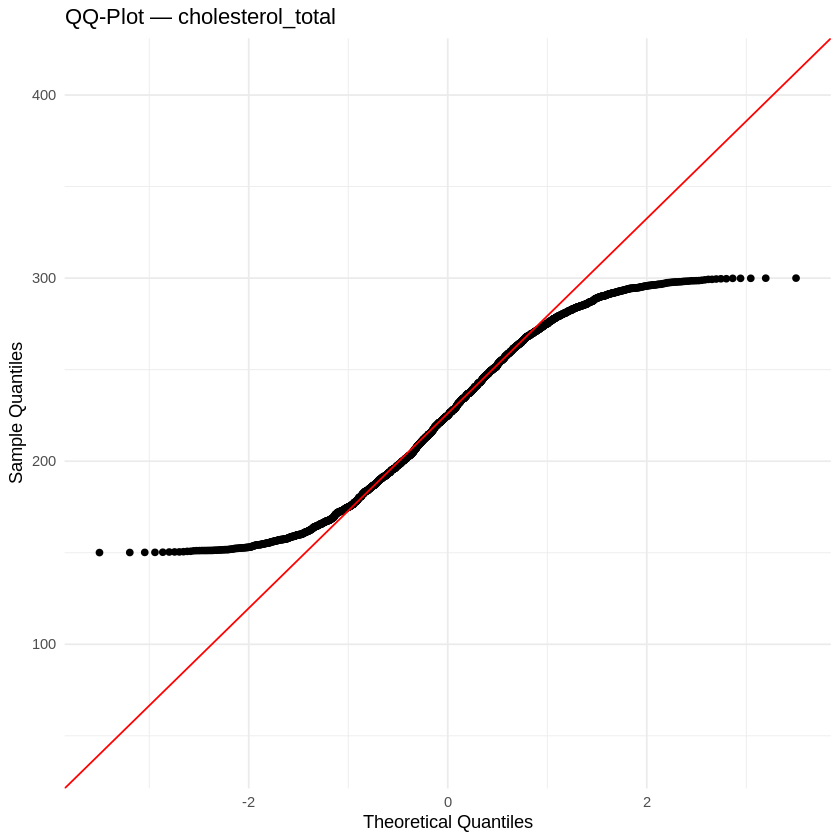

In [ ]:
for (v in key_vars) {
  p <- ggplot(df, aes(sample = .data[[v]])) +
    stat_qq() +
    stat_qq_line(color = "red") +
    labs(title = paste("QQ-Plot —", v), x = "Theoretical Quantiles", y = "Sample Quantiles") +
    theme_minimal()
  print(p)
}


ECDF plots per variable by diagnosis

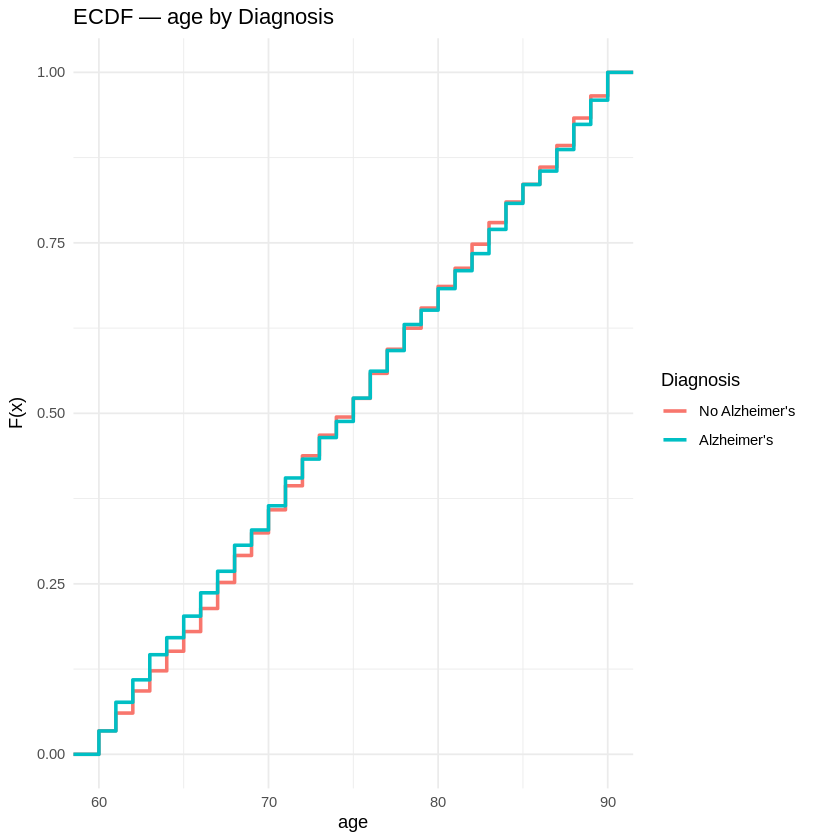

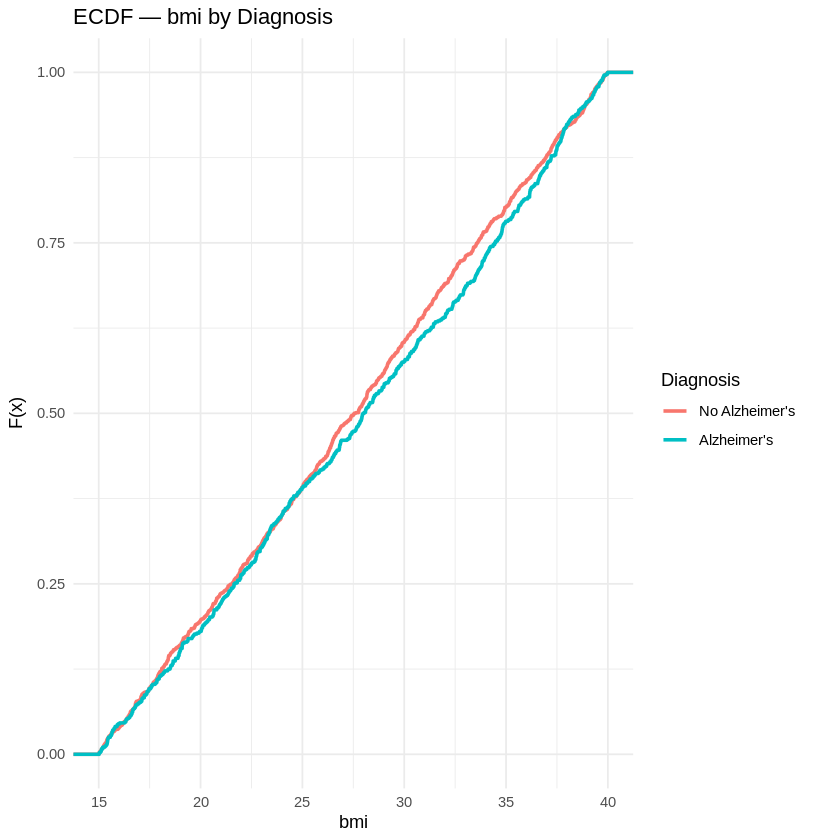

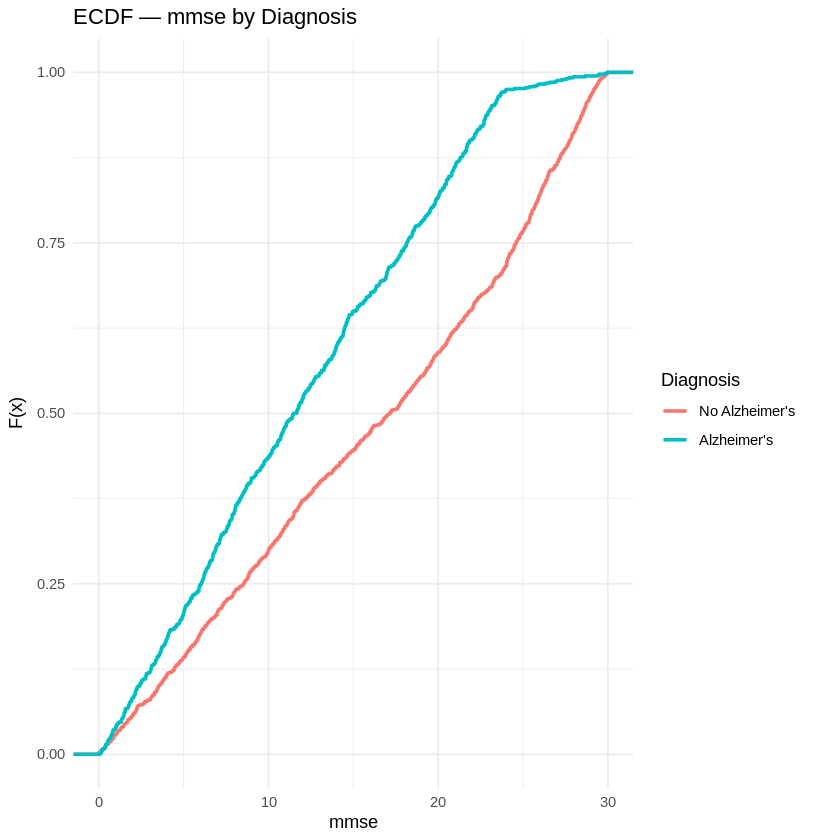

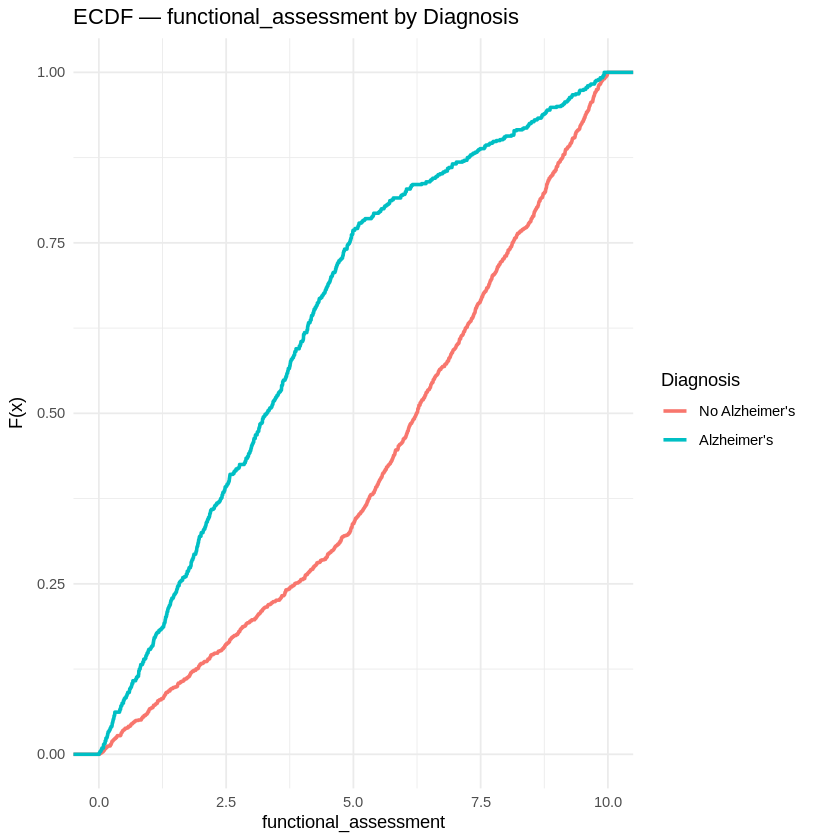

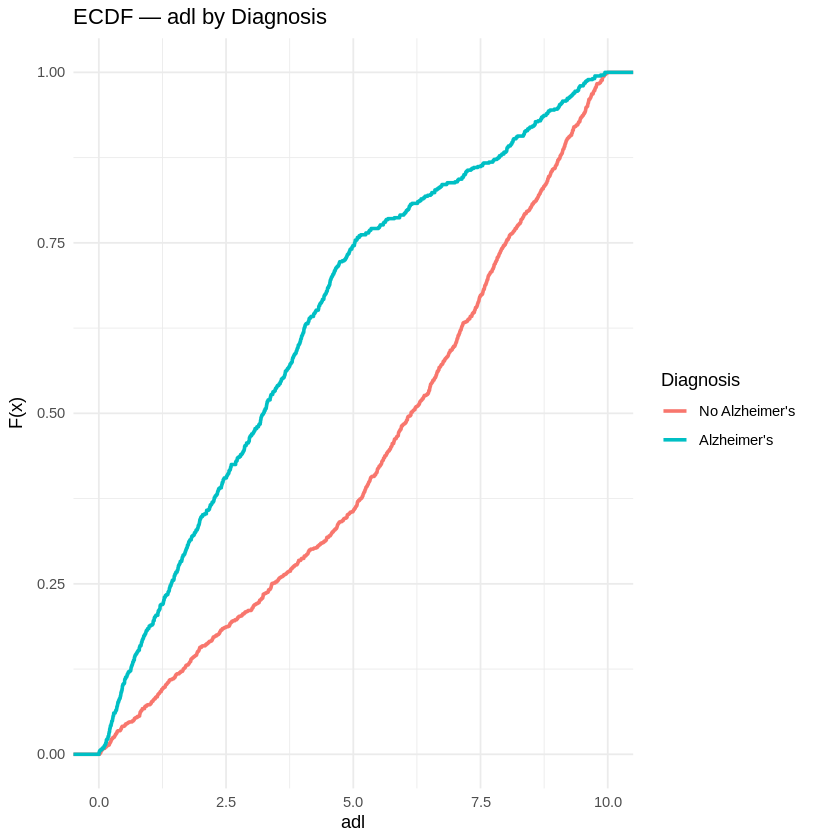

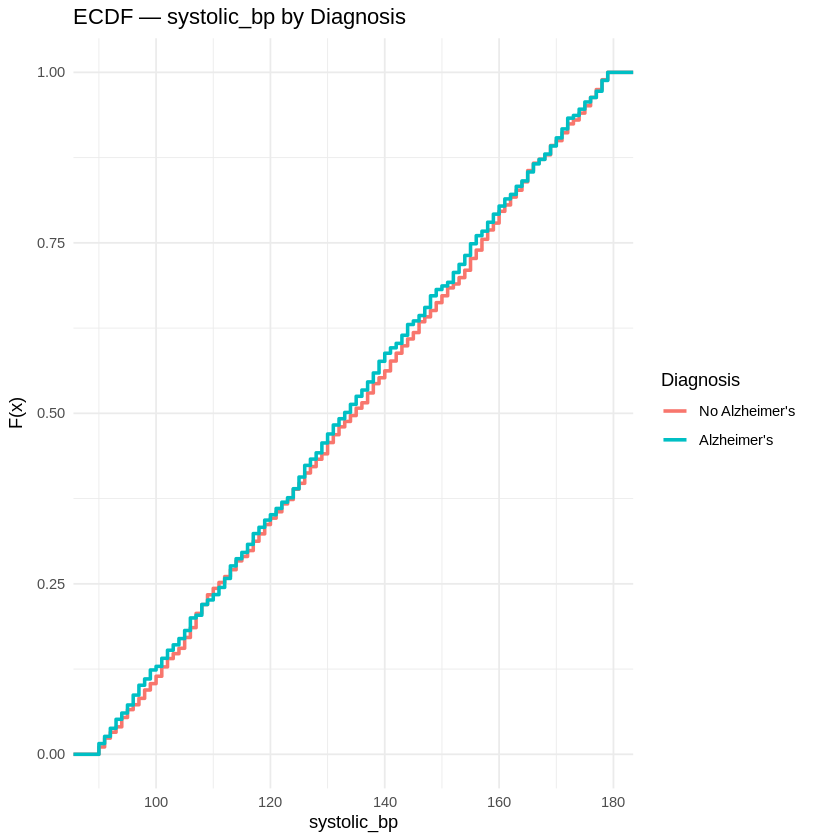

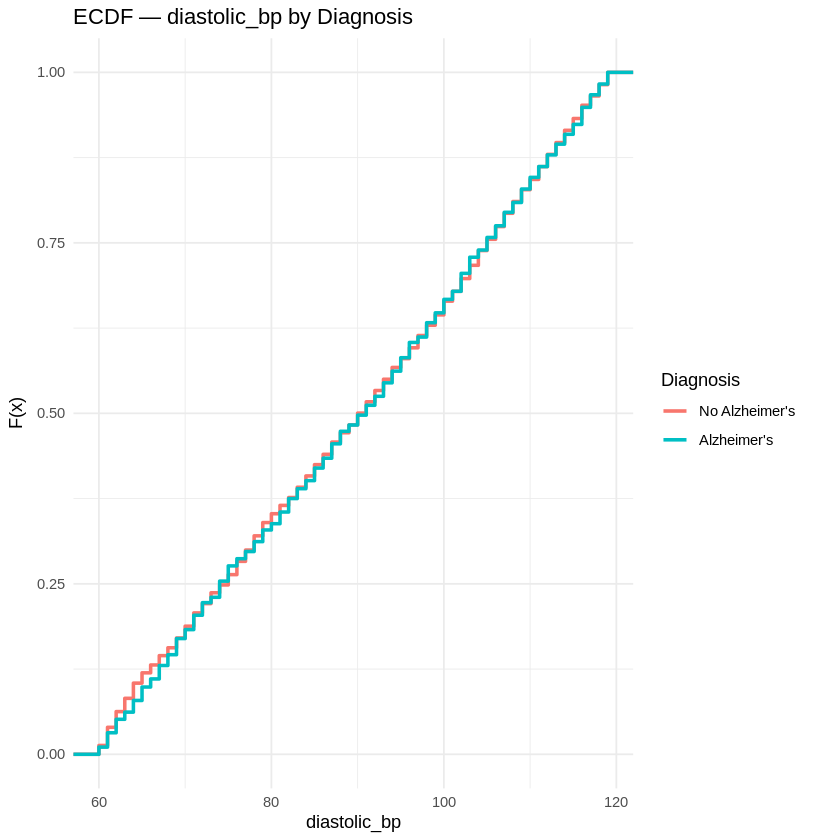

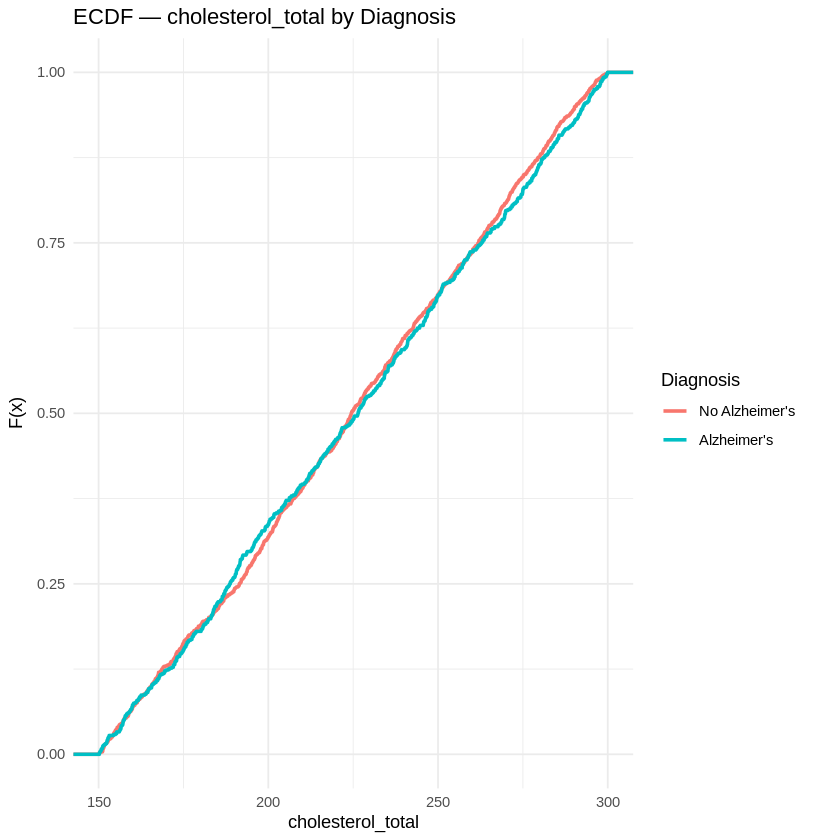

In [ ]:
for (v in key_vars) {
  p <- ggplot(df, aes(x = .data[[v]], color = diagnosis)) +
    stat_ecdf(geom = "step", linewidth = 1) +
    labs(title = paste("ECDF —", v, "by Diagnosis"), x = v, y = "F(x)", color = "Diagnosis") +
    theme_minimal()
  print(p)
}

Shapiro-Wilk normality test per variable

In [ ]:
cat("\n================ 5. SHAPIRO-WILK NORMALITY TEST ================\n")
for (v in key_vars) {
  x <- df[[v]]
  if (length(x) > 5000) x <- sample(x, 5000)
  sw <- shapiro.test(x)
  verdict <- ifelse(sw$p.value < 0.05, "NOT normal (reject H0)", "consistent with normal (fail to reject H0)")
  cat(sprintf("%-25s W = %.4f, p = %.4g  -> %s\n", v, sw$statistic, sw$p.value, verdict))
}



================ 5. SHAPIRO-WILK NORMALITY TEST ================
age                       W = 0.9523, p = 6.714e-26  -> NOT normal (reject H0)
bmi                       W = 0.9558, p = 5.05e-25  -> NOT normal (reject H0)
mmse                      W = 0.9525, p = 7.609e-26  -> NOT normal (reject H0)
functional_assessment     W = 0.9552, p = 3.608e-25  -> NOT normal (reject H0)
adl                       W = 0.9482, p = 7.18e-27  -> NOT normal (reject H0)
systolic_bp               W = 0.9551, p = 3.324e-25  -> NOT normal (reject H0)
diastolic_bp              W = 0.9494, p = 1.34e-26  -> NOT normal (reject H0)
cholesterol_total         W = 0.9590, p = 3.72e-24  -> NOT normal (reject H0)


Statistical Hypothesis Testing

Installs car, effectsize, effsize, ez, corrplot, etc. (with fallback messaging)

In [ ]:
pkgs <- c("car", "effectsize", "effsize", "ez","corrplot","e1071","factoextra","lubridate","VIM","mice")
for (p in pkgs) {
  if (!requireNamespace(p, quietly = TRUE)) {
    tryCatch(install.packages(p), error = function(e) {
      message(sprintf("Could not install '%s' (no internet / not in repo). ", p),
              "Fallback manual code is provided below where needed.")
    })
  }
}
suppressWarnings({
  library(car)          # leveneTest
  has_effectsize <- requireNamespace("effectsize", quietly = TRUE)
  has_effsize    <- requireNamespace("effsize", quietly = TRUE)
  has_ez         <- requireNamespace("ez", quietly = TRUE)
  if (has_effectsize) library(effectsize)   # eta_squared
  if (has_effsize)    library(effsize)      # cohen.d
  if (has_ez)         library(ez)           # ezANOVA
})

df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)
df$diagnosis       <- factor(df$diagnosis, labels = c("No Alzheimer's", "Alzheimer's"))
df$gender          <- factor(df$gender, labels = c("Male", "Female"))
df$smoking         <- factor(df$smoking, labels = c("Non-smoker", "Smoker"))
df$education_level <- factor(df$education_level,
                              labels = c("None", "High School", "Bachelor's", "Higher"))
df$patient_id      <- factor(df$patient_id)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘xgboost’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘glmnet’




Shapiro-Wilk per diagnosis group + Levene's test (variance homogeneity) for mmse by diagnosis and by education level

In [ ]:
cat("\n================ SHAPIRO-WILK PER GROUP (mmse by diagnosis) ================\n")
by(df$mmse, df$diagnosis, function(x) {
  x <- if (length(x) > 5000) sample(x, 5000) else x
  print(shapiro.test(x))
})

## ---- Equal variance — Levene's test ------------------------------------
## H0: variances are equal across groups.
## p < 0.05 => variances differ significantly => use Welch's t-test / ANOVA.
cat("\n================ LEVENE'S TEST (mmse ~ diagnosis) ================\n")
print(leveneTest(mmse ~ diagnosis, data = df))

cat("\n================ LEVENE'S TEST (mmse ~ education_level, 4 groups) ================\n")
print(leveneTest(mmse ~ education_level, data = df))


================ SHAPIRO-WILK PER GROUP (mmse by diagnosis) ================

	Shapiro-Wilk normality test

data:  x
W = 0.93707, p-value < 2.2e-16


	Shapiro-Wilk normality test

data:  x
W = 0.96344, p-value = 7.659e-13



df$diagnosis: No Alzheimer's

	Shapiro-Wilk normality test

data:  x
W = 0.93707, p-value < 2.2e-16

------------------------------------------------------------ 
df$diagnosis: Alzheimer's

	Shapiro-Wilk normality test

data:  x
W = 0.96344, p-value = 7.659e-13



================ LEVENE'S TEST (mmse ~ diagnosis) ================
Levene's Test for Homogeneity of Variance (center = median)
        Df F value    Pr(>F)    
group    1  81.287 < 2.2e-16 ***
      2147                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

================ LEVENE'S TEST (mmse ~ education_level, 4 groups) ================
Levene's Test for Homogeneity of Variance (center = median)
        Df F value Pr(>F)
group    3  0.9495 0.4158
      2145               


Welch's independent t-test (mmse ~ diagnosis) + an illustrative paired t-test (systolic vs diastolic BP) + Cohen's d effect size (with manual fallback)

In [ ]:
cat("\n================ INDEPENDENT SAMPLES T-TEST (Welch) — mmse ~ diagnosis ================\n")
t_ind <- t.test(mmse ~ diagnosis, data = df, var.equal = FALSE)
print(t_ind)

## ---- Paired (dependent) t-test -----------------------------------------
## No repeated pre/post measurements exist in this cross-sectional dataset.
## Demonstrated here on two measurements taken on the SAME subject
## (systolic vs diastolic BP) purely to illustrate the paired-test syntax.
## Replace with a genuine before/after pair if you have longitudinal data.
cat("\n================ PAIRED T-TEST (illustrative: systolic vs diastolic BP) ================\n")
t_paired <- t.test(df$systolic_bp, df$diastolic_bp, paired = TRUE)
print(t_paired)

## ---- Effect size — Cohen's d -------------------------------------------
## ~0.2 small, ~0.5 medium, ~0.8 large
cat("\n================ COHEN'S D — mmse by diagnosis ================\n")
if (has_effsize) {
  print(cohen.d(mmse ~ diagnosis, data = df))
} else {
  ## Manual fallback (pooled-SD Cohen's d) if effsize isn't installed
  g1 <- df$mmse[df$diagnosis == levels(df$diagnosis)[1]]
  g2 <- df$mmse[df$diagnosis == levels(df$diagnosis)[2]]
  n1 <- length(g1); n2 <- length(g2)
  pooled_sd <- sqrt(((n1 - 1) * var(g1) + (n2 - 1) * var(g2)) / (n1 + n2 - 2))
  d <- (mean(g1) - mean(g2)) / pooled_sd
  cat(sprintf("Cohen's d (manual) = %.3f\n", d))
}



================ INDEPENDENT SAMPLES T-TEST (Welch) — mmse ~ diagnosis ================

	Welch Two Sample t-test

data:  mmse by diagnosis
t = 12.025, df = 1851.4, p-value < 2.2e-16
alternative hypothesis: true difference in means between group No Alzheimer's and group Alzheimer's is not equal to 0
95 percent confidence interval:
 3.574302 4.967469
sample estimates:
mean in group No Alzheimer's    mean in group Alzheimer's 
                    16.26554                     11.99466 


================ PAIRED T-TEST (illustrative: systolic vs diastolic BP) ================

	Paired t-test

data:  df$systolic_bp and df$diastolic_bp
t = 65.757, df = 2148, p-value < 2.2e-16
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 43.09230 45.74158
sample estimates:
mean difference 
       44.41694 


================ COHEN'S D — mmse by diagnosis ================

Cohen's d

d estimate: 0.510295 (medium)
95 percent confidence interval:
    lower     

One-way ANOVA (mmse ~ education_level) and two-way ANOVA (mmse ~ gender*smoking)

In [ ]:
cat("\n================ ONE-WAY ANOVA — mmse ~ education_level ================\n")
aov_one <- aov(mmse ~ education_level, data = df)
print(summary(aov_one))
# Post-hoc if significant:
# TukeyHSD(aov_one)

## ---- Factorial (two-way) ANOVA -----------------------------------------
## Tests gender, smoking, AND their interaction on MMSE at once.
cat("\n================ TWO-WAY ANOVA — mmse ~ gender * smoking ================\n")
aov_two <- aov(mmse ~ gender * smoking, data = df)
print(summary(aov_two))



================ ONE-WAY ANOVA — mmse ~ education_level ================
                  Df Sum Sq Mean Sq F value Pr(>F)
education_level    3    220   73.40   0.989  0.397
Residuals       2145 159132   74.19               

================ TWO-WAY ANOVA — mmse ~ gender * smoking ================
                 Df Sum Sq Mean Sq F value Pr(>F)
gender            1    102  102.24   1.378  0.241
smoking           1      0    0.47   0.006  0.937
gender:smoking    1     78   77.90   1.050  0.306
Residuals      2145 159172   74.21               


Repeated-measures ANOVA (illustrative, using ez if available)

In [ ]:
cat("\n================ REPEATED-MEASURES ANOVA (illustrative) ================\n")
if (has_ez) {
  rm_long <- data.frame(
    patient_id = rep(df$patient_id, 2),
    condition  = factor(rep(c("systolic", "diastolic"), each = nrow(df))),
    bp         = c(df$systolic_bp, df$diastolic_bp)
  )
  rm_result <- ezANOVA(data = rm_long, dv = .(bp), wid = .(patient_id),
                        within = .(condition), detailed = TRUE)
  print(rm_result)
} else {
  cat("Package 'ez' not available in this environment.\n",
      "Install with install.packages('ez') where internet access allows, or use:\n",
      "  aov(bp ~ condition + Error(patient_id/condition), data = rm_long)\n", sep = "")
}



================ REPEATED-MEASURES ANOVA (illustrative) ================
$ANOVA
       Effect DFn  DFd      SSn     SSd          F p p<.05       ges
1 (Intercept)   1 2148 53968334 1058136 109554.858 0     * 0.9623536
2   condition   1 2148  2119843 1053057   4324.003 0     * 0.5010221



ANCOVA (mmse ~ age + diagnosis)

In [ ]:
cat("\n================ ANCOVA — mmse ~ age + diagnosis ================\n")
ancova_model <- aov(mmse ~ age + diagnosis, data = df)
print(summary(ancova_model))


================ ANCOVA — mmse ~ age + diagnosis ================
              Df Sum Sq Mean Sq F value Pr(>F)    
age            1      3       3   0.041   0.84    
diagnosis      1   8962    8962 127.889 <2e-16 ***
Residuals   2146 150387      70                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


MANOVA (mmse, functional_assessment, adl ~ diagnosis) with Pillai's and Wilks' tests

In [ ]:
cat("\n================ MANOVA — cbind(mmse, functional_assessment, adl) ~ diagnosis ================\n")
manova_model <- manova(cbind(mmse, functional_assessment, adl) ~ diagnosis, data = df)
print(summary(manova_model))          # Pillai's trace (default, robust)
print(summary(manova_model, test = "Wilks"))


================ MANOVA — cbind(mmse, functional_assessment, adl) ~ diagnosis ================
            Df  Pillai approx F num Df den Df    Pr(>F)    
diagnosis    1 0.28294   282.13      3   2145 < 2.2e-16 ***
Residuals 2147                                             
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
            Df   Wilks approx F num Df den Df    Pr(>F)    
diagnosis    1 0.71706   282.13      3   2145 < 2.2e-16 ***
Residuals 2147                                             
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


Eta-squared effect sizes for the ANOVAs

In [ ]:
cat("\n================ ETA SQUARED — one-way ANOVA (education_level) ================\n")
if (has_effectsize) {
  print(eta_squared(aov_one))
  cat("\n================ ETA SQUARED — two-way ANOVA (gender * smoking) ================\n")
  print(eta_squared(aov_two))
} else {
  ## Manual fallback: eta^2 = SS_effect / SS_total
  ss <- summary(aov_one)[[1]][["Sum Sq"]]
  eta2 <- ss[1] / sum(ss)
  cat(sprintf("Eta squared (manual, one-way) = %.4f\n", eta2))
}



================ ETA SQUARED — one-way ANOVA (education_level) ================


For one-way between subjects designs, partial eta squared is equivalent
  to eta squared. Returning eta squared.



# Effect Size for ANOVA

Parameter       |     Eta2 |       95% CI
-----------------------------------------
education_level | 1.38e-03 | [0.00, 1.00]

- One-sided CIs: upper bound fixed at [1.00].
================ ETA SQUARED — two-way ANOVA (gender * smoking) ================
# Effect Size for ANOVA (Type I)

Parameter      | Eta2 (partial) |       95% CI
----------------------------------------------
gender         |       6.42e-04 | [0.00, 1.00]
smoking        |       2.95e-06 | [0.00, 1.00]
gender:smoking |       4.89e-04 | [0.00, 1.00]

- One-sided CIs: upper bound fixed at [1.00].

# Sampling Techniques

In [ ]:
library(dplyr)

# Set seed for reproducibility
set.seed(123)

Simple random sampling (20%)

In [ ]:
simple_sample <- df %>%
  sample_frac(size = 0.20)

cat("Simple Random Sample Size:", nrow(simple_sample), "\n")
head(simple_sample)

Simple Random Sample Size: 430 


,patient_id,age,gender,ethnicity,education_level,bmi,smoking,alcohol_consumption,physical_activity,diet_quality,⋯,functional_assessment,memory_complaints,behavioral_problems,adl,confusion,disorientation,personality_changes,difficulty_completing_tasks,forgetfulness,diagnosis
,<fct>,<int>,<fct>,<int>,<fct>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<fct>
1,5276,60,Female,0,Bachelor's,32.48259,Non-smoker,18.829069,4.490351,6.666395,⋯,2.742409,1,1,3.2232646,0,0,0,0,0,No Alzheimer's
2,4945,60,Male,0,None,36.36889,Non-smoker,14.237706,9.947910,3.586005,⋯,1.798195,0,0,0.7634527,0,0,0,0,1,Alzheimer's
3,6592,80,Male,0,None,28.16198,Non-smoker,13.824729,3.520582,7.155749,⋯,1.395568,0,0,1.7871812,0,0,0,0,0,No Alzheimer's
4,5892,65,Female,1,Higher,20.61119,Smoker,18.950727,1.027082,9.355518,⋯,7.539818,0,0,9.6576972,0,1,0,0,1,No Alzheimer's
5,6003,72,Male,0,High School,16.33222,Non-smoker,7.781003,7.532527,6.714228,⋯,8.753678,0,0,7.1454510,0,0,0,0,0,No Alzheimer's
6,6018,76,Female,0,High School,25.88211,Non-smoker,8.371249,4.124016,6.401486,⋯,2.132824,0,0,2.9465334,0,1,0,0,0,Alzheimer's


Systematic sampling (every 5th row)

In [ ]:
k <- 5   # every 5th row

start <- sample(1:k, 1)

systematic_sample <- df[seq(start, nrow(df), by = k), ]

cat("Systematic Sample Size:", nrow(systematic_sample), "\n")
head(systematic_sample)

Systematic Sample Size: 430 


,patient_id,age,gender,ethnicity,education_level,bmi,smoking,alcohol_consumption,physical_activity,diet_quality,⋯,functional_assessment,memory_complaints,behavioral_problems,adl,confusion,disorientation,personality_changes,difficulty_completing_tasks,forgetfulness,diagnosis
,<fct>,<int>,<fct>,<int>,<fct>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<fct>
4,4754,74,Female,0,High School,33.80082,Smoker,12.209266,8.4280014,7.435604,⋯,8.965106,0,1,6.4812259,0,0,0,0,0,No Alzheimer's
9,4759,72,Female,1,None,27.83319,Non-smoker,12.167848,1.5313598,6.736882,⋯,7.396061,0,1,0.7562318,0,0,1,0,0,No Alzheimer's
14,4764,78,Female,0,High School,28.87065,Smoker,10.194706,0.6312807,1.653281,⋯,4.510713,1,0,1.9395955,0,1,0,0,0,Alzheimer's
19,4769,72,Male,0,Bachelor's,37.93247,Non-smoker,9.385603,7.1279399,3.314983,⋯,5.189536,0,0,7.4981139,0,0,0,0,1,No Alzheimer's
24,4774,82,Female,2,High School,21.96939,Non-smoker,3.289650,6.9347264,3.242343,⋯,8.446629,1,0,4.5725203,0,0,0,0,0,Alzheimer's
29,4779,83,Male,0,High School,30.95365,Non-smoker,4.692219,0.4426909,1.289252,⋯,8.153339,1,0,2.1116386,1,0,0,0,0,No Alzheimer's


Stratified sampling by first factor column, with proportion comparison

In [ ]:
factor_cols <- names(df)[sapply(df, is.factor)]

if(length(factor_cols) > 0){

  strat_var <- factor_cols[1]

  cat("Stratified Sampling Variable:", strat_var, "\n")

  stratified_sample <- df %>%
    group_by(.data[[strat_var]]) %>%
    sample_frac(0.20) %>%
    ungroup()

  cat("Stratified Sample Size:", nrow(stratified_sample), "\n")

  # Compare proportions
  cat("\nOriginal Distribution:\n")
  print(prop.table(table(df[[strat_var]])))

  cat("\nSample Distribution:\n")
  print(prop.table(table(stratified_sample[[strat_var]])))

} else{

  cat("No categorical (factor) variable found for stratified sampling.\n")

}

Stratified Sampling Variable: patient_id 
Stratified Sample Size: 0 

Original Distribution:

        4751         4752         4753         4754         4755         4756 
0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 
        4757         4758         4759         4760         4761         4762 
0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 
        4763         4764         4765         4766         4767         4768 
0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 
        4769         4770         4771         4772         4773         4774 
0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 
        4775         4776         4777         4778         4779         4780 
0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 0.0004653327 
        4781         4782         4783         4784         4785         4786 
0.0004653327 0.0004653327 0.000465332

Cluster sampling (selecting half the clusters of a factor variable)

In [ ]:
if(length(factor_cols) > 0){

  cluster_var <- factor_cols[1]

  clusters <- unique(df[[cluster_var]])

  selected_clusters <- sample(clusters,
                              ceiling(length(clusters)/2))

  cluster_sample <- df %>%
    filter(.data[[cluster_var]] %in% selected_clusters)

  cat("Cluster Variable:", cluster_var, "\n")
  cat("Selected Clusters:\n")
  print(selected_clusters)

  cat("Cluster Sample Size:", nrow(cluster_sample), "\n")

} else{

  cat("No categorical variable available for cluster sampling.\n")

}

Cluster Variable: patient_id 
Selected Clusters:
   [1] 6014 5641 6406 6636 6078 5415 6785 6386 5543 6162 5954 5028 4991 4774
  [15] 6477 6835 6077 6493 6817 6445 5128 5299 6389 6018 6846 5143 6145 5420
  [29] 5963 5061 6192 6156 6836 5858 5069 6612 6416 4870 6307 5349 6089 5829
  [43] 4884 5174 6804 5629 5418 6574 4799 6250 4943 5053 4941 6401 5567 6196
  [57] 6066 6147 6309 6374 5700 6187 5448 6537 5977 5508 5743 6214 5001 5393
  [71] 5740 6096 6894 6267 6198 5195 4845 5129 6116 5370 5198 4992 6742 5157
  [85] 6248 6215 4968 5398 4829 6281 5329 6581 5172 5243 5480 6570 6860 5627
  [99] 5815 5654 5598 5636 5200 6006 6108 5146 6504 6614 5389 4791 6038 6471
 [113] 4951 4802 5999 4817 5430 6544 5327 5207 5765 6677 6747 6315 5794 5980
 [127] 4874 5342 6549 5490 4795 6106 6055 4841 5403 6754 5912 5356 4877 6199
 [141] 6554 5782 5589 6045 5345 6719 5497 5941 5249 6029 6803 6408 5681 5652
 [155] 4821 6546 4831 6718 5526 6211 6353 5626 5646 6740 6524 5747 5020 6186
 [169] 6420 4887 5423 5378 

Bootstrap sampling (resampling with replacement)

In [ ]:
bootstrap_sample <- df %>%
  slice_sample(n = nrow(df), replace = TRUE)

cat("Bootstrap Sample Size:", nrow(bootstrap_sample), "\n")

head(bootstrap_sample)


Bootstrap Sample Size: 2149 


,patient_id,age,gender,ethnicity,education_level,bmi,smoking,alcohol_consumption,physical_activity,diet_quality,⋯,functional_assessment,memory_complaints,behavioral_problems,adl,confusion,disorientation,personality_changes,difficulty_completing_tasks,forgetfulness,diagnosis
,<fct>,<int>,<fct>,<int>,<fct>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<fct>
1,6390,78,Female,0,Bachelor's,34.63975,Smoker,17.457739,6.517930,0.4809043,⋯,1.062178,1,0,2.1765154,0,0,0,1,1,Alzheimer's
2,6786,62,Female,3,Bachelor's,22.75985,Smoker,8.003971,9.564389,9.8990237,⋯,3.970165,1,0,6.0941655,0,1,1,0,0,Alzheimer's
3,6224,72,Female,0,None,23.09432,Non-smoker,4.181355,6.003548,0.1001968,⋯,1.576872,1,0,8.4722538,0,0,0,1,0,Alzheimer's
4,6176,76,Female,2,Bachelor's,19.96367,Smoker,11.624876,9.257001,0.3492444,⋯,1.283810,0,0,0.8014056,0,0,0,0,1,No Alzheimer's
5,6869,70,Male,0,High School,37.07998,Smoker,12.797561,3.519902,6.7887930,⋯,3.748489,0,0,6.6325719,0,0,0,0,0,No Alzheimer's
6,5609,64,Male,0,Bachelor's,29.02333,Non-smoker,12.057724,1.776613,2.9845463,⋯,3.399955,0,0,7.6055839,0,0,0,0,1,No Alzheimer's


Summary table comparing sample sizes across methods

In [ ]:
sample_summary <- data.frame(

  Technique = c(
    "Original",
    "Simple Random",
    "Systematic",
    "Stratified",
    "Cluster",
    "Bootstrap"
  ),

  Sample_Size = c(
    nrow(df),
    nrow(simple_sample),
    nrow(systematic_sample),
    if(exists("stratified_sample")) nrow(stratified_sample) else NA,
    if(exists("cluster_sample")) nrow(cluster_sample) else NA,
    nrow(bootstrap_sample)
  )

)

print(sample_summary)

      Technique Sample_Size
1      Original        2149
2 Simple Random         430
3    Systematic         430
4    Stratified           0
5       Cluster        1075
6     Bootstrap        2149


# COVARIANCE, CORRELATION & VARIANCE

In [ ]:
library(dplyr)
library(corrplot)
library(car)

corrplot 0.95 loaded



Variance per numeric variable, sorted descending

In [ ]:
numeric_data <- df %>%
  select(where(is.numeric))

cat("Number of Numeric Variables:", ncol(numeric_data), "\n")
print(names(numeric_data))

Number of Numeric Variables: 29 
 [1] "age"                         "ethnicity"                  
 [3] "bmi"                         "alcohol_consumption"        
 [5] "physical_activity"           "diet_quality"               
 [7] "sleep_quality"               "family_history_alzheimers"  
 [9] "cardiovascular_disease"      "diabetes"                   
[11] "depression"                  "head_injury"                
[13] "hypertension"                "systolic_bp"                
[15] "diastolic_bp"                "cholesterol_total"          
[17] "cholesterol_ldl"             "cholesterol_hdl"            
[19] "cholesterol_triglycerides"   "mmse"                       
[21] "functional_assessment"       "memory_complaints"          
[23] "behavioral_problems"         "adl"                        
[25] "confusion"                   "disorientation"             
[27] "personality_changes"         "difficulty_completing_tasks"
[29] "forgetfulness"              


In [ ]:
cat("\n================ VARIANCE ================\n")

variance_values <- sapply(numeric_data, var, na.rm = TRUE)

variance_table <- data.frame(
  Variable = names(variance_values),
  Variance = round(variance_values, 4)
)

variance_table <- variance_table %>%
  arrange(desc(Variance))

print(variance_table)


================ VARIANCE ================
                                               Variable   Variance
cholesterol_triglycerides     cholesterol_triglycerides 10401.2912
cholesterol_ldl                         cholesterol_ldl  1880.6606
cholesterol_total                     cholesterol_total  1809.8416
systolic_bp                                 systolic_bp   673.3689
cholesterol_hdl                         cholesterol_hdl   535.4214
diastolic_bp                               diastolic_bp   309.4959
age                                                 age    80.8241
mmse                                               mmse    74.1864
bmi                                                 bmi    52.0914
alcohol_consumption                 alcohol_consumption    33.1535
adl                                                 adl     8.7012
diet_quality                               diet_quality     8.4626
functional_assessment             functional_assessment     8.3680
physical_activity 

Covariance matrix

In [ ]:
cat("\n================ COVARIANCE MATRIX ================\n")

cov_matrix <- cov(numeric_data,
                  use = "complete.obs")

print(round(cov_matrix,3))


================ COVARIANCE MATRIX ================
                               age ethnicity     bmi alcohol_consumption
age                         80.824     0.248  -1.017               0.379
ethnicity                    0.248     0.992  -0.023               0.048
bmi                         -1.017    -0.023  52.091              -0.374
alcohol_consumption          0.379     0.048  -0.374              33.154
physical_activity           -0.263     0.058   0.015               0.357
diet_quality                -0.612    -0.053   0.418               0.337
sleep_quality                0.779     0.051  -0.076              -0.039
family_history_alzheimers   -0.073     0.010   0.020              -0.009
cardiovascular_disease      -0.048     0.001  -0.014              -0.048
diabetes                    -0.018    -0.007  -0.023               0.000
depression                  -0.032    -0.002  -0.036               0.020
head_injury                 -0.105    -0.003   0.034              -0.01

**Pearson, Spearman, and Kendall correlation matrices**


================ PEARSON CORRELATION ================
                               age ethnicity    bmi alcohol_consumption
age                          1.000     0.028 -0.016               0.007
ethnicity                    0.028     1.000 -0.003               0.008
bmi                         -0.016    -0.003  1.000              -0.009
alcohol_consumption          0.007     0.008 -0.009               1.000
physical_activity           -0.010     0.020  0.001               0.022
diet_quality                -0.023    -0.018  0.020               0.020
sleep_quality                0.049     0.029 -0.006              -0.004
family_history_alzheimers   -0.019     0.023  0.006              -0.004
cardiovascular_disease      -0.015     0.002 -0.005              -0.024
diabetes                    -0.006    -0.020 -0.009               0.000
depression                  -0.009    -0.005 -0.013               0.009
head_injury                 -0.040    -0.009  0.016              -0.008
hypertens

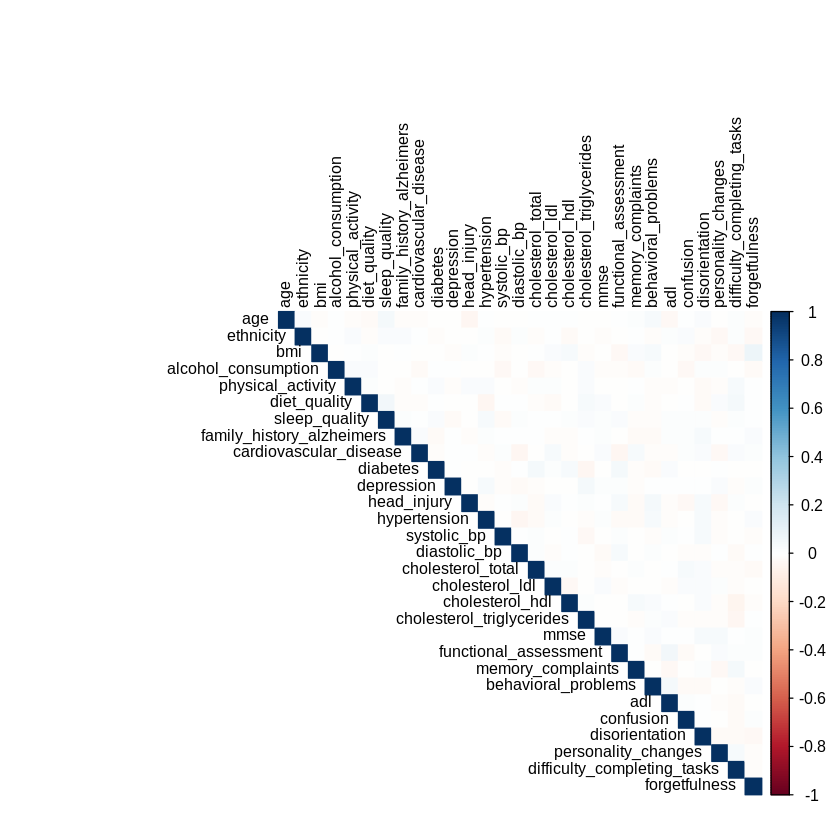

In [ ]:
cat("\n================ PEARSON CORRELATION ================\n")

pearson_corr <- cor(
  numeric_data,
  method = "pearson",
  use = "complete.obs"
)

print(round(pearson_corr,3))

corrplot(
  pearson_corr,
  method = "color",
  type = "upper",
  tl.col = "black",
  tl.cex = 0.8,
  number.cex = 0.7
)

In [ ]:
cat("\n================ SPEARMAN CORRELATION ================\n")

spearman_corr <- cor(
  numeric_data,
  method = "spearman",
  use = "complete.obs"
)

print(round(spearman_corr,3))



================ SPEARMAN CORRELATION ================
                               age ethnicity    bmi alcohol_consumption
age                          1.000     0.018 -0.016               0.008
ethnicity                    0.018     1.000 -0.008               0.008
bmi                         -0.016    -0.008  1.000              -0.009
alcohol_consumption          0.008     0.008 -0.009               1.000
physical_activity           -0.011     0.022  0.000               0.023
diet_quality                -0.024    -0.022  0.020               0.020
sleep_quality                0.048     0.029 -0.006              -0.004
family_history_alzheimers   -0.018     0.024  0.007              -0.004
cardiovascular_disease      -0.015     0.003 -0.006              -0.024
diabetes                    -0.005    -0.019 -0.009               0.000
depression                  -0.009    -0.006 -0.012               0.009
head_injury                 -0.040    -0.007  0.016              -0.008
hyperten

In [ ]:
cat("\n================ KENDALL TAU ================\n")

kendall_corr <- cor(
  numeric_data,
  method = "kendall",
  use = "complete.obs"
)

print(round(kendall_corr,3))


================ KENDALL TAU ================
                               age ethnicity    bmi alcohol_consumption
age                          1.000     0.014 -0.011               0.005
ethnicity                    0.014     1.000 -0.006               0.006
bmi                         -0.011    -0.006  1.000              -0.006
alcohol_consumption          0.005     0.006 -0.006               1.000
physical_activity           -0.007     0.017  0.000               0.015
diet_quality                -0.016    -0.017  0.013               0.013
sleep_quality                0.032     0.022 -0.004              -0.003
family_history_alzheimers   -0.015     0.023  0.005              -0.003
cardiovascular_disease      -0.012     0.003 -0.005              -0.019
diabetes                    -0.004    -0.018 -0.007               0.000
depression                  -0.007    -0.006 -0.010               0.007
head_injury                 -0.034    -0.006  0.013              -0.007
hypertension     

Correlation pairs flattened, deduplicated, sorted by absolute strength

In [ ]:
corr_pairs <- as.data.frame(as.table(pearson_corr))

names(corr_pairs) <- c("Variable1",
                       "Variable2",
                       "Correlation")

corr_pairs <- corr_pairs %>%
  filter(Variable1 != Variable2)

corr_pairs$pair <- apply(
  corr_pairs[,1:2],
  1,
  function(x) paste(sort(x), collapse = "_")
)

corr_pairs <- corr_pairs %>%
  distinct(pair, .keep_all = TRUE)

corr_pairs <- corr_pairs %>%
  mutate(AbsCorrelation = abs(Correlation)) %>%
  arrange(desc(AbsCorrelation))

cat("\n================ STRONGEST CORRELATIONS ================\n")

print(head(corr_pairs[,1:3],10))


================ STRONGEST CORRELATIONS ================
                     Variable1             Variable2 Correlation
1                forgetfulness                   bmi  0.07113117
2  difficulty_completing_tasks       cholesterol_hdl -0.05694678
3                          adl functional_assessment  0.05390426
4                sleep_quality          diet_quality  0.05129523
5                sleep_quality                   age  0.04913918
6            cholesterol_total              diabetes  0.04876683
7          behavioral_problems           head_injury  0.04764930
8  difficulty_completing_tasks          diet_quality  0.04573672
9    cholesterol_triglycerides              diabetes -0.04490599
10 difficulty_completing_tasks     memory_complaints  0.04415126


**Correlation plot**

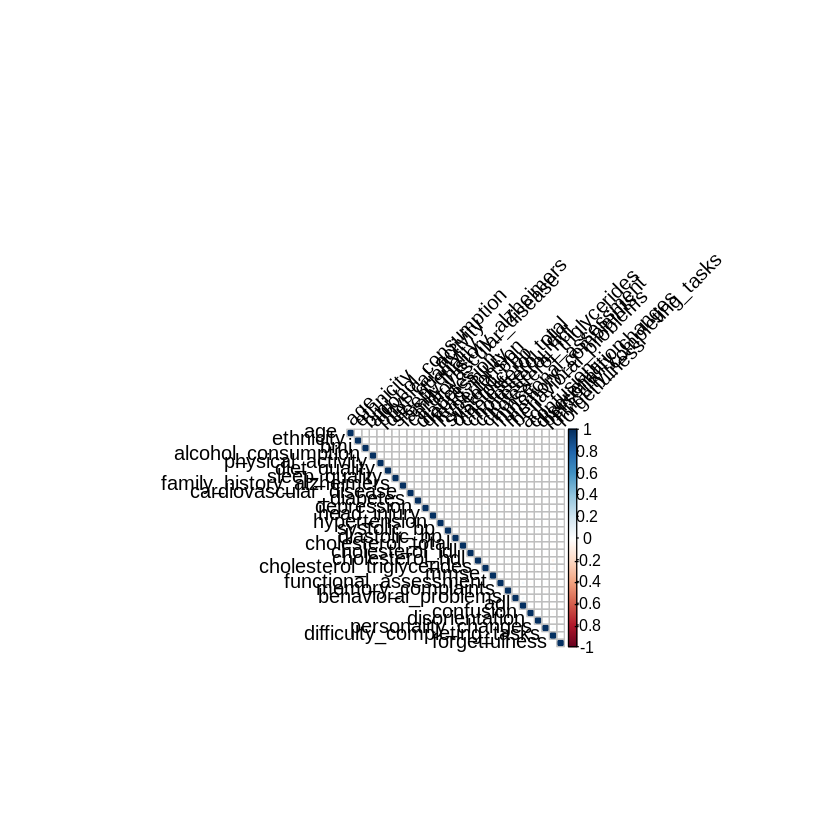

In [ ]:
corrplot(
  pearson_corr,
  method = "circle",
  type = "upper",
  tl.col = "black",
  tl.srt = 45
)

In [ ]:
library(e1071)

#Data Transformation Comparison

In [ ]:
numeric_data <- df %>%
  select(where(is.numeric))

cat("Numeric Variables:\n")
print(names(numeric_data))


Numeric Variables:
 [1] "age"                         "ethnicity"                  
 [3] "bmi"                         "alcohol_consumption"        
 [5] "physical_activity"           "diet_quality"               
 [7] "sleep_quality"               "family_history_alzheimers"  
 [9] "cardiovascular_disease"      "diabetes"                   
[11] "depression"                  "head_injury"                
[13] "hypertension"                "systolic_bp"                
[15] "diastolic_bp"                "cholesterol_total"          
[17] "cholesterol_ldl"             "cholesterol_hdl"            
[19] "cholesterol_triglycerides"   "mmse"                       
[21] "functional_assessment"       "memory_complaints"          
[23] "behavioral_problems"         "adl"                        
[25] "confusion"                   "disorientation"             
[27] "personality_changes"         "difficulty_completing_tasks"
[29] "forgetfulness"              


**Z-score, Min-Max, Robust (median/IQR), Log, and Decimal scaling functions applied to numeric data**

In [ ]:
zscore_data <- as.data.frame(scale(numeric_data))


In [ ]:
minmax_data <- as.data.frame(lapply(numeric_data, function(x){

  (x - min(x, na.rm = TRUE)) /
    (max(x, na.rm = TRUE) - min(x, na.rm = TRUE))

}))

In [ ]:
robust_data <- as.data.frame(lapply(numeric_data, function(x){

  (x - median(x, na.rm = TRUE)) /
    IQR(x, na.rm = TRUE)

}))

In [ ]:
log_data <- as.data.frame(lapply(numeric_data, function(x){

  if(min(x, na.rm=TRUE) <= 0){

    x <- x - min(x, na.rm=TRUE) + 1

  }

  log(x)

}))

In [ ]:
decimal_data <- as.data.frame(lapply(numeric_data, function(x){

  j <- ceiling(log10(max(abs(x), na.rm=TRUE)+1))

  x/(10^j)

}))

Helper functions: average absolute skewness, IQR-based outlier counting

In [ ]:
avg_skewness <- function(data){

  mean(abs(sapply(data,function(x)
    skewness(x, na.rm=TRUE))), na.rm=TRUE)

}


In [ ]:
count_outliers <- function(data){

  total <- 0

  for(i in seq_along(data)){

    x <- data[[i]]

    q1 <- quantile(x,0.25,na.rm=TRUE)

    q3 <- quantile(x,0.75,na.rm=TRUE)

    iqr <- q3-q1

    lower <- q1-1.5*iqr

    upper <- q3+1.5*iqr

    total <- total + sum(x<lower | x>upper,na.rm=TRUE)

  }

  total

}

Comparison table scoring each transformation method by skewness + outlier count, sorted to find the "best" method

In [ ]:
comparison <- data.frame(

  Method=c("Original",
           "Z-score",
           "Min-Max",
           "Robust",
           "Log",
           "Decimal"),

  Avg_Abs_Skewness=c(

    avg_skewness(numeric_data),

    avg_skewness(zscore_data),

    avg_skewness(minmax_data),

    avg_skewness(robust_data),

    avg_skewness(log_data),

    avg_skewness(decimal_data)

  ),

  Outliers=c(

    count_outliers(numeric_data),

    count_outliers(zscore_data),

    count_outliers(minmax_data),

    count_outliers(robust_data),

    count_outliers(log_data),

    count_outliers(decimal_data)

  )

)

comparison$Score <-
comparison$Avg_Abs_Skewness +
comparison$Outliers/100

comparison <- comparison %>%
  arrange(Score)


In [ ]:
cat("\n================ COMPARISON TABLE ================\n")

print(comparison)


================ COMPARISON TABLE ================
    Method Avg_Abs_Skewness Outliers     Score
1   Robust        0.2078928      211  2.317893
2 Original        0.8435617     4025 41.093562
3  Z-score        0.8435617     4025 41.093562
4  Min-Max        0.8435617     4025 41.093562
5  Decimal        0.8435617     4025 41.093562
6      Log        1.3275670     4464 45.967567


In [ ]:
best_method <- comparison$Method[1]

cat("\n=============================================\n")
cat("BEST TRANSFORMATION METHOD:", best_method,"\n")
cat("=============================================\n")


BEST TRANSFORMATION METHOD: Robust 


**Histogram and boxplot grids comparing all transformations side-by-side**

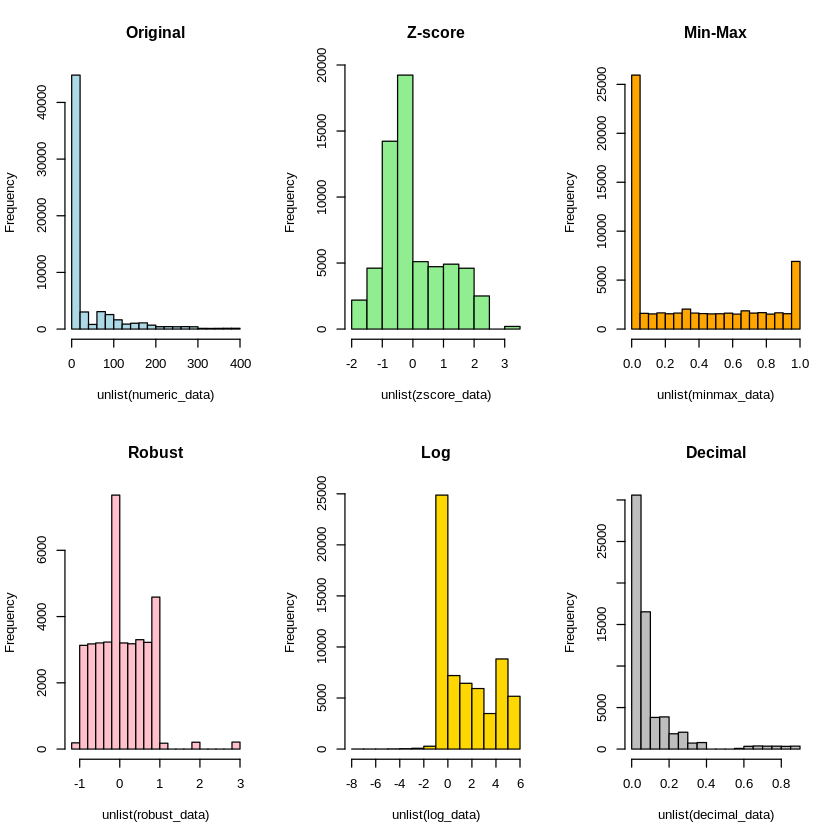

In [ ]:
par(mfrow=c(2,3))

hist(unlist(numeric_data),
     main="Original",
     col="lightblue")

hist(unlist(zscore_data),
     main="Z-score",
     col="lightgreen")

hist(unlist(minmax_data),
     main="Min-Max",
     col="orange")

hist(unlist(robust_data),
     main="Robust",
     col="pink")

hist(unlist(log_data),
     main="Log",
     col="gold")

hist(unlist(decimal_data),
     main="Decimal",
     col="gray")

par(mfrow=c(1,1))

Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warnin

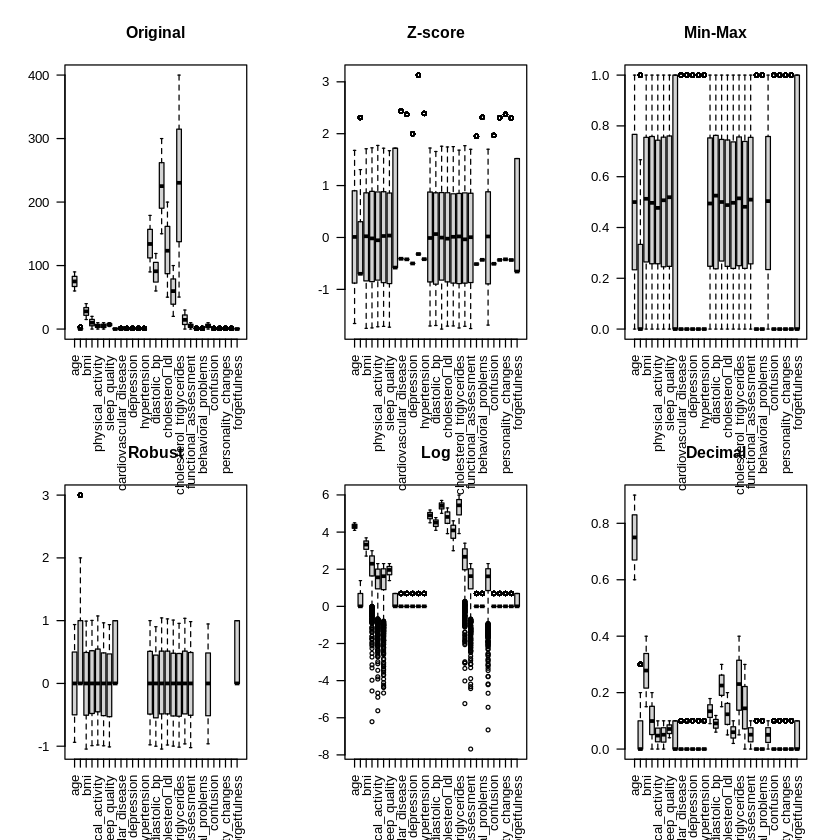

In [ ]:
par(mfrow=c(2,3))

boxplot(numeric_data,
        main="Original",
        las=2)

boxplot(zscore_data,
        main="Z-score",
        las=2)

boxplot(minmax_data,
        main="Min-Max",
        las=2)

boxplot(robust_data,
        main="Robust",
        las=2)

boxplot(log_data,
        main="Log",
        las=2)

boxplot(decimal_data,
        main="Decimal",
        las=2)

par(mfrow=c(1,1))


# Bivariate Analysis & PCA

In [ ]:
library(factoextra)

Welcome to factoextra!

Want to learn more? See two factoextra-related books at https://www.datanovia.com/library/principal-component-methods



Splits data into numeric vs categorical subsets

In [ ]:
numeric_data <- df %>%
  select(where(is.numeric))

categorical_data <- df %>%
  select(where(is.factor))

cat("Numeric Variables:\n")
print(names(numeric_data))

cat("\nCategorical Variables:\n")
print(names(categorical_data))

Numeric Variables:
 [1] "age"                         "ethnicity"                  
 [3] "bmi"                         "alcohol_consumption"        
 [5] "physical_activity"           "diet_quality"               
 [7] "sleep_quality"               "family_history_alzheimers"  
 [9] "cardiovascular_disease"      "diabetes"                   
[11] "depression"                  "head_injury"                
[13] "hypertension"                "systolic_bp"                
[15] "diastolic_bp"                "cholesterol_total"          
[17] "cholesterol_ldl"             "cholesterol_hdl"            
[19] "cholesterol_triglycerides"   "mmse"                       
[21] "functional_assessment"       "memory_complaints"          
[23] "behavioral_problems"         "adl"                        
[25] "confusion"                   "disorientation"             
[27] "personality_changes"         "difficulty_completing_tasks"
[29] "forgetfulness"              

Categorical Variables:
[1] "patient

**Numeric-vs-numeric: correlation matrix + scatter plot with regression line**


NUMERIC vs NUMERIC
                               age ethnicity    bmi alcohol_consumption
age                          1.000     0.028 -0.016               0.007
ethnicity                    0.028     1.000 -0.003               0.008
bmi                         -0.016    -0.003  1.000              -0.009
alcohol_consumption          0.007     0.008 -0.009               1.000
physical_activity           -0.010     0.020  0.001               0.022
diet_quality                -0.023    -0.018  0.020               0.020
sleep_quality                0.049     0.029 -0.006              -0.004
family_history_alzheimers   -0.019     0.023  0.006              -0.004
cardiovascular_disease      -0.015     0.002 -0.005              -0.024
diabetes                    -0.006    -0.020 -0.009               0.000
depression                  -0.009    -0.005 -0.013               0.009
head_injury                 -0.040    -0.009  0.016              -0.008
hypertension                 0.004     0.013

`geom_smooth()` using formula = 'y ~ x'


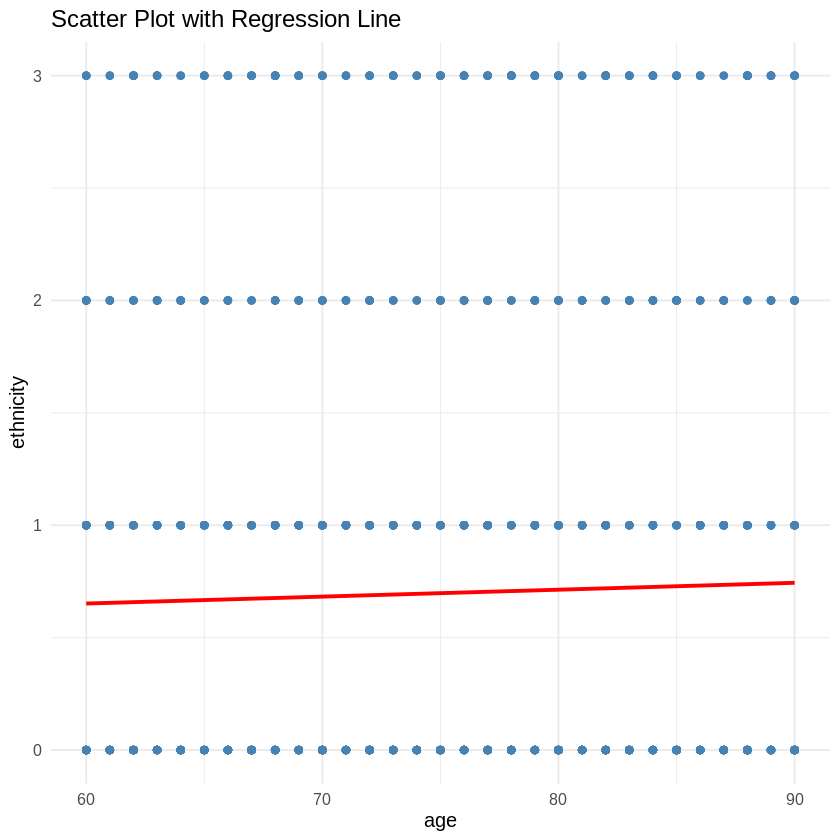

In [ ]:
cat("\n==============================\n")
cat("NUMERIC vs NUMERIC\n")
cat("==============================\n")

# Pearson Correlation
correlation_matrix <- cor(
  numeric_data,
  use = "complete.obs",
  method = "pearson"
)

print(round(correlation_matrix,3))

# Scatter Plot of First Two Numeric Variables
if(ncol(numeric_data) >= 2){

ggplot(df,
       aes(x = .data[[names(numeric_data)[1]]],
           y = .data[[names(numeric_data)[2]]])) +

  geom_point(color="steelblue") +

  geom_smooth(method="lm",
              color="red",
              se=FALSE) +

  labs(
    title="Scatter Plot with Regression Line",
    x=names(numeric_data)[1],
    y=names(numeric_data)[2]
  )

}


**Categorical-vs-categorical: cross-tab + stacked bar chart**


CATEGORICAL vs CATEGORICAL
      
       Male Female
  4751    1      0
  4752    1      0
  4753    1      0
  4754    0      1
  4755    1      0
  4756    0      1
  4757    1      0
  4758    1      0
  4759    0      1
  4760    1      0
  4761    1      0
  4762    1      0
  4763    0      1
  4764    0      1
  4765    0      1
  4766    1      0
  4767    0      1
  4768    0      1
  4769    1      0
  4770    1      0
  4771    0      1
  4772    1      0
  4773    0      1
  4774    0      1
  4775    0      1
  4776    1      0
  4777    0      1
  4778    1      0
  4779    1      0
  4780    1      0
  4781    0      1
  4782    1      0
  4783    0      1
  4784    1      0
  4785    0      1
  4786    1      0
  4787    1      0
  4788    0      1
  4789    1      0
  4790    0      1
  4791    0      1
  4792    0      1
  4793    0      1
  4794    1      0
  4795    1      0
  4796    0      1
  4797    1      0
  4798    0      1
  4799    1      0
  4800    0    

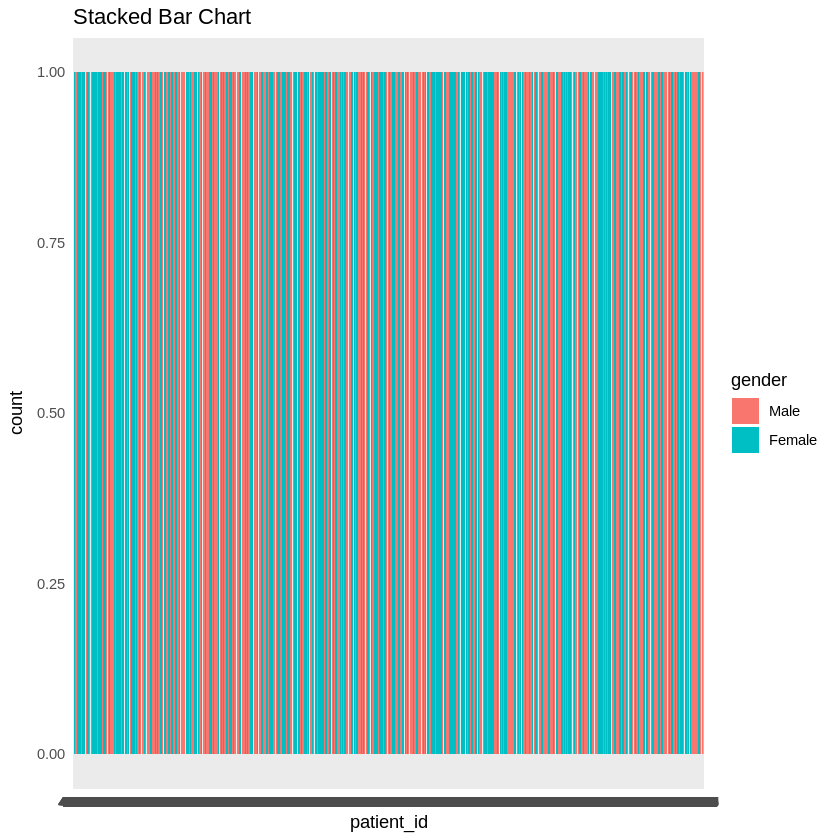

In [ ]:
cat("\n==============================\n")
cat("CATEGORICAL vs CATEGORICAL\n")
cat("==============================\n")

if(ncol(categorical_data)>=2){

cat1 <- names(categorical_data)[1]

cat2 <- names(categorical_data)[2]

cross_tab <- table(df[[cat1]],
                   df[[cat2]])

print(cross_tab)

# Stacked Bar Chart

ggplot(df,
       aes(x=.data[[cat1]],
           fill=.data[[cat2]]))+

geom_bar()+

theme_minimal()+

labs(title="Stacked Bar Chart")

}

PCA via prcomp(), variance-explained table

In [ ]:
cat("\n==============================\n")
cat("PCA\n")
cat("==============================\n")

# Standardize Numeric Variables
pca_model <- prcomp(
numeric_data,
scale.=TRUE
)

# Summary
summary(pca_model)

# Explained Variance
variance <- pca_model$sdev^2

variance_ratio <- variance/sum(variance)

variance_table <- data.frame(

Principal_Component=
paste0("PC",1:length(variance_ratio)),

Variance_Explained=
round(variance_ratio*100,2),

Cumulative=
round(cumsum(variance_ratio)*100,2)

)

print(variance_table)


PCA


Importance of components:
                           PC1     PC2     PC3     PC4     PC5    PC6     PC7
Standard deviation     1.09239 1.08528 1.07943 1.06878 1.06149 1.0512 1.04909
Proportion of Variance 0.04115 0.04061 0.04018 0.03939 0.03885 0.0381 0.03795
Cumulative Proportion  0.04115 0.08176 0.12194 0.16133 0.20019 0.2383 0.27624
                           PC8     PC9    PC10    PC11    PC12    PC13    PC14
Standard deviation     1.04039 1.03735 1.03523 1.02046 1.01777 1.00717 1.00379
Proportion of Variance 0.03732 0.03711 0.03696 0.03591 0.03572 0.03498 0.03474
Cumulative Proportion  0.31357 0.35067 0.38763 0.42354 0.45926 0.49423 0.52898
                          PC15    PC16    PC17    PC18    PC19    PC20   PC21
Standard deviation     0.99410 0.98517 0.98231 0.97707 0.97573 0.97301 0.9708
Proportion of Variance 0.03408 0.03347 0.03327 0.03292 0.03283 0.03265 0.0325
Cumulative Proportion  0.56306 0.59652 0.62980 0.66272 0.69555 0.72819 0.7607
                          PC22    

   Principal_Component Variance_Explained Cumulative
1                  PC1               4.11       4.11
2                  PC2               4.06       8.18
3                  PC3               4.02      12.19
4                  PC4               3.94      16.13
5                  PC5               3.89      20.02
6                  PC6               3.81      23.83
7                  PC7               3.80      27.62
8                  PC8               3.73      31.36
9                  PC9               3.71      35.07
10                PC10               3.70      38.76
11                PC11               3.59      42.35
12                PC12               3.57      45.93
13                PC13               3.50      49.42
14                PC14               3.47      52.90
15                PC15               3.41      56.31
16                PC16               3.35      59.65
17                PC17               3.33      62.98
18                PC18               3.29     

Scree plot (fviz_eig), individual PCA plot colored by category, variable contribution plot, and biplot

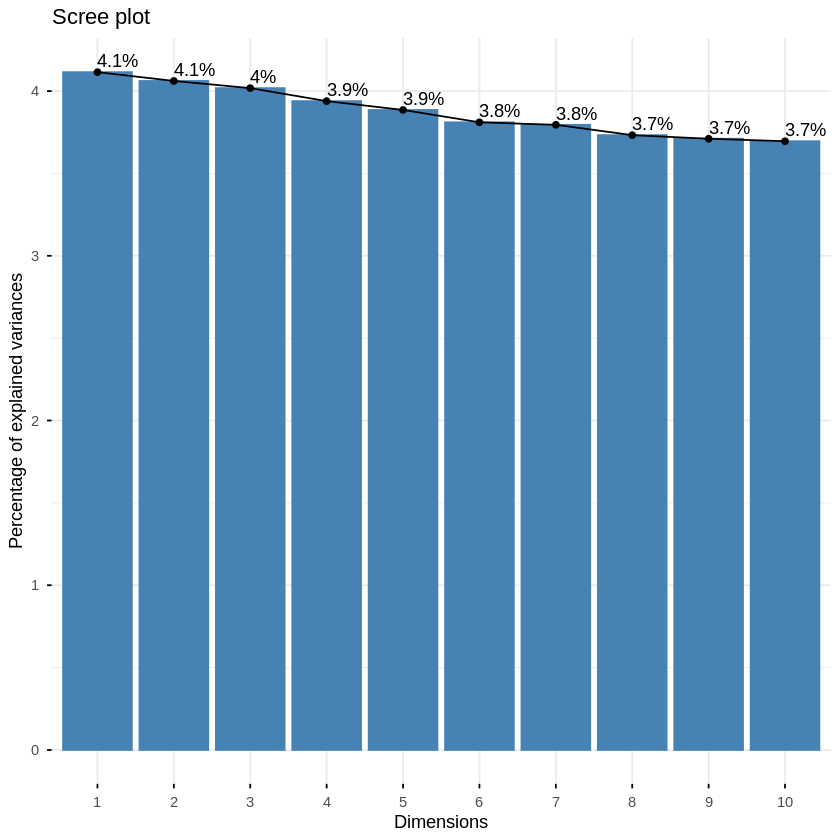

In [ ]:
fviz_eig(
pca_model,
addlabels=TRUE,
barfill="steelblue"
)

# Feature Engineering

In [ ]:
library(lubridate)
feature_df <- df

Interaction feature (product of first two numeric columns)

In [ ]:
numeric_cols <- names(feature_df)[sapply(feature_df, is.numeric)]

if(length(numeric_cols) >= 2){

  feature_df$Interaction_Feature <-
    feature_df[[numeric_cols[1]]] *
    feature_df[[numeric_cols[2]]]

  cat("Interaction feature created using:",
      numeric_cols[1], "and", numeric_cols[2], "\n")

}


Interaction feature created using: age and ethnicity 


**Ratio feature**

In [ ]:
if(length(numeric_cols) >= 2){

  feature_df$Ratio_Feature <-
    feature_df[[numeric_cols[1]]] /
    (feature_df[[numeric_cols[2]]] + 1)

  cat("Ratio feature created.\n")

}

Ratio feature created.


Binned feature (4 bins: Low/Medium/High/Very High)

In [ ]:
if(length(numeric_cols) >= 1){

feature_df$Binned_Feature <-
cut(
feature_df[[numeric_cols[1]]],

breaks=4,

labels=c("Low",
         "Medium",
         "High",
         "Very High"),

include.lowest=TRUE
)

cat("Binned feature created.\n")

}

Binned feature created.


Polynomial (squared) feature

In [ ]:
if(length(numeric_cols) >= 1){

feature_df$Polynomial_Feature <-
feature_df[[numeric_cols[1]]]^2

cat("Polynomial feature created.\n")

}

Polynomial feature created.


Date decomposition (Year/Month/Weekday)

In [ ]:
date_cols <- names(feature_df)[
sapply(feature_df,function(x)
inherits(x,"Date") |
inherits(x,"POSIXct") |
inherits(x,"POSIXlt"))
]

if(length(date_cols)>0){

feature_df$Year <-
year(feature_df[[date_cols[1]]])

feature_df$Month <-
month(feature_df[[date_cols[1]]])

feature_df$Weekday <-
weekdays(feature_df[[date_cols[1]]])

cat("Date decomposition completed.\n")

}else{

cat("No Date variable found. Skipping date decomposition.\n")

}

No Date variable found. Skipping date decomposition.


PCA-derived features (PC1, PC2) added to the feature set

In [ ]:
numeric_data <- feature_df %>%
select(where(is.numeric))

pca_model <- prcomp(
numeric_data,
scale.=TRUE
)

feature_df$PC1 <- pca_model$x[,1]
feature_df$PC2 <- pca_model$x[,2]

cat("PCA Components (PC1 & PC2) created.\n")


PCA Components (PC1 & PC2) created.


**Lists all newly created feature names**

In [ ]:
variance <- pca_model$sdev^2

variance_ratio <- variance/sum(variance)

variance_table <- data.frame(

Component=paste0("PC",1:length(variance_ratio)),

Variance_Explained=
round(variance_ratio*100,2),

Cumulative=
round(cumsum(variance_ratio)*100,2)

)

print(variance_table)


   Component Variance_Explained Cumulative
1        PC1               8.97       8.97
2        PC2               6.53      15.49
3        PC3               3.71      19.20
4        PC4               3.68      22.88
5        PC5               3.64      26.52
6        PC6               3.57      30.09
7        PC7               3.45      33.54
8        PC8               3.43      36.98
9        PC9               3.42      40.40
10      PC10               3.35      43.75
11      PC11               3.29      47.03
12      PC12               3.26      50.30
13      PC13               3.25      53.55
14      PC14               3.17      56.72
15      PC15               3.11      59.83
16      PC16               3.10      62.92
17      PC17               3.08      66.00
18      PC18               2.99      69.00
19      PC19               2.98      71.98
20      PC20               2.97      74.95
21      PC21               2.96      77.91
22      PC22               2.91      80.82
23      PC2

In [ ]:
cat("\n=====================================\n")
cat("NEW FEATURES CREATED\n")
cat("=====================================\n")

new_features <- setdiff(names(feature_df), names(df))

print(new_features)


NEW FEATURES CREATED
[1] "Interaction_Feature" "Ratio_Feature"       "Binned_Feature"     
[4] "Polynomial_Feature"  "PC1"                 "PC2"                


# Missing Value Handling

In [ ]:
library(VIM)
library(mice)

missing_df <- df

Missing value summary table

In [ ]:
cat("=========================================\n")
cat("MISSING VALUE SUMMARY\n")
cat("=========================================\n")

missing_summary <- data.frame(

Variable = names(missing_df),

Missing_Count = sapply(missing_df,
function(x) sum(is.na(x))),

Missing_Percent = round(
sapply(missing_df,
function(x) mean(is.na(x))*100),2)

)

print(missing_summary)

MISSING VALUE SUMMARY
                                               Variable Missing_Count
patient_id                                   patient_id             0
age                                                 age             0
gender                                           gender             0
ethnicity                                     ethnicity             0
education_level                         education_level             0
bmi                                                 bmi             0
smoking                                         smoking             0
alcohol_consumption                 alcohol_consumption             0
physical_activity                     physical_activity             0
diet_quality                               diet_quality             0
sleep_quality                             sleep_quality             0
family_history_alzheimers     family_history_alzheimers             0
cardiovascular_disease           cardiovascular_disease             

Drops columns with >40% missingness

In [ ]:
threshold <- 40

remove_cols <- names(missing_df)[

missing_summary$Missing_Percent > threshold

]

if(length(remove_cols)>0){

missing_df <- missing_df %>%
select(-all_of(remove_cols))

cat("\nRemoved Columns (>40% Missing):\n")

print(remove_cols)

}else{

cat("\nNo columns removed.\n")

}


No columns removed.


Drops rows missing the target (conditional on a "Diagnosis" column — again case-mismatch, likely a no-op)

In [ ]:
if("Diagnosis" %in% names(missing_df)){

before_rows <- nrow(missing_df)

missing_df <- missing_df %>%
filter(!is.na(Diagnosis))

after_rows <- nrow(missing_df)

cat("\nRows removed (Missing Diagnosis):",
before_rows-after_rows,"\n")

}

In [ ]:
numeric_cols <- names(missing_df)[
sapply(missing_df,is.numeric)]

factor_cols <- names(missing_df)[
sapply(missing_df,is.factor)]


Mean imputation, median imputation, mode imputation (for factors)

In [ ]:
mean_data <- missing_df

for(col in numeric_cols){

mean_data[[col]][is.na(mean_data[[col]])] <-

mean(mean_data[[col]],na.rm=TRUE)

}

In [ ]:
median_data <- missing_df

for(col in numeric_cols){

median_data[[col]][is.na(median_data[[col]])] <-

median(median_data[[col]],na.rm=TRUE)

}

In [ ]:
mode_function <- function(x){

ux <- unique(x)

ux[which.max(tabulate(match(x,ux)))]

}

mode_data <- median_data

for(col in factor_cols){

mode_value <- mode_function(mode_data[[col]])

mode_data[[col]][is.na(mode_data[[col]])] <- mode_value

}

KNN imputation (VIM::kNN)

In [ ]:
knn_data <- kNN(

missing_df,

k=5,

imp_var=FALSE

)

Warning message in kNN(missing_df, k = 5, imp_var = FALSE):
“Nothing to impute, because no NA are present (also after using makeNA)”


MICE (multiple imputation via PMM)

In [ ]:
mice_model <- mice(

missing_df,

m=5,

method="pmm",

seed=123,

printFlag=FALSE

)

mice_data <- complete(mice_model)

Listwise deletion (na.omit)

In [ ]:
listwise_data <- na.omit(missing_df)

Comparison table of row counts/remaining missing values across all methods

In [ ]:
result_table <- data.frame(

Method=c(
"Original",
"Mean",
"Median",
"Mode",
"KNN",
"MICE",
"Listwise"),

Rows=c(

nrow(missing_df),

nrow(mean_data),

nrow(median_data),

nrow(mode_data),

nrow(knn_data),

nrow(mice_data),

nrow(listwise_data)

),

Missing_Values=c(

sum(is.na(missing_df)),

sum(is.na(mean_data)),

sum(is.na(median_data)),

sum(is.na(mode_data)),

sum(is.na(knn_data)),

sum(is.na(mice_data)),

sum(is.na(listwise_data))

)

)

cat("\n=========================================\n")
cat("IMPUTATION COMPARISON\n")
cat("=========================================\n")

print(result_table)


IMPUTATION COMPARISON
    Method Rows Missing_Values
1 Original 2149              0
2     Mean 2149              0
3   Median 2149              0
4     Mode 2149              0
5      KNN 2149              0
6     MICE 2149              0
7 Listwise 2149              0


# Train/Validation/Test Split & Scaling

In [ ]:
library(caret)
set.seed(123)

70/15/15 split via createDataPartition on diagnosis

In [ ]:
target <- "diagnosis"

if(!(target %in% names(df))){
  stop("Target variable 'Diagnosis' not found.")
}

In [ ]:
train_index <- createDataPartition(
  df[[target]],
  p = 0.70,
  list = FALSE
)

train_data <- df[train_index, ]
temp_data  <- df[-train_index, ]

In [ ]:
valid_index <- createDataPartition(
  temp_data[[target]],
  p = 0.50,
  list = FALSE
)

validation_data <- temp_data[valid_index, ]
test_data       <- temp_data[-valid_index, ]


Split size and percentage table

In [ ]:
cat("=====================================\n")
cat("DATASET SPLIT\n")
cat("=====================================\n")

split_table <- data.frame(

Dataset = c(
"Training",
"Validation",
"Testing"),

Rows = c(
nrow(train_data),
nrow(validation_data),
nrow(test_data)
),

Percentage = round(c(

nrow(train_data),

nrow(validation_data),

nrow(test_data)

)/nrow(df)*100,2)

)

print(split_table)

DATASET SPLIT
     Dataset Rows Percentage
1   Training 1505      70.03
2 Validation  322      14.98
3    Testing  322      14.98


Class distribution check across the three sets

In [ ]:
cat("\n=====================================\n")
cat("CLASS DISTRIBUTION\n")
cat("=====================================\n")

cat("\nTraining Set\n")
print(prop.table(table(train_data[[target]])))

cat("\nValidation Set\n")
print(prop.table(table(validation_data[[target]])))

cat("\nTest Set\n")
print(prop.table(table(test_data[[target]])))


CLASS DISTRIBUTION

Training Set

No Alzheimer's    Alzheimer's 
     0.6465116      0.3534884 

Validation Set

No Alzheimer's    Alzheimer's 
     0.6459627      0.3540373 

Test Set

No Alzheimer's    Alzheimer's 
     0.6459627      0.3540373 


Centers/scales numeric columns using preProcess

In [ ]:
numeric_cols <- names(train_data)[
sapply(train_data,is.numeric)
]

preprocess_model <- preProcess(

train_data[,numeric_cols],

method=c("center","scale")

)

train_scaled <- train_data
validation_scaled <- validation_data
test_scaled <- test_data

train_scaled[,numeric_cols] <-
predict(
preprocess_model,
train_data[,numeric_cols]
)

validation_scaled[,numeric_cols] <-
predict(
preprocess_model,
validation_data[,numeric_cols]
)

test_scaled[,numeric_cols] <-
predict(
preprocess_model,
test_data[,numeric_cols]
)


Summary of scaled training data

In [ ]:
cat("\n=====================================\n")
cat("SCALED TRAINING DATA SUMMARY\n")
cat("=====================================\n")

summary(train_scaled[,numeric_cols])



SCALED TRAINING DATA SUMMARY


      age             ethnicity            bmi           alcohol_consumption
 Min.   :-1.68272   Min.   :-0.7094   Min.   :-1.73732   Min.   :-1.72463   
 1st Qu.:-0.90308   1st Qu.:-0.7094   1st Qu.:-0.83872   1st Qu.:-0.86157   
 Median :-0.01206   Median :-0.7094   Median : 0.03174   Median :-0.03492   
 Mean   : 0.00000   Mean   : 0.0000   Mean   : 0.00000   Mean   : 0.00000   
 3rd Qu.: 0.87895   3rd Qu.: 0.2940   3rd Qu.: 0.86479   3rd Qu.: 0.90599   
 Max.   : 1.65859   Max.   : 2.3009   Max.   : 1.71717   Max.   : 1.73071   
 physical_activity   diet_quality       sleep_quality     
 Min.   :-1.72967   Min.   :-1.694375   Min.   :-1.75242  
 1st Qu.:-0.83232   1st Qu.:-0.871677   1st Qu.:-0.87181  
 Median :-0.01582   Median : 0.009014   Median : 0.03507  
 Mean   : 0.00000   Mean   : 0.000000   Mean   : 0.00000  
 3rd Qu.: 0.89485   3rd Qu.: 0.870963   3rd Qu.: 0.84832  
 Max.   : 1.75162   Max.   : 1.718625   Max.   : 1.67237  
 family_history_alzheimers cardiovascular_diseas

Saves alz_train.csv, alz_validation.csv, alz_test.csv

In [ ]:
write.csv(
train_scaled,
"alz_train.csv",
row.names=FALSE
)

write.csv(
validation_scaled,
"alz_validation.csv",
row.names=FALSE
)

write.csv(
test_scaled,
"alz_test.csv",
row.names=FALSE
)

cat("\nDatasets Saved Successfully:\n")
cat(" - alz_train.csv\n")
cat(" - alz_validation.csv\n")
cat(" - alz_test.csv\n")


Datasets Saved Successfully:
 - alz_train.csv
 - alz_validation.csv
 - alz_test.csv


# Regression & Classification Modeling

In [ ]:
pkgs <- c("rpart", "randomForest", "class", "caret")
for (p in pkgs) if (!requireNamespace(p, quietly = TRUE)) install.packages(p)
library(rpart)
library(randomForest)
library(class)
library(caret)

set.seed(42)
df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)

mmse is a regression target, diagnosis a classification target

In [ ]:
cat("Class of 'mmse'      :", class(df$mmse), "-> numeric target => REGRESSION\n")
cat("Class of 'diagnosis' :", class(df$diagnosis), "(0/1 coded) -> treat as factor => CLASSIFICATION\n")

df$diagnosis <- factor(df$diagnosis, labels = c("No", "Yes"))  # "Yes" = Alzheimer's


Class of 'mmse'      : numeric -> numeric target => REGRESSION
Class of 'diagnosis' : integer (0/1 coded) -> treat as factor => CLASSIFICATION


**Regression (predicting mmse): 70/30 split → Linear Regression and Random Forest, evaluated with MAE/MSE/RMSE/R²/Adjusted R²**

In [ ]:
predictors_reg <- c("age", "bmi", "functional_assessment", "adl",
                     "systolic_bp", "diastolic_bp", "cholesterol_total")

## ---- Train/test split (70/30) -----------------------------------------
train_idx <- createDataPartition(df$mmse, p = 0.7, list = FALSE)
train_reg <- df[train_idx, c("mmse", predictors_reg)]
test_reg  <- df[-train_idx, c("mmse", predictors_reg)]


In [ ]:
## ---- Linear regression (baseline) --------------------------------------
lm_model <- lm(mmse ~ ., data = train_reg)
lm_pred  <- predict(lm_model, newdata = test_reg)

In [ ]:
## ---- Random Forest regression -------------------------------------------
rf_reg_model <- randomForest(mmse ~ ., data = train_reg, ntree = 300)
rf_reg_pred  <- predict(rf_reg_model, newdata = test_reg)

In [ ]:
## ---- Regression evaluation metrics ---------------------------------------
regression_metrics <- function(actual, predicted, n_predictors) {
  mae  <- mean(abs(actual - predicted))
  mse  <- mean((actual - predicted)^2)
  rmse <- sqrt(mse)
  n <- length(actual)
  r2 <- 1 - sum((actual - predicted)^2) / sum((actual - mean(actual))^2)
  adj_r2 <- 1 - (1 - r2) * (n - 1) / (n - n_predictors - 1)
  data.frame(MAE = mae, MSE = mse, RMSE = rmse, R2 = r2, Adj_R2 = adj_r2)
}

cat("\n================ REGRESSION METRICS (predicting mmse) ================\n")
cat("-- Linear Regression --\n")
print(round(regression_metrics(test_reg$mmse, lm_pred, length(predictors_reg)), 4))
cat("-- Random Forest Regression --\n")
print(round(regression_metrics(test_reg$mmse, rf_reg_pred, length(predictors_reg)), 4))




================ REGRESSION METRICS (predicting mmse) ================
-- Linear Regression --
   MAE     MSE  RMSE    R2  Adj_R2
1 7.51 74.5108 8.632 5e-04 -0.0105
-- Random Forest Regression --
     MAE     MSE  RMSE      R2  Adj_R2
1 7.6636 78.2158 8.844 -0.0492 -0.0608


**Classification (predicting diagnosis): 70/30 split → Logistic Regression, Decision Tree (rpart), Random Forest, and KNN (k=5, scaled features)**

In [ ]:
predictors_clf <- c("age", "bmi", "mmse", "functional_assessment", "adl",
                     "systolic_bp", "diastolic_bp", "cholesterol_total",
                     "smoking", "gender")
df$smoking <- factor(df$smoking)
df$gender  <- factor(df$gender)


In [ ]:
## ---- Train/test split (70/30), stratified on the target ------------------
train_idx2 <- createDataPartition(df$diagnosis, p = 0.7, list = FALSE)
train_clf <- df[train_idx2, c("diagnosis", predictors_clf)]
test_clf  <- df[-train_idx2, c("diagnosis", predictors_clf)]


In [ ]:
## ---- 1. Logistic Regression (stats::glm) ----------------------------------
log_model <- glm(diagnosis ~ ., data = train_clf, family = binomial)
log_prob  <- predict(log_model, newdata = test_clf, type = "response")
log_pred  <- factor(ifelse(log_prob > 0.5, "Yes", "No"), levels = levels(df$diagnosis))


In [ ]:
## ---- 2. Decision Tree (CART, rpart) ---------------------------------------
tree_model <- rpart(diagnosis ~ ., data = train_clf, method = "class")
tree_pred  <- predict(tree_model, newdata = test_clf, type = "class")


In [ ]:
## ---- 3. Random Forest ------------------------------------------------------
rf_model <- randomForest(diagnosis ~ ., data = train_clf, ntree = 300)
rf_pred  <- predict(rf_model, newdata = test_clf)



In [ ]:
## ---- 4. K-Nearest Neighbors (class::knn) -----------------------------------
## KNN needs numeric-only, scaled predictors (distance-based algorithm)
num_predictors <- c("age", "bmi", "mmse", "functional_assessment", "adl",
                     "systolic_bp", "diastolic_bp", "cholesterol_total")
train_knn_x <- scale(train_clf[, num_predictors])
test_knn_x  <- scale(test_clf[, num_predictors],
                      center = attr(train_knn_x, "scaled:center"),
                      scale  = attr(train_knn_x, "scaled:scale"))
knn_pred <- knn(train = train_knn_x, test = test_knn_x,
                cl = train_clf$diagnosis, k = 5)


**Custom classification_metrics() function computing confusion matrix, accuracy, precision, recall, F1**

In [ ]:
## ---- Classification evaluation metrics -------------------------------------
## Positive class = "Yes" (Alzheimer's)
classification_metrics <- function(actual, predicted, positive = "Yes") {
  cm <- table(Predicted = predicted, Actual = actual)
  tp <- cm[positive, positive]
  fp <- sum(cm[positive, ]) - tp
  fn <- sum(cm[, positive]) - tp
  tn <- sum(cm) - tp - fp - fn

  accuracy  <- (tp + tn) / sum(cm)
  precision <- ifelse((tp + fp) == 0, NA, tp / (tp + fp))
  recall    <- ifelse((tp + fn) == 0, NA, tp / (tp + fn))
  f1        <- ifelse(is.na(precision) || is.na(recall) || (precision + recall) == 0,
                       NA, 2 * precision * recall / (precision + recall))

  list(confusion_matrix = cm,
       metrics = data.frame(Accuracy = accuracy, Precision = precision,
                             Recall = recall, F1_Score = f1))
}


In [ ]:
cat("\n================ CLASSIFICATION METRICS (predicting diagnosis) ================\n")

cat("\n-- Logistic Regression --\n")
res_log <- classification_metrics(test_clf$diagnosis, log_pred)
print(res_log$confusion_matrix)
print(round(res_log$metrics, 4))

cat("\n-- Decision Tree (CART) --\n")
res_tree <- classification_metrics(test_clf$diagnosis, tree_pred)
print(res_tree$confusion_matrix)
print(round(res_tree$metrics, 4))

cat("\n-- Random Forest --\n")
res_rf <- classification_metrics(test_clf$diagnosis, rf_pred)
print(res_rf$confusion_matrix)
print(round(res_rf$metrics, 4))

cat("\n-- K-Nearest Neighbors (k=5) --\n")
res_knn <- classification_metrics(test_clf$diagnosis, knn_pred)
print(res_knn$confusion_matrix)
print(round(res_knn$metrics, 4))



================ CLASSIFICATION METRICS (predicting diagnosis) ================

-- Logistic Regression --
         Actual
Predicted  No Yes
      No  354  78
      Yes  62 150
  Accuracy Precision Recall F1_Score
1   0.7826    0.7075 0.6579   0.6818

-- Decision Tree (CART) --
         Actual
Predicted  No Yes
      No  411  96
      Yes   5 132
  Accuracy Precision Recall F1_Score
1   0.8432    0.9635 0.5789   0.7233

-- Random Forest --
         Actual
Predicted  No Yes
      No  398  85
      Yes  18 143
  Accuracy Precision Recall F1_Score
1   0.8401    0.8882 0.6272   0.7352

-- K-Nearest Neighbors (k=5) --
         Actual
Predicted  No Yes
      No  359  86
      Yes  57 142
  Accuracy Precision Recall F1_Score
1    0.778    0.7136 0.6228   0.6651


Prints metrics for all four classifiers, then a combined comparison table

In [ ]:
## ---- Combined comparison table ---------------------------------------------
comparison <- rbind(
  cbind(Model = "Logistic Regression", res_log$metrics),
  cbind(Model = "Decision Tree",       res_tree$metrics),
  cbind(Model = "Random Forest",       res_rf$metrics),
  cbind(Model = "KNN (k=5)",           res_knn$metrics)
)
cat("\n================ MODEL COMPARISON — CLASSIFICATION ================\n")
print(comparison, row.names = FALSE)

## Alternative: caret::confusionMatrix() gives the same metrics plus more detail
## (Kappa, balanced accuracy, sensitivity/specificity) in one call:
## caret::confusionMatrix(rf_pred, test_clf$diagnosis, positive = "Yes")



================ MODEL COMPARISON — CLASSIFICATION ================
               Model  Accuracy Precision    Recall  F1_Score
 Logistic Regression 0.7826087 0.7075472 0.6578947 0.6818182
       Decision Tree 0.8431677 0.9635036 0.5789474 0.7232877
       Random Forest 0.8400621 0.8881988 0.6271930 0.7352185
           KNN (k=5) 0.7779503 0.7135678 0.6228070 0.6651054


# Model Tuning & Diagnostics (Final Section)

In [ ]:
pkgs <- c("rpart", "randomForest", "class", "caret", "e1071")
for (p in pkgs) if (!requireNamespace(p, quietly = TRUE)) install.packages(p)
library(rpart)
library(randomForest)
library(class)
library(caret)
library(e1071)

set.seed(42)
df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)
df$diagnosis <- factor(df$diagnosis, labels = c("No", "Yes"))
df$smoking   <- factor(df$smoking)
df$gender    <- factor(df$gender)

predictors_clf <- c("age", "bmi", "mmse", "functional_assessment", "adl",
                     "systolic_bp", "diastolic_bp", "cholesterol_total",
                     "smoking", "gender")
model_data <- df[, c("diagnosis", predictors_clf)]



Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element




Rebuilds a 60/20/20 train/val/test split

In [ ]:
idx_train <- createDataPartition(model_data$diagnosis, p = 0.6, list = FALSE)
train_set <- model_data[idx_train, ]
remaining <- model_data[-idx_train, ]

idx_val <- createDataPartition(remaining$diagnosis, p = 0.5, list = FALSE)
val_set  <- remaining[idx_val, ]
test_set <- remaining[-idx_val, ]

cat("Split sizes -> train:", nrow(train_set), " validation:", nrow(val_set),
    " test:", nrow(test_set), "\n")


Split sizes -> train: 1290  validation: 430  test: 429 


Random Forest baseline, with a train/val/test accuracy table and automatic overfitting/underfitting interpretation logic

In [ ]:
rf_model <- randomForest(diagnosis ~ ., data = train_set, ntree = 300)

get_accuracy <- function(model, data) {
  pred <- predict(model, newdata = data)
  mean(pred == data$diagnosis)
}

acc_table <- data.frame(
  Set      = c("Train", "Validation", "Test"),
  Accuracy = c(get_accuracy(rf_model, train_set),
               get_accuracy(rf_model, val_set),
               get_accuracy(rf_model, test_set))
)
acc_table$Accuracy <- round(acc_table$Accuracy, 4)

cat("\n================ TRAIN / VALIDATION / TEST COMPARISON TABLE ================\n")
print(acc_table, row.names = FALSE)



================ TRAIN / VALIDATION / TEST COMPARISON TABLE ================
        Set Accuracy
      Train   1.0000
 Validation   0.8070
       Test   0.8182


In [ ]:
train_acc <- acc_table$Accuracy[acc_table$Set == "Train"]
val_acc   <- acc_table$Accuracy[acc_table$Set == "Validation"]
test_acc  <- acc_table$Accuracy[acc_table$Set == "Test"]
gap_train_val <- train_acc - val_acc

cat("\n--- Interpretation ---\n")
if (gap_train_val > 0.10) {
  cat(sprintf("Train (%.3f) >> Validation (%.3f): gap = %.3f -> signs of OVERFITTING.\n",
              train_acc, val_acc, gap_train_val))
} else if (train_acc < 0.65 && val_acc < 0.65 && test_acc < 0.65) {
  cat("All three sets show similarly weak performance -> signs of UNDERFITTING ",
      "(model too simple, or features insufficient).\n")
} else {
  cat(sprintf("Train (%.3f), Validation (%.3f), Test (%.3f) are close and reasonably ",
              train_acc, val_acc, test_acc),
      "strong -> good generalization.\n")
}



--- Interpretation ---
Train (1.000) >> Validation (0.807): gap = 0.193 -> signs of OVERFITTING.


**Hyperparameter tuning demos**: **grid search** for RF mtry via caret::train, **manual grid search** for KNN k, and e1071::tune for **SVM cost/gamma**

In [ ]:
ctrl <- trainControl(method = "cv", number = 5)
rf_grid <- expand.grid(mtry = c(2, 3, 4, 5, 6))

rf_tuned <- train(diagnosis ~ ., data = train_set, method = "rf",
                   trControl = ctrl, tuneGrid = rf_grid, ntree = 200)

cat("\n================ 1. GRID SEARCH — caret::train (Random Forest mtry) ================\n")
print(rf_tuned)
cat("Best mtry:", rf_tuned$bestTune$mtry, "\n")



================ 1. GRID SEARCH — caret::train (Random Forest mtry) ================
Random Forest 

1290 samples
  10 predictor
   2 classes: 'No', 'Yes' 

No pre-processing
Resampling: Cross-Validated (5 fold) 
Summary of sample sizes: 1032, 1032, 1033, 1032, 1031 
Resampling results across tuning parameters:

  mtry  Accuracy   Kappa    
  2     0.8403243  0.6220864
  3     0.8348949  0.6119202
  4     0.8356731  0.6143382
  5     0.8395551  0.6240719
  6     0.8372295  0.6200508

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was mtry = 2.
Best mtry: 2 


In [ ]:
num_predictors <- c("age", "bmi", "mmse", "functional_assessment", "adl",
                     "systolic_bp", "diastolic_bp", "cholesterol_total")

train_x <- scale(train_set[, num_predictors])
val_x   <- scale(val_set[, num_predictors],
                  center = attr(train_x, "scaled:center"),
                  scale  = attr(train_x, "scaled:scale"))

k_candidates <- c(3, 5, 7, 9, 11, 15, 21)
manual_results <- data.frame(k = k_candidates, val_accuracy = NA)

for (i in seq_along(k_candidates)) {
  pred_k <- knn(train = train_x, test = val_x, cl = train_set$diagnosis, k = k_candidates[i])
  manual_results$val_accuracy[i] <- mean(pred_k == val_set$diagnosis)
}
manual_results$val_accuracy <- round(manual_results$val_accuracy, 4)

cat("\n================ 2. MANUAL SEARCH — KNN k, evaluated on validation set ================\n")
print(manual_results, row.names = FALSE)
best_k <- manual_results$k[which.max(manual_results$val_accuracy)]
cat("Best k:", best_k, "\n")


================ 2. MANUAL SEARCH — KNN k, evaluated on validation set ================
  k val_accuracy
  3       0.7442
  5       0.7605
  7       0.7535
  9       0.7605
 11       0.7512
 15       0.7837
 21       0.8023
Best k: 21 


In [ ]:
cat("\n================ 3. BUILT-IN TUNING HELPER — e1071::tune (SVM cost/gamma) ================\n")
svm_tune <- tune(svm, diagnosis ~ ., data = train_set,
                  kernel = "radial",
                  ranges = list(cost = c(0.1, 1, 10), gamma = c(0.01, 0.1, 1)),
                  tunecontrol = tune.control(cross = 5))

print(summary(svm_tune))
cat("Best parameters:\n")
print(svm_tune$best.parameters)



================ 3. BUILT-IN TUNING HELPER — e1071::tune (SVM cost/gamma) ================

Parameter tuning of ‘svm’:

- sampling method: 5-fold cross validation 

- best parameters:
 cost gamma
    1   0.1

- best performance: 0.1930233 

- Detailed performance results:
  cost gamma     error dispersion
1  0.1  0.01 0.3480620 0.03492676
2  1.0  0.01 0.2108527 0.02623089
3 10.0  0.01 0.1992248 0.02286493
4  0.1  0.10 0.2093023 0.01878946
5  1.0  0.10 0.1930233 0.02182277
6 10.0  0.10 0.2224806 0.01182012
7  0.1  1.00 0.3534884 0.02732489
8  1.0  1.00 0.3186047 0.03117686
9 10.0  1.00 0.2937984 0.02332032

Best parameters:
  cost gamma
5    1   0.1


**Decision Tree: ROC/AUC curve, precision-recall curve, train/val/test accuracy table with interpretation**

In [ ]:
pkgs <- c("rpart", "rpart.plot", "pROC", "caret", "glmnet", "ggplot2", "reshape2")
for (p in pkgs) if (!requireNamespace(p, quietly = TRUE)) install.packages(p)
library(rpart)
has_rpart_plot <- requireNamespace("rpart.plot", quietly = TRUE)
if (has_rpart_plot) library(rpart.plot)
library(pROC)
library(caret)
library(glmnet)
library(ggplot2)
library(reshape2)

set.seed(42)
df <- read.csv("alz_clean.csv", stringsAsFactors = FALSE)
df$diagnosis <- factor(df$diagnosis, labels = c("No", "Yes"))
df$smoking   <- factor(df$smoking)
df$gender    <- factor(df$gender)

predictors_clf <- c("age", "bmi", "mmse", "functional_assessment", "adl",
                     "systolic_bp", "diastolic_bp", "cholesterol_total",
                     "smoking", "gender")
model_data <- df[, c("diagnosis", predictors_clf)]


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘RcppEigen’


Loading required package: Matrix

Loaded glmnet 5.0




================ DECISION TREE — AUC ================
AUC: 0.8293 


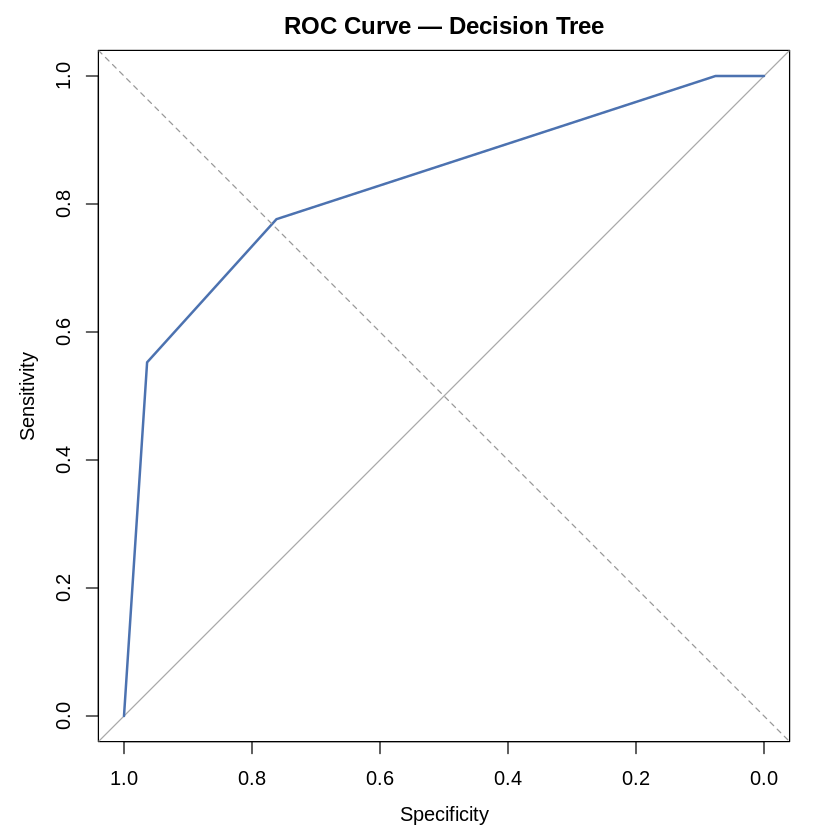

In [ ]:
## ---- Baseline fit (default cp) ------------------------------------------
tree_model <- rpart(diagnosis ~ ., data = train_set, method = "class")

## ---- ROC / AUC ------------------------------------------------------------
tree_prob_test <- predict(tree_model, newdata = test_set, type = "prob")[, "Yes"]
roc_tree <- roc(test_set$diagnosis, tree_prob_test, levels = c("No", "Yes"), direction = "<")
cat("\n================ DECISION TREE — AUC ================\n")
cat("AUC:", round(auc(roc_tree), 4), "\n")
plot(roc_tree, col = "#4C72B0", main = "ROC Curve — Decision Tree", lwd = 2)
abline(a = 0, b = 1, lty = 2, col = "grey60")


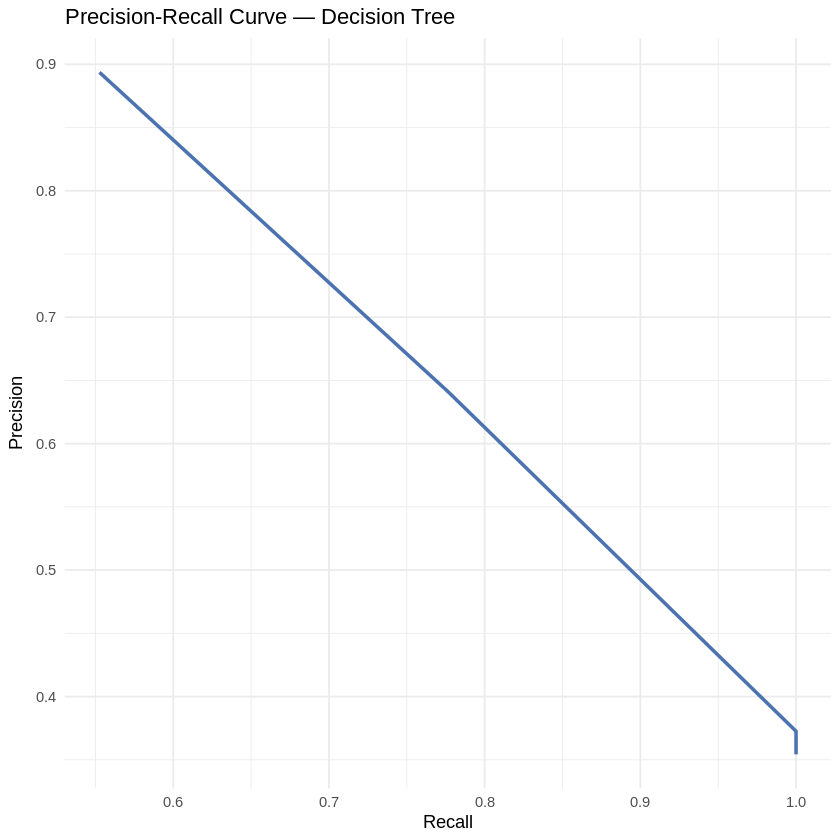

In [ ]:
## ---- Precision-Recall curve -----------------------------------------------
pr_curve_data <- function(actual, prob, positive = "Yes") {
  thresholds <- sort(unique(prob), decreasing = TRUE)
  out <- data.frame(threshold = thresholds, precision = NA, recall = NA)
  for (i in seq_along(thresholds)) {
    pred <- ifelse(prob >= thresholds[i], positive, setdiff(levels(actual), positive))
    tp <- sum(pred == positive & actual == positive)
    fp <- sum(pred == positive & actual != positive)
    fn <- sum(pred != positive & actual == positive)
    out$precision[i] <- ifelse((tp + fp) == 0, 1, tp / (tp + fp))
    out$recall[i]    <- ifelse((tp + fn) == 0, 0, tp / (tp + fn))
  }
  out
}
pr_tree <- pr_curve_data(test_set$diagnosis, tree_prob_test)
ggplot(pr_tree, aes(x = recall, y = precision)) +
  geom_line(color = "#4C72B0", linewidth = 1) +
  labs(title = "Precision-Recall Curve — Decision Tree", x = "Recall", y = "Precision") +
  theme_minimal()


In [ ]:

## ---- Train / Validation / Test comparison table ----------------------------
get_acc <- function(model, data) mean(predict(model, newdata = data, type = "class") == data$diagnosis)
tree_acc_table <- data.frame(
  Set = c("Train", "Validation", "Test"),
  Accuracy = round(c(get_acc(tree_model, train_set),
                      get_acc(tree_model, val_set),
                      get_acc(tree_model, test_set)), 4)
)
cat("\n================ DECISION TREE — TRAIN/VAL/TEST ================\n")
print(tree_acc_table, row.names = FALSE)

gap <- tree_acc_table$Accuracy[1] - tree_acc_table$Accuracy[2]
cat(if (gap > 0.10) {
  sprintf("Gap (train-val) = %.3f -> signs of OVERFITTING.\n", gap)
} else if (all(tree_acc_table$Accuracy < 0.65)) {
  "All three sets weak -> signs of UNDERFITTING.\n"
} else {
  "Train/Val/Test are close -> good generalization.\n"
})



================ DECISION TREE — TRAIN/VAL/TEST ================
        Set Accuracy
      Train   0.8465
 Validation   0.8279
       Test   0.8182
Train/Val/Test are close -> good generalization.


Logistic Regression: same ROC/AUC, precision-recall, and train/val/test evaluation


================ LOGISTIC REGRESSION — AUC ================
AUC: 0.8052 


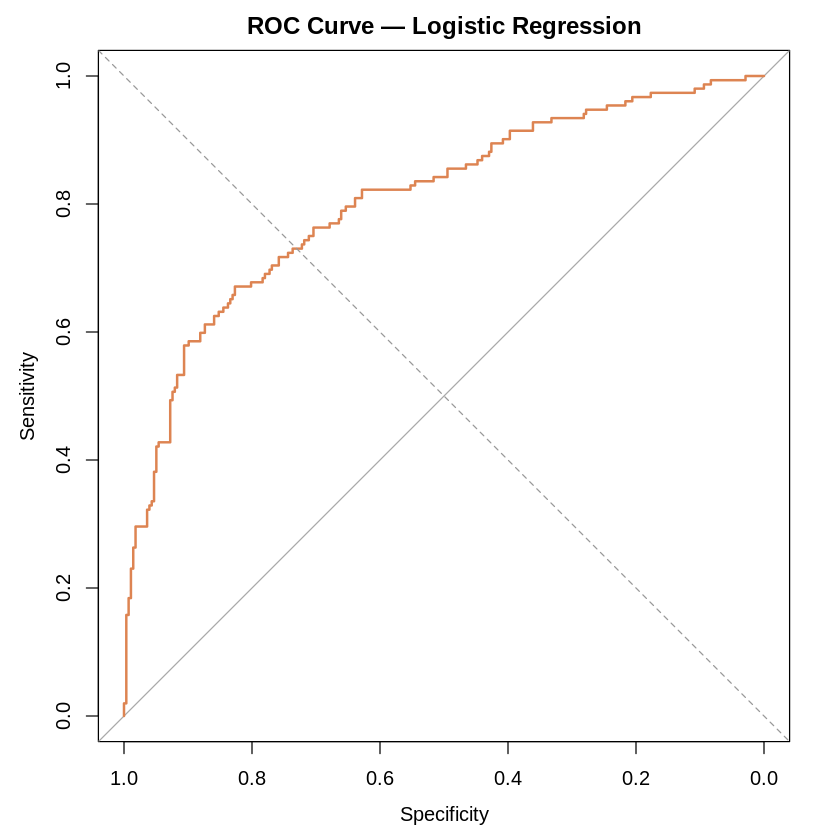

In [ ]:
log_model <- glm(diagnosis ~ ., data = train_set, family = binomial)

## ---- ROC / AUC --------------------------------------------------------------
log_prob_test <- predict(log_model, newdata = test_set, type = "response")
roc_log <- roc(test_set$diagnosis, log_prob_test, levels = c("No", "Yes"), direction = "<")
cat("\n================ LOGISTIC REGRESSION — AUC ================\n")
cat("AUC:", round(auc(roc_log), 4), "\n")
plot(roc_log, col = "#DD8452", main = "ROC Curve — Logistic Regression", lwd = 2)
abline(a = 0, b = 1, lty = 2, col = "grey60")


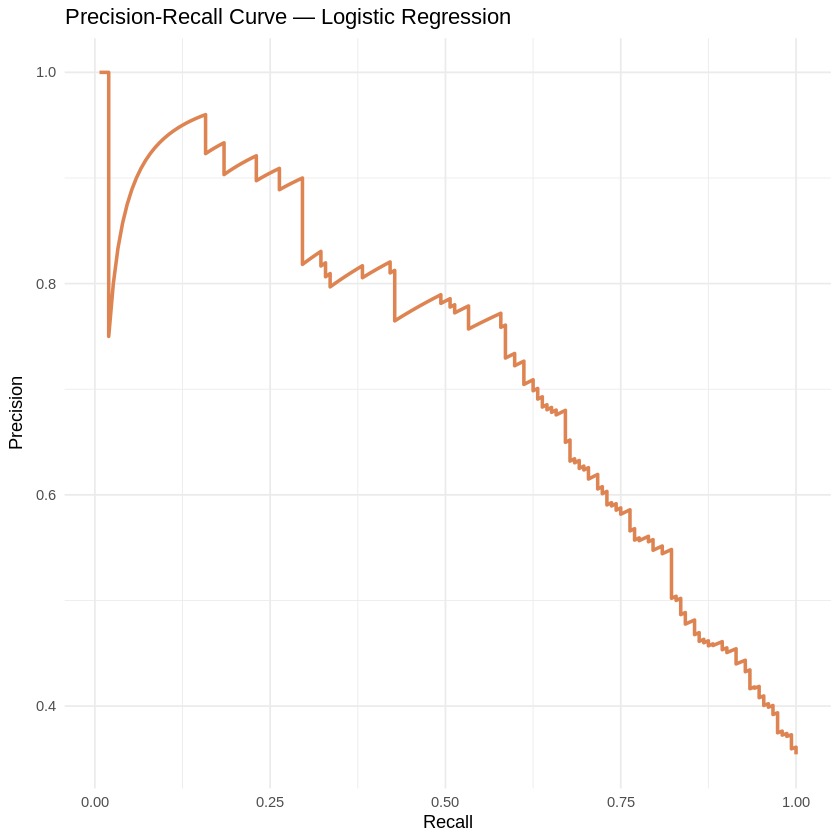

In [ ]:
## ---- Precision-Recall curve --------------------------------------------------
pr_log <- pr_curve_data(test_set$diagnosis, log_prob_test)
ggplot(pr_log, aes(x = recall, y = precision)) +
  geom_line(color = "#DD8452", linewidth = 1) +
  labs(title = "Precision-Recall Curve — Logistic Regression", x = "Recall", y = "Precision") +
  theme_minimal()


In [ ]:
## ---- Train / Validation / Test comparison table -------------------------------
get_acc_log <- function(model, data, threshold = 0.5) {
  prob <- predict(model, newdata = data, type = "response")
  pred <- factor(ifelse(prob > threshold, "Yes", "No"), levels = levels(data$diagnosis))
  mean(pred == data$diagnosis)
}
log_acc_table <- data.frame(
  Set = c("Train", "Validation", "Test"),
  Accuracy = round(c(get_acc_log(log_model, train_set),
                      get_acc_log(log_model, val_set),
                      get_acc_log(log_model, test_set)), 4)
)
cat("\n================ LOGISTIC REGRESSION — TRAIN/VAL/TEST ================\n")
print(log_acc_table, row.names = FALSE)

gap_log <- log_acc_table$Accuracy[1] - log_acc_table$Accuracy[2]
cat(if (gap_log > 0.10) {
  sprintf("Gap (train-val) = %.3f -> signs of OVERFITTING.\n", gap_log)
} else if (all(log_acc_table$Accuracy < 0.65)) {
  "All three sets weak -> signs of UNDERFITTING.\n"
} else {
  "Train/Val/Test are close -> good generalization.\n"
})



================ LOGISTIC REGRESSION — TRAIN/VAL/TEST ================
        Set Accuracy
      Train   0.7837
 Validation   0.7791
       Test   0.7762
Train/Val/Test are close -> good generalization.


Regularized logistic regression (glmnet) with grid search over alpha/lambda via 5-fold CV

In [ ]:
x_train <- model.matrix(diagnosis ~ . - 1, data = train_set)  # dummy-encode factors
y_train <- train_set$diagnosis

## (a) Grid search via caret::train (5-fold CV) over alpha and lambda
glmnet_grid <- expand.grid(alpha = c(0, 0.5, 1), lambda = 10^seq(-3, 0, length = 10))
glmnet_tuned <- train(diagnosis ~ ., data = train_set, method = "glmnet",
                       trControl = trainControl(method = "cv", number = 5),
                       tuneGrid = glmnet_grid, family = "binomial")
cat("\n================ LOGISTIC REGRESSION — GRID SEARCH (glmnet, caret::train) ================\n")
print(glmnet_tuned$bestTune)
cat("Best CV Accuracy:", round(max(glmnet_tuned$results$Accuracy), 4), "\n")


================ LOGISTIC REGRESSION — GRID SEARCH (glmnet, caret::train) ================
   alpha     lambda
25     1 0.02154435
Best CV Accuracy: 0.7868 


**An Alzheimer's clinical dataset:**  EDA → descriptive stats → outlier/normality checks → hypothesis tests (t-tests, ANOVA, MANOVA) → sampling methods → correlation/PCA → feature engineering → missing-data imputation comparison → train/val/test split → regression (MMSE) → classification (diagnosis) → hyperparameter tuning/diagnostics.


| Model | Accuracy | Precision | Recall | F1 |
| --- | --- | --- | --- | --- |
| Random Forest | 0.840 | 0.888 | 0.627 | 0.735 |
| Decision Tree | 0.843 | 0.964 | 0.579 | 0.723 |
| Logistic Regression | 0.783 | 0.708 | 0.658 | 0.682 |
| KNN (k=5) | 0.778 | 0.714 | 0.623 | 0.665 |

AUC (only computed for two models): Decision Tree 0.829 vs. Logistic Regression 0.805.

Random Forest is the best overall choice — it has the highest F1 (best precision/recall balance) and near-top accuracy. The Decision Tree has slightly higher raw accuracy and much higher precision, but its recall (0.579) is weak — meaning it misses more actual Alzheimer's cases, which matters more in a clinical/diagnostic setting where false negatives are costly. Logistic Regression and KNN both trail on every metric.
